In [5]:
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.impute import SimpleImputer

In [6]:
# Load with MultiIndex headers (two rows of headers)
# When loading the pickle, check shape and head immediately
with open('../data/processed/seera_cleaned.pkl', 'rb') as f:
    df_clean = pd.read_pickle(f)

print("Shape:", df_clean.shape)
print("Column levels:", df_clean.columns.nlevels)
print("Head:\n", df_clean.head(2))

print("Dataset loaded successfully!")
print(f"Shape: {df_clean.shape} rows x {df_clean.shape[1]} columns")

Shape: (119, 52)
Column levels: 2
Head:
   General Information                                       \
      Year of project Organization id Size of organization   
0                2015               1                   16   
1                2016              25                    2   

                                                              \
  Size of IT department Estimated  duration Development type   
0                     7                 2.0                1   
1                     1                 2.0                1   

                              Size        Effort       Environment  ...  \
  Application domain Object points Actual effort Contract maturity  ...   
0                  7         100.0        3168.0                 8  ...   
1                  3          19.0        1584.0                 4  ...   

                    Project                                         \
  Degree of risk management Use of standards Process reengineering   
0           

In [7]:
import numpy as np
import pandas as pd
import smogn

np.random.seed(42)

test_df = pd.DataFrame({
    "feature_1": np.random.rand(50),
    "feature_2": np.random.randint(1, 6, 50),
    "Effort": np.concatenate([
        np.random.uniform(100, 2000, 45),
        np.random.uniform(15000, 40000, 5)
    ])
})

print("Before:")
print(test_df["Effort"].describe())

smogn_test = smogn.smoter(
    data=test_df,
    y="Effort",
    k=5,
    pert=0.02,
    samp_method="balance",
    under_samp=True,
    drop_na_col=False,
    drop_na_row=False,
    replace=False,
    rel_thres=0.8,
    rel_method="auto",
    rel_xtrm_type="both",
    rel_coef=1.5,
    rel_ctrl_pts_rg=None,
    seed=42
)

print("\nAfter:")
print(smogn_test["Effort"].describe())

print(
    f"\nRows before: {len(test_df)}"
)

print(
    f"Rows after: {len(smogn_test)}"
)

Before:
count       50.000000
mean      3123.175933
std       6678.892457
min        100.988716
25%        569.511323
50%       1012.190185
75%       1466.029440
max      28952.550050
Name: Effort, dtype: float64


dist_matrix:   0%|          | 0/12 [00:00<?, ?it/s]

r_index: 100%|##########| 1/1 [00:00<00:00, 440.44it/s]


After:
count       38.000000
mean      7114.294837
std       9921.220718
min        310.692560
25%       1249.951463
50%       1782.767098
75%      12961.340400
max      28952.550050
Name: Effort, dtype: float64

Rows before: 50
Rows after: 38


<h2>Spliting the dataset </h2>

In [39]:
# ============================================================
# 1. SANITIZE COLUMN NAMES
# ============================================================

if isinstance(df_clean.columns, pd.MultiIndex):
    df_clean.columns = [
        "_".join(str(x).strip() for x in col if str(x).strip() != "")
        for col in df_clean.columns
    ]

df_clean.columns = (
    df_clean.columns
    .astype(str)
    .str.replace("\xa0", " ", regex=False)
    .str.strip()
)

# Remove duplicate columns
df_clean = df_clean.loc[
    :, ~df_clean.columns.duplicated()
].copy()

In [40]:

# ============================================================
# 2. DEFINE TARGET, GROUP, AND ID
# ============================================================

target_col = 'Effort_Actual effort'
group_col = 'General Information_Organization id'

# Your cleaned dataset does not contain ProjID,
# so we do not require it.
id_col = 'General Information_ProjID'


# Check required columns
if target_col not in df_clean.columns:
    raise KeyError(
        f"Target column not found: {target_col}"
    )

if group_col not in df_clean.columns:
    raise KeyError(
        f"Organization column not found: {group_col}"
    )

In [42]:
# ============================================================
# 3. TARGET
# ============================================================

y = pd.to_numeric(
    df_clean[target_col],
    errors='coerce'
)

# Remove rows where target is missing
valid_rows = y.notna()

df_clean = df_clean.loc[valid_rows].copy()
y = y.loc[valid_rows].reset_index(drop=True)

# Log-transform target
y_log = np.log1p(y)

In [43]:
# ============================================================
# 4. GROUPS
# ============================================================

groups = df_clean[group_col].reset_index(drop=True)

# Make sure groups contain no missing values
if groups.isna().any():
    raise ValueError(
        "Organization ID contains missing values."
    )

In [44]:

# ============================================================
# 5. BUILD FEATURE MATRIX
# ============================================================

cols_to_drop = [
    target_col,
    group_col
]

# Drop project ID only if it actually exists
if id_col in df_clean.columns:
    cols_to_drop.append(id_col)

X = df_clean.drop(
    columns=cols_to_drop
).copy()

In [45]:
# ============================================================
# 6. DEFINE CATEGORICAL FEATURES
# ============================================================

nominal_cat_cols = [
    'Developers_Team selection',
    'Developers_DBMS  expert availability',
    'General Information_Development type',
    'General Information_Application domain',
    'Environment_Government policy impact',
    'Environment_Developer hiring policy',
    'Environment_Developer training'
]

# Only keep columns that actually exist
nominal_cat_cols = [
    col for col in nominal_cat_cols
    if col in X.columns
]

In [46]:

# ============================================================
# 7. CONVERT CATEGORICAL FEATURES
# ============================================================

for col in nominal_cat_cols:

    X[col] = (
        X[col]
        .fillna('Missing')
        .astype(str)
        .str.replace(r'\.0$', '', regex=True)
    )


In [47]:
# ============================================================
# 8. CONVERT NUMERIC / ORDINAL FEATURES
# ============================================================

numeric_cols = [
    col for col in X.columns
    if col not in nominal_cat_cols
]

for col in numeric_cols:

    X[col] = pd.to_numeric(
        X[col],
        errors='coerce'
    )


# CatBoost can handle numeric NaN values.
# But make sure categorical columns contain no NaN.
for col in nominal_cat_cols:

    if X[col].isna().any():
        X[col] = X[col].fillna('Missing')

In [48]:
# ============================================================
# 9. CATBOOST CATEGORICAL COLUMN INDICES
# ============================================================

cat_indices = [
    X.columns.get_loc(col)
    for col in nominal_cat_cols
]


print("==========================================")
print("DATASET INFORMATION")
print("==========================================")
print(f"Projects:       {len(X)}")
print(f"Features:       {X.shape[1]}")
print(f"Organizations:  {groups.nunique()}")
print(f"Categorical:    {len(nominal_cat_cols)}")
print("==========================================")

DATASET INFORMATION
Projects:       119
Features:       50
Organizations:  41
Categorical:    7


In [ ]:
# ============================================================
# 10. HYPERPARAMETER SEARCH SPACE
# ============================================================

param_grid = [

    {
        'depth': 4,
        'learning_rate': 0.03,
        'iterations': 800,
        'l2_leaf_reg': 3
    },

    {
        'depth': 4,
        'learning_rate': 0.05,
        'iterations': 500,
        'l2_leaf_reg': 10
    },

    {
        'depth': 5,
        'learning_rate': 0.03,
        'iterations': 800,
        'l2_leaf_reg': 3
    },

    {
        'depth': 5,
        'learning_rate': 0.05,
        'iterations': 500,
        'l2_leaf_reg': 10
    },

    {
        'depth': 6,
        'learning_rate': 0.03,
        'iterations': 800,
        'l2_leaf_reg': 3
    },

    {
        'depth': 6,
        'learning_rate': 0.05,
        'iterations': 500,
        'l2_leaf_reg': 3
    },

    {
        'depth': 6,
        'learning_rate': 0.05,
        'iterations': 800,
        'l2_leaf_reg': 10
    },

    {
        'depth': 7,
        'learning_rate': 0.03,
        'iterations': 800,
        'l2_leaf_reg': 10
    },

    {
        'depth': 7,
        'learning_rate': 0.05,
        'iterations': 500,
        'l2_leaf_reg': 10
    },

    {
        'depth': 8,
        'learning_rate': 0.03,
        'iterations': 800,
        'l2_leaf_reg': 10
    }
]



In [ ]:
# ============================================================
# 11. OUTER LOGO-CV
# ============================================================

outer_logo = LeaveOneGroupOut()

all_y_true = []
all_predictions = []

selected_parameters = []

print("\n==========================================")
print("STARTING NESTED LOGO-CV")
print("==========================================")

outer_fold = 0


for train_idx, test_idx in outer_logo.split(
    X,
    y_log,
    groups
):

    outer_fold += 1

    print(
        f"\nOuter Fold {outer_fold}/{groups.nunique()}"
    )

    # --------------------------------------------------------
    # OUTER TRAIN / TEST
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx].copy()
    X_outer_test = X.iloc[test_idx].copy()

    y_outer_train = y_log.iloc[train_idx].copy()
    y_outer_test = y_log.iloc[test_idx].copy()

    groups_outer_train = groups.iloc[train_idx].copy()


    # ========================================================
    # 12. INNER LOGO-CV FOR HYPERPARAMETER TUNING
    # ========================================================

    inner_logo = LeaveOneGroupOut()

    best_score = np.inf
    best_params = None


    for params in param_grid:

        inner_true = []
        inner_pred = []


        for inner_train_idx, inner_val_idx in inner_logo.split(
            X_outer_train,
            y_outer_train,
            groups_outer_train
        ):

            X_inner_train = X_outer_train.iloc[
                inner_train_idx
            ]

            X_inner_val = X_outer_train.iloc[
                inner_val_idx
            ]

            y_inner_train = y_outer_train.iloc[
                inner_train_idx
            ]

            y_inner_val = y_outer_train.iloc[
                inner_val_idx
            ]


            # ------------------------------------------------
            # TRAIN MODEL
            # ------------------------------------------------

            model = CatBoostRegressor(

                iterations=params['iterations'],

                learning_rate=params['learning_rate'],

                depth=params['depth'],

                l2_leaf_reg=params['l2_leaf_reg'],

                cat_features=cat_indices,

                loss_function='RMSE',

                random_seed=42,

                verbose=0
            )


            model.fit(
                X_inner_train,
                y_inner_train
            )


            # ------------------------------------------------
            # PREDICT
            # ------------------------------------------------

            pred_log = model.predict(
                X_inner_val
            )

            pred = np.clip(
                np.expm1(pred_log),
                a_min=0,
                a_max=None
            )

            true = np.expm1(
                y_inner_val
            )


            inner_true.extend(true)
            inner_pred.extend(pred)


        # ====================================================
        # CALCULATE INNER MMRE
        # ====================================================

        inner_true = np.array(inner_true)
        inner_pred = np.array(inner_pred)

        inner_mre = (
            np.abs(inner_true - inner_pred)
            / inner_true
        )

        inner_mmre = np.mean(inner_mre)


        # ====================================================
        # KEEP BEST PARAMETERS
        # ====================================================

        if inner_mmre < best_score:

            best_score = inner_mmre
            best_params = params.copy()


In [ ]:
    # ========================================================
    # 13. TRAIN FINAL MODEL FOR THIS OUTER FOLD
    # ========================================================

    print(
        f"Best parameters: {best_params}"
    )

    print(
        f"Inner MMRE: {best_score:.4f}"
    )


    final_model = CatBoostRegressor(

        iterations=best_params['iterations'],

        learning_rate=best_params['learning_rate'],

        depth=best_params['depth'],

        l2_leaf_reg=best_params['l2_leaf_reg'],

        cat_features=cat_indices,

        loss_function='RMSE',

        random_seed=42,

        verbose=0
    )


    final_model.fit(
        X_outer_train,
        y_outer_train
    )


In [11]:
import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, r2_score


# ============================================================
# 1. DATA
# ============================================================

target_col = 'Effort_Actual effort'
group_col = 'General Information_Organization id'
id_col = 'General Information_ProjID'

y = pd.to_numeric(
    df_clean[target_col],
    errors='coerce'
)

valid_rows = y.notna()

df = df_clean.loc[valid_rows].copy()

y = y.loc[valid_rows].reset_index(drop=True)

groups = (
    df[group_col]
    .reset_index(drop=True)
)


# ============================================================
# 2. FEATURES
# ============================================================

cols_to_drop = [
    target_col,
    group_col
]

if id_col in df.columns:
    cols_to_drop.append(id_col)

X = df.drop(
    columns=cols_to_drop
).copy()


# ============================================================
# 3. CATEGORICAL FEATURES
# ============================================================

nominal_cat_cols = [
    'Developers_Team selection',
    'Developers_DBMS  expert availability',
    'General Information_Development type',
    'General Information_Application domain',
    'Environment_Government policy impact',
    'Environment_Developer hiring policy',
    'Environment_Developer training'
]

nominal_cat_cols = [
    col for col in nominal_cat_cols
    if col in X.columns
]


# Convert categorical columns
for col in nominal_cat_cols:

    X[col] = (
        X[col]
        .fillna('Missing')
        .astype(str)
        .str.replace(
            r'\.0$',
            '',
            regex=True
        )
    )


# Convert numerical columns
numeric_cols = [
    col for col in X.columns
    if col not in nominal_cat_cols
]

for col in numeric_cols:

    X[col] = pd.to_numeric(
        X[col],
        errors='coerce'
    )


# CatBoost categorical indices
cat_indices = [
    X.columns.get_loc(col)
    for col in nominal_cat_cols
]


# ============================================================
# 4. LOG TRANSFORMATION
# ============================================================

y_log = np.log1p(y)


# ============================================================
# 5. HYPERPARAMETER CONFIGURATIONS
# ============================================================

param_grid = [

    {
        'depth': 4,
        'learning_rate': 0.03,
        'iterations': 500,
        'l2_leaf_reg': 3
    },

    {
        'depth': 5,
        'learning_rate': 0.03,
        'iterations': 500,
        'l2_leaf_reg': 3
    },

    {
        'depth': 6,
        'learning_rate': 0.03,
        'iterations': 500,
        'l2_leaf_reg': 3
    },

    {
        'depth': 7,
        'learning_rate': 0.03,
        'iterations': 500,
        'l2_leaf_reg': 3
    },

    {
        'depth': 6,
        'learning_rate': 0.05,
        'iterations': 500,
        'l2_leaf_reg': 3
    },

    {
        'depth': 6,
        'learning_rate': 0.05,
        'iterations': 500,
        'l2_leaf_reg': 10
    },

    {
        'depth': 5,
        'learning_rate': 0.05,
        'iterations': 500,
        'l2_leaf_reg': 10
    },

    {
        'depth': 7,
        'learning_rate': 0.05,
        'iterations': 500,
        'l2_leaf_reg': 10
    }
]


# ============================================================
# 6. LOGO-CV
# ============================================================

logo = LeaveOneGroupOut()

results = []


# ============================================================
# 7. TEST EACH PARAMETER CONFIGURATION
# ============================================================

for config_number, params in enumerate(
    param_grid,
    start=1
):

    print("\n==========================================")
    print(
        f"Configuration {config_number}"
        f"/{len(param_grid)}"
    )
    print(params)
    print("==========================================")


    all_true = []
    all_pred = []


    for fold, (train_idx, test_idx) in enumerate(
        logo.split(X, y_log, groups),
        start=1
    ):

        print(
            f"Fold {fold}/{groups.nunique()}",
            end="\r"
        )


        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y_log.iloc[train_idx]


        # ----------------------------------------------------
        # MODEL
        # ----------------------------------------------------

        model = CatBoostRegressor(

            iterations=params['iterations'],

            learning_rate=params['learning_rate'],

            depth=params['depth'],

            l2_leaf_reg=params['l2_leaf_reg'],

            cat_features=cat_indices,

            loss_function='RMSE',

            random_seed=42,

            verbose=0,

            thread_count=-1
        )


        # ----------------------------------------------------
        # TRAIN
        # ----------------------------------------------------

        model.fit(
            X_train,
            y_train
        )


        # ----------------------------------------------------
        # PREDICT
        # ----------------------------------------------------

        pred_log = model.predict(
            X_test
        )

        pred = np.clip(
            np.expm1(pred_log),
            a_min=0,
            a_max=None
        )

        true = y.iloc[test_idx]


        all_true.extend(true)
        all_pred.extend(pred)


    # ========================================================
    # METRICS
    # ========================================================

    all_true = np.array(all_true)
    all_pred = np.array(all_pred)

    mre = (
        np.abs(all_true - all_pred)
        / all_true
    )

    mmre = np.mean(mre)

    mdmre = np.median(mre)

    pred25 = np.mean(
        mre <= 0.25
    )

    mae = mean_absolute_error(
        all_true,
        all_pred
    )

    r2 = r2_score(
        all_true,
        all_pred
    )


    # ========================================================
    # SAVE RESULT
    # ========================================================

    results.append({

        'depth':
            params['depth'],

        'learning_rate':
            params['learning_rate'],

        'iterations':
            params['iterations'],

        'l2_leaf_reg':
            params['l2_leaf_reg'],

        'MMRE':
            mmre,

        'MdMRE':
            mdmre,

        'PRED25':
            pred25,

        'MAE':
            mae,

        'R2':
            r2
    })


    print(
        f"\nMMRE: {mmre:.4f}"
    )

    print(
        f"MdMRE: {mdmre:.4f}"
    )

    print(
        f"PRED(25): {pred25 * 100:.2f}%"
    )

    print(
        f"MAE: {mae:.2f}"
    )

    print(
        f"R²: {r2:.4f}"
    )


# ============================================================
# 8. RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(results)


# Sort by MMRE
results_df = results_df.sort_values(
    by='MMRE'
).reset_index(drop=True)


print("\n==========================================")
print("HYPERPARAMETER TUNING RESULTS")
print("==========================================")

print(
    results_df.to_string(
        index=False
    )
)


# ============================================================
# 9. BEST CONFIGURATION
# ============================================================

best = results_df.iloc[0]

print("\n==========================================")
print("BEST CONFIGURATION")
print("==========================================")

print(
    f"Depth:          {best['depth']}"
)

print(
    f"Learning rate:  {best['learning_rate']}"
)

print(
    f"Iterations:     {best['iterations']}"
)

print(
    f"L2 regularization: {best['l2_leaf_reg']}"
)

print("------------------------------------------")

print(
    f"MMRE:           {best['MMRE']:.4f}"
)

print(
    f"MdMRE:          {best['MdMRE']:.4f}"
)

print(
    f"PRED(25):       {best['PRED25'] * 100:.2f}%"
)

print(
    f"MAE:            {best['MAE']:.2f}"
)

print(
    f"R²:             {best['R2']:.4f}"
)

print("==========================================")


Configuration 1/8
{'depth': 4, 'learning_rate': 0.03, 'iterations': 500, 'l2_leaf_reg': 3}


KeyboardInterrupt: 

In [15]:
import numpy as np
import pandas as pd
import optuna

from catboost import CatBoostRegressor
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, r2_score


# ============================================================
# 1. SETTINGS
# ============================================================

RANDOM_SEED = 42

# Number of Optuna trials
N_TRIALS = 12

# Number of folds ONLY during tuning
TUNING_FOLDS = 5

optuna.logging.set_verbosity(optuna.logging.WARNING)


# ============================================================
# 2. DATA PREPARATION
# ============================================================

target_col = 'Effort_Actual effort'
group_col = 'General Information_Organization id'
id_col = 'General Information_ProjID'


# Target
y = pd.to_numeric(
    df_clean[target_col],
    errors='coerce'
)


# Remove rows with missing target
valid_rows = y.notna()

df = df_clean.loc[valid_rows].copy()

y = y.loc[valid_rows].reset_index(drop=True)

groups = (
    df[group_col]
    .reset_index(drop=True)
)


# ============================================================
# 3. FEATURES
# ============================================================

cols_to_drop = [
    target_col,
    group_col
]

if id_col in df.columns:
    cols_to_drop.append(id_col)


X = df.drop(
    columns=cols_to_drop
).copy()


# ============================================================
# 4. CATEGORICAL FEATURES
# ============================================================

nominal_cat_cols = [
    'Developers_Team selection',
    'Developers_DBMS expert availability',
    'General Information_Development type',
    'General Information_Application domain',
    'Environment_Government policy impact',
    'Environment_Developer hiring policy',
    'Environment_Developer training'
]


nominal_cat_cols = [
    col
    for col in nominal_cat_cols
    if col in X.columns
]


# Convert categorical variables to strings
for col in nominal_cat_cols:

    X[col] = (
        X[col]
        .fillna('Missing')
        .astype(str)
        .str.replace(
            r'\.0$',
            '',
            regex=True
        )
    )


# ============================================================
# 5. NUMERIC FEATURES
# ============================================================

numeric_cols = [
    col
    for col in X.columns
    if col not in nominal_cat_cols
]


for col in numeric_cols:

    X[col] = pd.to_numeric(
        X[col],
        errors='coerce'
    )

    # CatBoost can handle numeric NaN values.
    # We intentionally DO NOT fill them with zero.
    

# CatBoost categorical feature indices
cat_indices = [
    X.columns.get_loc(col)
    for col in nominal_cat_cols
]


# ============================================================
# 6. TARGET TRANSFORMATION
# ============================================================

y_log = np.log1p(y)


# ============================================================
# 7. GROUP-AWARE CV FOR TUNING
# ============================================================

# IMPORTANT:
# Organizations are kept together.
#
# This prevents projects from the same organization
# appearing in both training and validation folds.

gkf = GroupKFold(
    n_splits=TUNING_FOLDS
)


# ============================================================
# 8. OPTUNA OBJECTIVE
# ============================================================

def objective(trial):

    # --------------------------------------------------------
    # Hyperparameters
    # --------------------------------------------------------

    params = {

        # Based on previous experiment:
        # depth 4-7 was tested and depth 5 performed best.
        'depth': trial.suggest_int(
            'depth',
            3,
            6
        ),

        # Focus around the successful 0.03-0.05 region
        'learning_rate': trial.suggest_float(
            'learning_rate',
            0.01,
            0.08,
            log=True
        ),

        # Allow early stopping to determine useful number
        # of iterations.
        'iterations': trial.suggest_int(
            'iterations',
            300,
            1000,
            step=100
        ),

        # Previous best = 10
        'l2_leaf_reg': trial.suggest_float(
            'l2_leaf_reg',
            5,
            20,
            log=True
        ),

        # Additional regularization parameter
        'random_strength': trial.suggest_float(
            'random_strength',
            0.1,
            3.0,
            log=True
        ),

        # Controls Bayesian bootstrap randomness
        'bagging_temperature': trial.suggest_float(
            'bagging_temperature',
            0.5,
            2
        )
    }


    # --------------------------------------------------------
    # Storage for predictions
    # --------------------------------------------------------

    all_true = []
    all_pred = []


    # --------------------------------------------------------
    # Group-aware CV
    # --------------------------------------------------------

    for train_idx, valid_idx in gkf.split(
        X,
        y_log,
        groups
    ):

        X_train = X.iloc[train_idx]
        X_valid = X.iloc[valid_idx]

        y_train = y_log.iloc[train_idx]
        y_valid = y_log.iloc[valid_idx]


        # ----------------------------------------------------
        # CatBoost
        # ----------------------------------------------------

        model = CatBoostRegressor(

            iterations=params['iterations'],

            learning_rate=params['learning_rate'],

            depth=params['depth'],

            l2_leaf_reg=params['l2_leaf_reg'],

            random_strength=params['random_strength'],

            bagging_temperature=params[
                'bagging_temperature'
            ],

            cat_features=cat_indices,

            loss_function='MAPE',

            random_seed=RANDOM_SEED,

            # Early stopping
            od_type='Iter',

            od_wait=50,

            # Use CPU efficiently
            thread_count=-1,

            verbose=False,

            # Prevent CatBoost from creating files
            allow_writing_files=False
        )


        # ----------------------------------------------------
        # Train
        # ----------------------------------------------------

        model.fit(
            X_train,
            y_train,

            eval_set=(
                X_valid,
                y_valid
            ),

            use_best_model=True
        )


        # ----------------------------------------------------
        # Predict
        # ----------------------------------------------------

        pred_log = model.predict(
            X_valid
        )


        pred = np.clip(
            np.expm1(pred_log),
            a_min=0,
            a_max=None
        )


        true = y.iloc[valid_idx]


        all_true.extend(
            true.to_numpy()
        )

        all_pred.extend(
            pred
        )


    # ========================================================
    # METRICS
    # ========================================================

    all_true = np.array(
        all_true
    )

    all_pred = np.array(
        all_pred
    )


    # MRE
    mre = (
        np.abs(
            all_true - all_pred
        )
        / all_true
    )


    # Main objective
    mmre = np.mean(
        mre
    )


    # Secondary metrics
    mdmre = np.median(
        mre
    )

    pred25 = np.mean(
        mre <= 0.25
    )

    mae = mean_absolute_error(
        all_true,
        all_pred
    )

    r2 = r2_score(
        all_true,
        all_pred
    )


    # Save secondary metrics
    trial.set_user_attr(
        'MdMRE',
        mdmre
    )

    trial.set_user_attr(
        'PRED25',
        pred25
    )

    trial.set_user_attr(
        'MAE',
        mae
    )

    trial.set_user_attr(
        'R2',
        r2
    )


    # Return MMRE
    return mmre


# ============================================================
# 9. CREATE OPTUNA STUDY
# ============================================================

study = optuna.create_study(

    direction='minimize',

    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_SEED
    )
)


# ============================================================
# 10. RUN TUNING
# ============================================================

print(
    f"Starting Optuna tuning:"
)

print(
    f"{N_TRIALS} trials × "
    f"{TUNING_FOLDS} group-aware folds"
)

print(
    "This is ONLY the tuning stage."
)


study.optimize(
    objective,

    n_trials=N_TRIALS,

    show_progress_bar=True
)


# ============================================================
# 11. BEST RESULT
# ============================================================

best_trial = study.best_trial


print("\n")
print("=" * 55)
print("        BEST OPTUNA CONFIGURATION")
print("=" * 55)


print(
    f"Trial:       {best_trial.number}"
)

print(
    f"MMRE:        {best_trial.value:.4f}"
)


print("-" * 55)


for param, value in best_trial.params.items():

    print(
        f"{param:<22}: {value}"
    )


print("-" * 55)


print(
    f"MdMRE:       "
    f"{best_trial.user_attrs['MdMRE']:.4f}"
)

print(
    f"PRED(25):    "
    f"{best_trial.user_attrs['PRED25'] * 100:.2f}%"
)

print(
    f"MAE:         "
    f"{best_trial.user_attrs['MAE']:.2f}"
)

print(
    f"R²:          "
    f"{best_trial.user_attrs['R2']:.4f}"
)


print("=" * 55)

Starting Optuna tuning:
12 trials × 5 group-aware folds
This is ONLY the tuning stage.


  0%|          | 0/12 [00:00<?, ?it/s]



        BEST OPTUNA CONFIGURATION
Trial:       11
MMRE:        0.5113
-------------------------------------------------------
depth                 : 3
learning_rate         : 0.04124173274946173
iterations            : 600
l2_leaf_reg           : 13.500717070418117
random_strength       : 0.41882193959396974
bagging_temperature   : 1.9187145799605694
-------------------------------------------------------
MdMRE:       0.3415
PRED(25):    42.02%
MAE:         3994.96
R²:          0.4325


<h2>Final trial: full LOGO with parameters optained from optuna </h2>

In [16]:
import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, r2_score


# ============================================================
# FINAL CATBOOST EVALUATION
# FROZEN OPTUNA CONFIGURATION + FULL LOGO-CV
# ============================================================

RANDOM_SEED = 42


# ============================================================
# 1. COLUMN DEFINITIONS
# ============================================================

target_col = 'Effort_Actual effort'
group_col = 'General Information_Organization id'
id_col = 'General Information_ProjID'


# ============================================================
# 2. DATA PREPARATION
# ============================================================

# Convert target to numeric
y = pd.to_numeric(
    df_clean[target_col],
    errors='coerce'
)

# Remove rows where target is missing
valid_rows = y.notna()

df = df_clean.loc[valid_rows].copy()

y = y.loc[valid_rows].reset_index(drop=True)

groups = (
    df[group_col]
    .reset_index(drop=True)
)


# ============================================================
# 3. FEATURES
# ============================================================

# Target and organization ID must NOT be predictors.
# Project ID is also excluded if present.

cols_to_drop = [
    target_col,
    group_col
]

if id_col in df.columns:
    cols_to_drop.append(id_col)

X = df.drop(
    columns=cols_to_drop
).copy()


# ============================================================
# 4. CATEGORICAL FEATURES
# ============================================================

nominal_cat_cols = [
    'Developers_Team selection',
    'Developers_DBMS expert availability',
    'General Information_Development type',
    'General Information_Application domain',
    'Environment_Government policy impact',
    'Environment_Developer hiring policy',
    'Environment_Developer training'
]

# Keep only categorical columns that actually exist
nominal_cat_cols = [
    col
    for col in nominal_cat_cols
    if col in X.columns
]


# Convert categorical values to strings
for col in nominal_cat_cols:

    X[col] = (
        X[col]
        .fillna('Missing')
        .astype(str)
        .str.replace(
            r'\.0$',
            '',
            regex=True
        )
    )


# ============================================================
# 5. NUMERICAL FEATURES
# ============================================================

numeric_cols = [
    col
    for col in X.columns
    if col not in nominal_cat_cols
]

for col in numeric_cols:

    X[col] = pd.to_numeric(
        X[col],
        errors='coerce'
    )


# CatBoost categorical feature indices
cat_indices = [
    X.columns.get_loc(col)
    for col in nominal_cat_cols
]


# ============================================================
# 6. TARGET TRANSFORMATION
# ============================================================

# Same transformation used during tuning
y_log = np.log1p(y)


# ============================================================
# 7. LOGO VALIDATION SETUP
# ============================================================

logo = LeaveOneGroupOut()

n_groups = groups.nunique()


print("=" * 65)
print("        FINAL CATBOOST LOGO EVALUATION")
print("=" * 65)

print(f"Observations:       {len(X)}")
print(f"Organizations:      {n_groups}")
print(f"Features:           {X.shape[1]}")
print(f"Categorical:        {len(cat_indices)}")
print("Validation:         Leave-One-Organization-Out")
print(f"Expected folds:     {n_groups}")


# ============================================================
# 8. FROZEN OPTUNA CONFIGURATION
# ============================================================

# Trial 11 — BEST OPTUNA CONFIGURATION

final_params = {
    'depth': 3,
    'learning_rate': 0.04124173274946173,
    'iterations': 600,
    'l2_leaf_reg': 13.500717070418117,
    'random_strength': 0.41882193959396974,
    'bagging_temperature': 1.9187145799605694
}


print("\n" + "-" * 65)
print("FROZEN OPTUNA PARAMETERS")
print("-" * 65)

for name, value in final_params.items():
    print(f"{name:<22}: {value}")


# ============================================================
# 9. STORAGE FOR OUT-OF-FOLD PREDICTIONS
# ============================================================

all_true = []
all_pred = []

prediction_records = []


# ============================================================
# 10. FULL LOGO CROSS-VALIDATION
# ============================================================

print("\n")
print("Starting final LOGO evaluation...")
print()


for fold, (train_idx, test_idx) in enumerate(
    logo.split(X, y_log, groups),
    start=1
):

    # --------------------------------------------------------
    # Split data
    # --------------------------------------------------------

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train_log = y_log.iloc[train_idx]

    true = y.iloc[test_idx].to_numpy()


    # --------------------------------------------------------
    # Create CatBoost model
    # --------------------------------------------------------

    model = CatBoostRegressor(

        # FROZEN OPTUNA PARAMETERS
        depth=final_params['depth'],
        learning_rate=final_params['learning_rate'],
        iterations=final_params['iterations'],
        l2_leaf_reg=final_params['l2_leaf_reg'],
        random_strength=final_params['random_strength'],
        bagging_temperature=final_params['bagging_temperature'],

        # Model settings
        cat_features=cat_indices,
        loss_function='RMSE',
        random_seed=RANDOM_SEED,

        # Use all available CPU threads
        thread_count=-1,

        # No training output
        verbose=False,

        # Prevent CatBoost from creating extra files
        allow_writing_files=False
    )


    # --------------------------------------------------------
    # Train on all organizations EXCEPT the held-out one
    # --------------------------------------------------------

    model.fit(
        X_train,
        y_train_log
    )


    # --------------------------------------------------------
    # Predict the held-out organization
    # --------------------------------------------------------

    pred_log = model.predict(
        X_test
    )


    # Convert prediction back from log scale
    pred = np.clip(
        np.expm1(pred_log),
        a_min=0,
        a_max=None
    )


    # --------------------------------------------------------
    # Store predictions
    # --------------------------------------------------------

    all_true.extend(true)
    all_pred.extend(pred)


    # --------------------------------------------------------
    # Store detailed project-level results
    # --------------------------------------------------------

    for i, original_idx in enumerate(test_idx):

        actual = true[i]
        predicted = pred[i]

        absolute_error = abs(
            actual - predicted
        )

        mre_value = (
            absolute_error / actual
        )

        prediction_records.append({
            'Fold': fold,
            'Organization_ID': groups.iloc[original_idx],
            'Actual_Effort': actual,
            'Predicted_Effort': predicted,
            'Absolute_Error': absolute_error,
            'MRE': mre_value
        })


    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    print(
        f"Fold {fold:>2}/{n_groups} completed"
    )


# ============================================================
# 11. CONVERT ALL PREDICTIONS TO ARRAYS
# ============================================================

y_true_arr = np.array(
    all_true
)

y_pred_arr = np.array(
    all_pred
)


# ============================================================
# 12. CALCULATE MRE
# ============================================================

mre = (
    np.abs(
        y_true_arr - y_pred_arr
    )
    / y_true_arr
)


# ============================================================
# 13. FINAL EVALUATION METRICS
# ============================================================

mae = mean_absolute_error(
    y_true_arr,
    y_pred_arr
)

r2 = r2_score(
    y_true_arr,
    y_pred_arr
)

mmre = np.mean(
    mre
)

mdmre = np.median(
    mre
)

pred25 = np.mean(
    mre <= 0.25
)


# ============================================================
# 14. FINAL RESULTS
# ============================================================

print("\n")
print("=" * 65)
print("       FINAL CATBOOST LOGO-CV RESULTS")
print("=" * 65)

print(
    f"MAE:       {mae:.2f} hours"
)

print(
    f"R²:        {r2:.4f}"
)

print(
    f"MMRE:      {mmre:.4f} ({mmre * 100:.2f}%)"
)

print(
    f"MdMRE:     {mdmre:.4f} ({mdmre * 100:.2f}%)"
)

print(
    f"PRED(25):  {pred25 * 100:.2f}%"
)

print("=" * 65)


# ============================================================
# 15. PROJECT-LEVEL PREDICTION TABLE
# ============================================================

predictions_df = pd.DataFrame(
    prediction_records
)


print("\nProject-level predictions created.")
print(
    f"Number of predictions: {len(predictions_df)}"
)

print("\nFirst 10 predictions:")
print(
    predictions_df.head(10)
)

        FINAL CATBOOST LOGO EVALUATION
Observations:       119
Organizations:      41
Features:           50
Categorical:        6
Validation:         Leave-One-Organization-Out
Expected folds:     41

-----------------------------------------------------------------
FROZEN OPTUNA PARAMETERS
-----------------------------------------------------------------
depth                 : 3
learning_rate         : 0.04124173274946173
iterations            : 600
l2_leaf_reg           : 13.500717070418117
random_strength       : 0.41882193959396974
bagging_temperature   : 1.9187145799605694


Starting final LOGO evaluation...

Fold  1/41 completed
Fold  2/41 completed
Fold  3/41 completed
Fold  4/41 completed
Fold  5/41 completed
Fold  6/41 completed
Fold  7/41 completed
Fold  8/41 completed
Fold  9/41 completed
Fold 10/41 completed
Fold 11/41 completed
Fold 12/41 completed
Fold 13/41 completed
Fold 14/41 completed
Fold 15/41 completed
Fold 16/41 completed
Fold 17/41 completed
Fold 18/41 complete

<h2>Error anlaysis: </h2>

In [17]:

# ============================================================
# ERROR ANALYSIS — FINAL CATBOOST MODEL
# Uses predictions_df from the final 41-fold LOGO evaluation
# ============================================================


# ------------------------------------------------------------
# 1. BASIC ERROR SUMMARY
# ------------------------------------------------------------

error_df = predictions_df.copy()

print("=" * 70)
print("                 ERROR ANALYSIS")
print("=" * 70)

print(f"Number of predictions: {len(error_df)}")


# ============================================================
# 2. ERROR CATEGORIES
# ============================================================

# Signed error:
# Positive = model OVERestimated
# Negative = model UNDERestimated

error_df['Signed_Error'] = (
    error_df['Predicted_Effort']
    - error_df['Actual_Effort']
)

# Percentage error
error_df['Percentage_Error'] = (
    error_df['Signed_Error']
    / error_df['Actual_Effort']
    * 100
)

# Absolute Percentage Error
error_df['Absolute_Percentage_Error'] = (
    error_df['MRE'] * 100
)


# ============================================================
# 3. OVERALL ERROR STATISTICS
# ============================================================

print("\n" + "=" * 70)
print("OVERALL ERROR STATISTICS")
print("=" * 70)

print(
    f"Mean Absolute Error:       "
    f"{error_df['Absolute_Error'].mean():.2f} hours"
)

print(
    f"Median Absolute Error:     "
    f"{error_df['Absolute_Error'].median():.2f} hours"
)

print(
    f"Mean MRE:                  "
    f"{error_df['MRE'].mean():.4f}"
)

print(
    f"Median MRE:                "
    f"{error_df['MRE'].median():.4f}"
)

print(
    f"Mean Signed Error:         "
    f"{error_df['Signed_Error'].mean():.2f} hours"
)

print(
    f"Median Signed Error:       "
    f"{error_df['Signed_Error'].median():.2f} hours"
)


# ============================================================
# 4. OVERALL DIRECTION OF ERRORS
# ============================================================

overestimated = (
    error_df['Signed_Error'] > 0
).sum()

underestimated = (
    error_df['Signed_Error'] < 0
).sum()

exact = (
    error_df['Signed_Error'] == 0
).sum()

print("\n" + "=" * 70)
print("ERROR DIRECTION")
print("=" * 70)

print(
    f"Overestimated projects:    "
    f"{overestimated} "
    f"({overestimated / len(error_df) * 100:.2f}%)"
)

print(
    f"Underestimated projects:   "
    f"{underestimated} "
    f"({underestimated / len(error_df) * 100:.2f}%)"
)

print(
    f"Exact predictions:         "
    f"{exact}"
)


# ============================================================
# 5. TOP 10 WORST PREDICTIONS
# ============================================================

worst_predictions = (
    error_df
    .sort_values(
        'MRE',
        ascending=False
    )
    .head(10)
)

print("\n" + "=" * 70)
print("TOP 10 WORST PREDICTIONS — BY MRE")
print("=" * 70)

print(
    worst_predictions[
        [
            'Fold',
            'Organization_ID',
            'Actual_Effort',
            'Predicted_Effort',
            'Absolute_Error',
            'MRE'
        ]
    ].to_string(index=False)
)


# ============================================================
# 6. TOP 10 LARGEST ABSOLUTE ERRORS
# ============================================================

largest_absolute_errors = (
    error_df
    .sort_values(
        'Absolute_Error',
        ascending=False
    )
    .head(10)
)

print("\n" + "=" * 70)
print("TOP 10 LARGEST ABSOLUTE ERRORS")
print("=" * 70)

print(
    largest_absolute_errors[
        [
            'Fold',
            'Organization_ID',
            'Actual_Effort',
            'Predicted_Effort',
            'Absolute_Error',
            'MRE'
        ]
    ].to_string(index=False)
)


# ============================================================
# 7. BEST PREDICTIONS
# ============================================================

best_predictions = (
    error_df
    .sort_values(
        'MRE',
        ascending=True
    )
    .head(10)
)

print("\n" + "=" * 70)
print("TOP 10 BEST PREDICTIONS — LOWEST MRE")
print("=" * 70)

print(
    best_predictions[
        [
            'Fold',
            'Organization_ID',
            'Actual_Effort',
            'Predicted_Effort',
            'Absolute_Error',
            'MRE'
        ]
    ].to_string(index=False)
)


# ============================================================
# 8. PREDICTION ACCURACY BANDS
# ============================================================

within_10 = (
    error_df['MRE'] <= 0.10
).sum()

within_25 = (
    error_df['MRE'] <= 0.25
).sum()

within_50 = (
    error_df['MRE'] <= 0.50
).sum()

over_50 = (
    error_df['MRE'] > 0.50
).sum()

over_100 = (
    error_df['MRE'] > 1.00
).sum()

print("\n" + "=" * 70)
print("PREDICTION ACCURACY BANDS")
print("=" * 70)

print(
    f"Within ±10%:               "
    f"{within_10}/{len(error_df)} "
    f"({within_10 / len(error_df) * 100:.2f}%)"
)

print(
    f"Within ±25%:               "
    f"{within_25}/{len(error_df)} "
    f"({within_25 / len(error_df) * 100:.2f}%)"
)

print(
    f"Within ±50%:               "
    f"{within_50}/{len(error_df)} "
    f"({within_50 / len(error_df) * 100:.2f}%)"
)

print(
    f"Error > 50%:               "
    f"{over_50}/{len(error_df)} "
    f"({over_50 / len(error_df) * 100:.2f}%)"
)

print(
    f"Error > 100%:              "
    f"{over_100}/{len(error_df)} "
    f"({over_100 / len(error_df) * 100:.2f}%)"
)


# ============================================================
# 9. ORGANIZATION-LEVEL ERROR ANALYSIS
# ============================================================

organization_analysis = (
    error_df
    .groupby('Organization_ID')
    .agg(
        Projects=('Actual_Effort', 'count'),
        Mean_Actual=('Actual_Effort', 'mean'),
        Mean_Predicted=('Predicted_Effort', 'mean'),
        MAE=('Absolute_Error', 'mean'),
        MMRE=('MRE', 'mean'),
        MdMRE=('MRE', 'median'),
        PRED25=('MRE', lambda x: (x <= 0.25).mean())
    )
    .reset_index()
)

print("\n" + "=" * 70)
print("ORGANIZATION-LEVEL ERROR ANALYSIS")
print("=" * 70)

print(
    organization_analysis
    .sort_values('MMRE', ascending=False)
    .to_string(index=False)
)


# ============================================================
# 10. ACTUAL EFFORT SIZE BANDS
# ============================================================

# Divide projects according to actual effort.
error_df['Effort_Size'] = pd.cut(
    error_df['Actual_Effort'],
    bins=[
        -np.inf,
        2000,
        5000,
        10000,
        np.inf
    ],
    labels=[
        '<= 2,000 hours',
        '2,001–5,000 hours',
        '5,001–10,000 hours',
        '> 10,000 hours'
    ]
)

size_analysis = (
    error_df
    .groupby(
        'Effort_Size',
        observed=True
    )
    .agg(
        Projects=('Actual_Effort', 'count'),
        Mean_Actual=('Actual_Effort', 'mean'),
        Mean_Predicted=('Predicted_Effort', 'mean'),
        MAE=('Absolute_Error', 'mean'),
        MMRE=('MRE', 'mean'),
        MdMRE=('MRE', 'median'),
        PRED25=('MRE', lambda x: (x <= 0.25).mean())
    )
    .reset_index()
)

print("\n" + "=" * 70)
print("ERROR BY ACTUAL EFFORT SIZE")
print("=" * 70)

print(
    size_analysis.to_string(index=False)
)


# ============================================================
# 11. UNDER/OVER ESTIMATION SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("UNDER/OVER ESTIMATION")
print("=" * 70)

print(
    f"Average signed error: "
    f"{error_df['Signed_Error'].mean():.2f} hours"
)

if error_df['Signed_Error'].mean() > 0:

    print(
        "Overall tendency: MODEL TENDS TO OVERESTIMATE"
    )

elif error_df['Signed_Error'].mean() < 0:

    print(
        "Overall tendency: MODEL TENDS TO UNDERESTIMATE"
    )

else:

    print(
        "Overall tendency: NO OVERALL BIAS"
    )


# ============================================================
# 12. SAVE COMPLETE ERROR ANALYSIS TABLE
# ============================================================

error_analysis_df = error_df.sort_values(
    'MRE',
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("ERROR ANALYSIS COMPLETE")
print("=" * 70)

print(
    "Available dataframe: error_analysis_df"
)

                 ERROR ANALYSIS
Number of predictions: 119

OVERALL ERROR STATISTICS
Mean Absolute Error:       4008.54 hours
Median Absolute Error:     1549.09 hours
Mean MRE:                  0.5477
Median MRE:                0.3304
Mean Signed Error:         -1880.99 hours
Median Signed Error:       86.41 hours

ERROR DIRECTION
Overestimated projects:    66 (55.46%)
Underestimated projects:   53 (44.54%)
Exact predictions:         0

TOP 10 WORST PREDICTIONS — BY MRE
 Fold  Organization_ID  Actual_Effort  Predicted_Effort  Absolute_Error      MRE
   28               29          704.0       4606.689172     3902.689172 5.543593
   11               11          924.0       4681.725780     3757.725780 4.066803
   11               11          924.0       4313.524954     3389.524954 3.668317
   13               13         1232.0       4165.569707     2933.569707 2.381144
   26               27         1936.0       6211.606355     4275.606355 2.208474
    5                5          577.5  

In [18]:
# Quick sanity check
test_val = y.iloc[0]
print(f"Original: {test_val}")
print(f"After log1p then expm1: {np.expm1(np.log1p(test_val))}")

Original: 3168.0
After log1p then expm1: 3167.999999999999


In [19]:
# ==========================================
# INVESTIGATE PROJECTS WITH MRE > 100%
# ==========================================

high_mre = error_analysis_df[error_analysis_df['MRE'] > 1.0].copy()
high_mre = high_mre.sort_values('MRE', ascending=False)

print("======================================================================")
print("         PROJECTS WITH MRE > 100%")
print("======================================================================")
print(f"Count: {len(high_mre)} projects\n")

print(high_mre[[
    'Fold', 'Organization_ID', 'Actual_Effort', 
    'Predicted_Effort', 'Absolute_Error', 'MRE'
]].to_string(index=False))

# ==========================================
# EFFORT SIZE DISTRIBUTION OF HIGH MRE
# ==========================================
print("\n======================================================================")
print("         EFFORT SIZE — ARE HIGH MRE PROJECTS SMALL?")
print("======================================================================")
bins   = [0, 1000, 2000, 5000, 10000, np.inf]
labels = ['<=1000', '1001-2000', '2001-5000', '5001-10000', '>10000']

high_mre['effort_band'] = pd.cut(
    high_mre['Actual_Effort'], bins=bins, labels=labels
)
print(high_mre['effort_band'].value_counts().sort_index())

# ==========================================
# ORGANIZATION PROFILE OF HIGH MRE
# ==========================================
print("\n======================================================================")
print("         WHICH ORGANIZATIONS APPEAR IN HIGH MRE?")
print("======================================================================")
org_counts = high_mre['Organization_ID'].value_counts()
print(org_counts)

print(f"\nUnique organizations affected: {high_mre['Organization_ID'].nunique()}")
print(f"Organization IDs: {sorted(high_mre['Organization_ID'].unique())}")

# ==========================================
# COMPARE HIGH MRE vs REST
# ==========================================
print("\n======================================================================")
print("         HIGH MRE vs REST — FEATURE COMPARISON")
print("======================================================================")

low_mre = error_analysis_df[error_analysis_df['MRE'] <= 1.0]

comparison = pd.DataFrame({
    'High_MRE_projects': [
        len(high_mre),
        high_mre['Actual_Effort'].mean(),
        high_mre['Actual_Effort'].median(),
        high_mre['Predicted_Effort'].mean(),
        high_mre['MRE'].mean(),
    ],
    'Rest_of_projects': [
        len(low_mre),
        low_mre['Actual_Effort'].mean(),
        low_mre['Actual_Effort'].median(),
        low_mre['Predicted_Effort'].mean(),
        low_mre['MRE'].mean(),
    ]
}, index=[
    'Count',
    'Mean Actual Effort',
    'Median Actual Effort',
    'Mean Predicted Effort',
    'Mean MRE'
])

print(comparison.round(2))

# ==========================================
# DIRECTION OF ERROR — ARE THEY ALL OVERESTIMATED?
# ==========================================
print("\n======================================================================")
print("         ERROR DIRECTION FOR HIGH MRE PROJECTS")
print("======================================================================")

high_mre['direction'] = np.where(
    high_mre['Predicted_Effort'] > high_mre['Actual_Effort'],
    'Overestimated',
    'Underestimated'
)

print(high_mre['direction'].value_counts())
print(f"\nMean actual effort:    {high_mre['Actual_Effort'].mean():.0f} hours")
print(f"Mean predicted effort: {high_mre['Predicted_Effort'].mean():.0f} hours")
print(f"Mean absolute error:   {high_mre['Absolute_Error'].mean():.0f} hours")

# ==========================================
# FOLD DISTRIBUTION — ANY PATTERN?
# ==========================================
print("\n======================================================================")
print("         FOLD DISTRIBUTION OF HIGH MRE PROJECTS")
print("======================================================================")
print(high_mre[['Fold', 'Organization_ID', 'Actual_Effort', 
                 'Predicted_Effort', 'MRE', 'direction']].to_string(index=False))

         PROJECTS WITH MRE > 100%
Count: 12 projects

 Fold  Organization_ID  Actual_Effort  Predicted_Effort  Absolute_Error      MRE
   28               29          704.0       4606.689172     3902.689172 5.543593
   11               11          924.0       4681.725780     3757.725780 4.066803
   11               11          924.0       4313.524954     3389.524954 3.668317
   13               13         1232.0       4165.569707     2933.569707 2.381144
   26               27         1936.0       6211.606355     4275.606355 2.208474
    5                5          577.5       1620.394917     1042.894917 1.805879
   41               45         2640.0       7005.362077     4365.362077 1.653546
   31               32          704.0       1811.024632     1107.024632 1.572478
    5                5         1584.0       3688.202283     2104.202283 1.328411
    5                5          528.0       1214.833728      686.833728 1.300821
    6                6         5346.0      11611.381888

<h2> Rerunning the model without the 12 peojects 

In [20]:
import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.stats import mannwhitneyu


# ============================================================
# FINAL CATBOOST EVALUATION
# FROZEN OPTUNA CONFIGURATION + FULL LOGO-CV
# ============================================================

RANDOM_SEED = 42


# ============================================================
# 1. COLUMN DEFINITIONS
# ============================================================

target_col = 'Effort_Actual effort'
group_col = 'General Information_Organization id'
id_col = 'General Information_ProjID'


# ============================================================
# 2. DATA PREPARATION
# ============================================================

# Convert target to numeric
y = pd.to_numeric(
    df_clean[target_col],
    errors='coerce'
)

# Remove rows where target is missing
valid_rows = y.notna()

df = df_clean.loc[valid_rows].copy()

y = y.loc[valid_rows].reset_index(drop=True)

groups = (
    df[group_col]
    .reset_index(drop=True)
)


# ============================================================
# 3. FEATURES
# ============================================================

# Target and organization ID must NOT be predictors.
# Project ID is also excluded if present.

cols_to_drop = [
    target_col,
    group_col
]

if id_col in df.columns:
    cols_to_drop.append(id_col)

X = df.drop(
    columns=cols_to_drop
).copy()


# ============================================================
# 4. CATEGORICAL FEATURES
# ============================================================

nominal_cat_cols = [
    'Developers_Team selection',
    'Developers_DBMS expert availability',
    'General Information_Development type',
    'General Information_Application domain',
    'Environment_Government policy impact',
    'Environment_Developer hiring policy',
    'Environment_Developer training'
]

# Keep only categorical columns that actually exist
nominal_cat_cols = [
    col
    for col in nominal_cat_cols
    if col in X.columns
]


# Convert categorical values to strings
for col in nominal_cat_cols:

    X[col] = (
        X[col]
        .fillna('Missing')
        .astype(str)
        .str.replace(
            r'\.0$',
            '',
            regex=True
        )
    )


# ============================================================
# 5. NUMERICAL FEATURES
# ============================================================

numeric_cols = [
    col
    for col in X.columns
    if col not in nominal_cat_cols
]

for col in numeric_cols:

    X[col] = pd.to_numeric(
        X[col],
        errors='coerce'
    )


# CatBoost categorical feature indices
cat_indices = [
    X.columns.get_loc(col)
    for col in nominal_cat_cols
]


# ============================================================
# 6. TARGET TRANSFORMATION
# ============================================================

# Same transformation used during tuning
y_log = np.log1p(y)


# ============================================================
# 7. LOGO VALIDATION SETUP
# ============================================================

logo = LeaveOneGroupOut()

n_groups = groups.nunique()


print("=" * 65)
print("        FINAL CATBOOST LOGO EVALUATION")
print("=" * 65)

print(f"Observations:       {len(X)}")
print(f"Organizations:      {n_groups}")
print(f"Features:           {X.shape[1]}")
print(f"Categorical:        {len(cat_indices)}")
print("Validation:         Leave-One-Organization-Out")
print(f"Expected folds:     {n_groups}")


# ============================================================
# 8. FROZEN OPTUNA CONFIGURATION
# ============================================================

# Trial 11 — BEST OPTUNA CONFIGURATION

final_params = {
    'depth': 3,
    'learning_rate': 0.04124173274946173,
    'iterations': 600,
    'l2_leaf_reg': 13.500717070418117,
    'random_strength': 0.41882193959396974,
    'bagging_temperature': 1.9187145799605694
}


print("\n" + "-" * 65)
print("FROZEN OPTUNA PARAMETERS")
print("-" * 65)

for name, value in final_params.items():
    print(f"{name:<22}: {value}")


# ============================================================
# 9. STORAGE FOR OUT-OF-FOLD PREDICTIONS
# ============================================================

all_true = []
all_pred = []

prediction_records = []


# ============================================================
# 10. FULL LOGO CROSS-VALIDATION
# ============================================================

print("\n")
print("Starting final LOGO evaluation...")
print()


for fold, (train_idx, test_idx) in enumerate(
    logo.split(X, y_log, groups),
    start=1
):

    # --------------------------------------------------------
    # Split data
    # --------------------------------------------------------

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train_log = y_log.iloc[train_idx]

    true = y.iloc[test_idx].to_numpy()


    # --------------------------------------------------------
    # Create CatBoost model
    # --------------------------------------------------------

    model = CatBoostRegressor(

        # FROZEN OPTUNA PARAMETERS
        depth=final_params['depth'],
        learning_rate=final_params['learning_rate'],
        iterations=final_params['iterations'],
        l2_leaf_reg=final_params['l2_leaf_reg'],
        random_strength=final_params['random_strength'],
        bagging_temperature=final_params['bagging_temperature'],

        # Model settings
        cat_features=cat_indices,
        loss_function='RMSE',
        random_seed=RANDOM_SEED,

        # Use all available CPU threads
        thread_count=-1,

        # No training output
        verbose=False,

        # Prevent CatBoost from creating extra files
        allow_writing_files=False
    )


    # --------------------------------------------------------
    # Train on all organizations EXCEPT the held-out one
    # --------------------------------------------------------

    model.fit(
        X_train,
        y_train_log
    )


    # --------------------------------------------------------
    # Predict the held-out organization
    # --------------------------------------------------------

    pred_log = model.predict(
        X_test
    )


    # Convert prediction back from log scale
    pred = np.clip(
        np.expm1(pred_log),
        a_min=0,
        a_max=None
    )


    # --------------------------------------------------------
    # Store predictions
    # --------------------------------------------------------

    all_true.extend(true)
    all_pred.extend(pred)


    # --------------------------------------------------------
    # Store detailed project-level results
    # --------------------------------------------------------

    for i, original_idx in enumerate(test_idx):

        actual = true[i]
        predicted = pred[i]

        absolute_error = abs(
            actual - predicted
        )

        mre_value = (
            absolute_error / actual
        )

        prediction_records.append({
            'Fold': fold,
            'Organization_ID': groups.iloc[original_idx],
            'Actual_Effort': actual,
            'Predicted_Effort': predicted,
            'Absolute_Error': absolute_error,
            'MRE': mre_value
        })


    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    print(
        f"Fold {fold:>2}/{n_groups} completed"
    )


# ============================================================
# 11. CONVERT ALL PREDICTIONS TO ARRAYS
# ============================================================

y_true_arr = np.array(
    all_true
)

y_pred_arr = np.array(
    all_pred
)


# ============================================================
# 12. CALCULATE MRE
# ============================================================

mre = (
    np.abs(
        y_true_arr - y_pred_arr
    )
    / y_true_arr
)


# ============================================================
# 13. FINAL EVALUATION METRICS
# ============================================================

mae = mean_absolute_error(
    y_true_arr,
    y_pred_arr
)

r2 = r2_score(
    y_true_arr,
    y_pred_arr
)

mmre = np.mean(
    mre
)

mdmre = np.median(
    mre
)

pred25 = np.mean(
    mre <= 0.25
)


# ============================================================
# 14. STANDARDIZED ACCURACY (Shepperd & MacDonell, 2012)
#     + SIGNIFICANCE TEST AGAINST RANDOM GUESSING
# ============================================================

# SA compares model MAE against the MAE of random guessing, where
# "random guessing" means: for each project, guess the actual effort
# of a different, randomly chosen project from the same evaluation
# set. This is NOT the same as guessing the mean effort — the mean
# is already a fairly strong naive predictor, so using it as the
# baseline understates the baseline's difficulty and inflates SA.
# The baseline is estimated by averaging many random-guess runs.

n_projects = len(y_true_arr)

rng = np.random.default_rng(RANDOM_SEED)

n_bootstraps = 1000


def random_guess_indices(n, rng):

    idx = rng.integers(0, n, size=n)

    same = idx == np.arange(n)

    while same.any():
        idx[same] = rng.integers(0, n, size=same.sum())
        same = idx == np.arange(n)

    return idx


random_maes = np.empty(n_bootstraps)

for b in range(n_bootstraps):

    guess_idx = random_guess_indices(
        n_projects,
        rng
    )

    random_maes[b] = mean_absolute_error(
        y_true_arr,
        y_true_arr[guess_idx]
    )

random_guess_mae = random_maes.mean()

sa = (
    1 - mae / random_guess_mae
) * 100


# --------------------------------------------------------
# Significance test: is the model significantly better than
# random guessing? Mann-Whitney U test on the absolute-error
# distributions, plus the Â12 effect size.
# --------------------------------------------------------

model_ae = np.abs(
    y_true_arr - y_pred_arr
)

guess_idx = random_guess_indices(
    n_projects,
    rng
)

random_ae = np.abs(
    y_true_arr - y_true_arr[guess_idx]
)

u_stat, p_value = mannwhitneyu(
    model_ae,
    random_ae,
    alternative='less'
)

a12 = u_stat / (
    len(model_ae) * len(random_ae)
)


print("\n" + "=" * 65)
print("       STANDARDIZED ACCURACY (SA)")
print("=" * 65)

print(
    f"Random-guess MAE:  {random_guess_mae:.2f} hours "
    f"(mean of {n_bootstraps} bootstraps)"
)

print(
    f"SA:                {sa:.2f}%"
)

print(
    f"Mann-Whitney p:    {p_value:.4g}  "
    "(model AE < random-guess AE)"
)

print(
    f"Â12 effect size:   {a12:.3f}  "
    "(>0.5 = model beats chance more often than not)"
)


# ============================================================
# 15. SENSITIVITY ANALYSIS — EXCLUDING MRE > 100% OUTLIERS
# ============================================================

low_mre_mask = mre <= 1.0

y_true_clean = y_true_arr[low_mre_mask]
y_pred_clean = y_pred_arr[low_mre_mask]
mre_clean = mre[low_mre_mask]

n_clean = len(y_true_clean)

mae_clean = mean_absolute_error(
    y_true_clean,
    y_pred_clean
)

model_ae_clean = np.abs(
    y_true_clean - y_pred_clean
)

random_maes_clean = np.empty(n_bootstraps)

for b in range(n_bootstraps):

    guess_idx = random_guess_indices(
        n_clean,
        rng
    )

    random_maes_clean[b] = mean_absolute_error(
        y_true_clean,
        y_true_clean[guess_idx]
    )

random_guess_mae_clean = random_maes_clean.mean()

sa_clean = (
    1 - mae_clean / random_guess_mae_clean
) * 100

guess_idx_clean = random_guess_indices(
    n_clean,
    rng
)

random_ae_clean = np.abs(
    y_true_clean - y_true_clean[guess_idx_clean]
)

u_stat_clean, p_value_clean = mannwhitneyu(
    model_ae_clean,
    random_ae_clean,
    alternative='less'
)

a12_clean = u_stat_clean / (
    len(model_ae_clean) * len(random_ae_clean)
)


print("\n" + "=" * 65)
print("       SENSITIVITY ANALYSIS — EXCLUDING MRE > 100%")
print("=" * 65)

print(
    f"Projects evaluated:  {n_clean} / {n_projects}"
)

print(
    f"MAE:                 {mae_clean:.2f} hours"
)

print(
    f"MMRE:                {np.mean(mre_clean):.4f} "
    f"({np.mean(mre_clean) * 100:.2f}%)"
)

print(
    f"MdMRE:               {np.median(mre_clean):.4f} "
    f"({np.median(mre_clean) * 100:.2f}%)"
)

print(
    f"PRED(25):            {np.mean(mre_clean <= 0.25) * 100:.2f}%"
)

print(
    f"SA:                  {sa_clean:.2f}%"
)

print(
    f"Mann-Whitney p:      {p_value_clean:.4g}"
)

print(
    f"Â12 effect size:     {a12_clean:.3f}"
)


# ============================================================
# 16. FINAL RESULTS
# ============================================================

print("\n")
print("=" * 65)
print("       FINAL CATBOOST LOGO-CV RESULTS")
print("=" * 65)

print(
    f"MAE:       {mae:.2f} hours"
)

print(
    f"R²:        {r2:.4f}"
)

print(
    f"MMRE:      {mmre:.4f} ({mmre * 100:.2f}%)"
)

print(
    f"MdMRE:     {mdmre:.4f} ({mdmre * 100:.2f}%)"
)

print(
    f"PRED(25):  {pred25 * 100:.2f}%"
)

print(
    f"SA:        {sa:.2f}%"
)

print("=" * 65)


# ============================================================
# 17. PROJECT-LEVEL PREDICTION TABLE
# ============================================================

predictions_df = pd.DataFrame(
    prediction_records
)


print("\nProject-level predictions created.")
print(
    f"Number of predictions: {len(predictions_df)}"
)

print("\nFirst 10 predictions:")
print(
    predictions_df.head(10)
)

        FINAL CATBOOST LOGO EVALUATION
Observations:       119
Organizations:      41
Features:           50
Categorical:        6
Validation:         Leave-One-Organization-Out
Expected folds:     41

-----------------------------------------------------------------
FROZEN OPTUNA PARAMETERS
-----------------------------------------------------------------
depth                 : 3
learning_rate         : 0.04124173274946173
iterations            : 600
l2_leaf_reg           : 13.500717070418117
random_strength       : 0.41882193959396974
bagging_temperature   : 1.9187145799605694


Starting final LOGO evaluation...

Fold  1/41 completed
Fold  2/41 completed
Fold  3/41 completed
Fold  4/41 completed
Fold  5/41 completed
Fold  6/41 completed
Fold  7/41 completed
Fold  8/41 completed
Fold  9/41 completed
Fold 10/41 completed
Fold 11/41 completed
Fold 12/41 completed
Fold 13/41 completed
Fold 14/41 completed
Fold 15/41 completed
Fold 16/41 completed
Fold 17/41 completed
Fold 18/41 complete

<h2>Feature selection</h2>


<h3>feature importance </h3>

In [7]:
import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.stats import mannwhitneyu


# ============================================================
# FINAL CATBOOST EVALUATION
# FROZEN OPTUNA CONFIGURATION + FULL LOGO-CV
# ============================================================

RANDOM_SEED = 42


# ============================================================
# 1. COLUMN DEFINITIONS
# ============================================================

target_col = 'Effort_Actual effort'
group_col = 'General Information_Organization id'
id_col = 'General Information_ProjID'


# ============================================================
# 2. DATA PREPARATION
# ============================================================

# Convert target to numeric
y = pd.to_numeric(
    df_clean[target_col],
    errors='coerce'
)

# Remove rows where target is missing
valid_rows = y.notna()

df = df_clean.loc[valid_rows].copy()

y = y.loc[valid_rows].reset_index(drop=True)

groups = (
    df[group_col]
    .reset_index(drop=True)
)


# ============================================================
# 3. FEATURES
# ============================================================

# Target and organization ID must NOT be predictors.
# Project ID is also excluded if present.

cols_to_drop = [
    target_col,
    group_col
]

if id_col in df.columns:
    cols_to_drop.append(id_col)

X = df.drop(
    columns=cols_to_drop
).copy()


# ============================================================
# 4. CATEGORICAL FEATURES
# ============================================================

nominal_cat_cols = [
    'Developers_Team selection',
    'Developers_DBMS  expert availability',  # NOTE: two spaces — matches
                                              # actual column name. The
                                              # original single-space
                                              # version silently failed
                                              # to match and this column
                                              # was being treated as
                                              # numeric instead.
    'General Information_Development type',
    'General Information_Application domain',
    'Environment_Government policy impact',
    'Environment_Developer hiring policy',
    'Environment_Developer training'
]

# Keep only categorical columns that actually exist
nominal_cat_cols = [
    col
    for col in nominal_cat_cols
    if col in X.columns
]


# Convert categorical values to strings
for col in nominal_cat_cols:

    X[col] = (
        X[col]
        .fillna('Missing')
        .astype(str)
        .str.replace(
            r'\.0$',
            '',
            regex=True
        )
    )


# ============================================================
# 5. NUMERICAL FEATURES
# ============================================================

numeric_cols = [
    col
    for col in X.columns
    if col not in nominal_cat_cols
]

for col in numeric_cols:

    X[col] = pd.to_numeric(
        X[col],
        errors='coerce'
    )


# ============================================================
# 5b. ENGINEERED SIZE-PROXY FEATURES
# ============================================================
# The top existing features (Team size, Dedicated team members,
# Estimated duration, Object points) are already strongly
# correlated with effort individually. The likely gap is not a
# missing signal but that effort is naturally a MULTIPLICATIVE
# function of these (roughly: team size x duration x utilization
# ~= person-hours), which a shallow (depth=3) boosted tree can
# only approximate through many splits. Giving it the product
# directly removes that burden.

epsilon = 1e-6

X['Team_Capacity'] = (
    X['Developers_Team size']
    * X['General Information_Estimated  duration']
)

X['Dedicated_Capacity'] = (
    X['Developers_Dedicated team members']
    * X['General Information_Estimated  duration']
)

# What fraction of the team is actually dedicated to this project —
# a signal that's orthogonal to raw team size, since two projects
# with the same team size can have very different dedication levels.
X['Dedication_Ratio'] = (
    X['Developers_Dedicated team members']
    / (X['Developers_Team size'] + epsilon)
)

# Functional size per team member — a rough productivity/staffing
# expectation proxy, distinct from either raw feature alone.
X['Points_per_Person'] = (
    X['Size_Object points']
    / (X['Developers_Team size'] + epsilon)
)

# Log-transform the heavily right-skewed raw size features. Most
# projects (especially the small ones the model overestimates)
# cluster densely in the low range of these features; log-spacing
# gives the shallow trees finer split resolution there instead of
# most of the range being dominated by a few large outlier projects.
skewed_size_cols = [
    'Developers_Team size',
    'Developers_Dedicated team members',
    'Size_Object points',
    'General Information_Estimated  duration'
]

for col in skewed_size_cols:
    X[f'{col}_log'] = np.log1p(
        X[col].clip(lower=0)
    )

engineered_numeric_cols = [
    'Team_Capacity',
    'Dedicated_Capacity',
    'Dedication_Ratio',
    'Points_per_Person'
] + [f'{col}_log' for col in skewed_size_cols]

numeric_cols = numeric_cols + engineered_numeric_cols


# CatBoost categorical feature indices
# (computed AFTER all new columns are added, since positions shift)
cat_indices = [
    X.columns.get_loc(col)
    for col in nominal_cat_cols
]


# ============================================================
# 6. TARGET TRANSFORMATION
# ============================================================

# Same transformation used during tuning
y_log = np.log1p(y)


# ============================================================
# 7. LOGO VALIDATION SETUP
# ============================================================

logo = LeaveOneGroupOut()

n_groups = groups.nunique()


print("=" * 65)
print("        FINAL CATBOOST LOGO EVALUATION")
print("=" * 65)

print(f"Observations:       {len(X)}")
print(f"Organizations:      {n_groups}")
print(f"Features:           {X.shape[1]}")
print(f"Categorical:        {len(cat_indices)}")
print("Validation:         Leave-One-Organization-Out")
print(f"Expected folds:     {n_groups}")


# ============================================================
# 8. FROZEN OPTUNA CONFIGURATION
# ============================================================

# Trial 11 — BEST OPTUNA CONFIGURATION

final_params = {
    'depth': 3,
    'learning_rate': 0.04124173274946173,
    'iterations': 600,
    'l2_leaf_reg': 13.500717070418117,
    'random_strength': 0.41882193959396974,
    'bagging_temperature': 1.9187145799605694
}


print("\n" + "-" * 65)
print("FROZEN OPTUNA PARAMETERS")
print("-" * 65)

for name, value in final_params.items():
    print(f"{name:<22}: {value}")


# ============================================================
# 9. STORAGE FOR OUT-OF-FOLD PREDICTIONS
# ============================================================

all_true = []
all_pred = []

prediction_records = []


# ============================================================
# 10. FULL LOGO CROSS-VALIDATION
# ============================================================

print("\n")
print("Starting final LOGO evaluation...")
print()


for fold, (train_idx, test_idx) in enumerate(
    logo.split(X, y_log, groups),
    start=1
):

    # --------------------------------------------------------
    # Split data
    # --------------------------------------------------------

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train_log = y_log.iloc[train_idx]

    true = y.iloc[test_idx].to_numpy()


    # --------------------------------------------------------
    # Create CatBoost model
    # --------------------------------------------------------

    model = CatBoostRegressor(

        # FROZEN OPTUNA PARAMETERS
        depth=final_params['depth'],
        learning_rate=final_params['learning_rate'],
        iterations=final_params['iterations'],
        l2_leaf_reg=final_params['l2_leaf_reg'],
        random_strength=final_params['random_strength'],
        bagging_temperature=final_params['bagging_temperature'],

        # Model settings
        cat_features=cat_indices,
        loss_function='RMSE',
        random_seed=RANDOM_SEED,

        # Use all available CPU threads
        thread_count=-1,

        # No training output
        verbose=False,

        # Prevent CatBoost from creating extra files
        allow_writing_files=False
    )


    # --------------------------------------------------------
    # Train on all organizations EXCEPT the held-out one
    # --------------------------------------------------------

    model.fit(
        X_train,
        y_train_log
    )


    # --------------------------------------------------------
    # Predict the held-out organization
    # --------------------------------------------------------

    pred_log = model.predict(
        X_test
    )


    # Convert prediction back from log scale
    pred = np.clip(
        np.expm1(pred_log),
        a_min=0,
        a_max=None
    )


    # --------------------------------------------------------
    # Store predictions
    # --------------------------------------------------------

    all_true.extend(true)
    all_pred.extend(pred)


    # --------------------------------------------------------
    # Store detailed project-level results
    # --------------------------------------------------------

    for i, original_idx in enumerate(test_idx):

        actual = true[i]
        predicted = pred[i]

        absolute_error = abs(
            actual - predicted
        )

        mre_value = (
            absolute_error / actual
        )

        prediction_records.append({
            'Fold': fold,
            'Organization_ID': groups.iloc[original_idx],
            'Actual_Effort': actual,
            'Predicted_Effort': predicted,
            'Absolute_Error': absolute_error,
            'MRE': mre_value
        })


    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    print(
        f"Fold {fold:>2}/{n_groups} completed"
    )


# ============================================================
# 11. CONVERT ALL PREDICTIONS TO ARRAYS
# ============================================================

y_true_arr = np.array(
    all_true
)

y_pred_arr = np.array(
    all_pred
)


# ============================================================
# 12. CALCULATE MRE
# ============================================================

mre = (
    np.abs(
        y_true_arr - y_pred_arr
    )
    / y_true_arr
)


# ============================================================
# 13. FINAL EVALUATION METRICS
# ============================================================

mae = mean_absolute_error(
    y_true_arr,
    y_pred_arr
)

r2 = r2_score(
    y_true_arr,
    y_pred_arr
)

mmre = np.mean(
    mre
)

mdmre = np.median(
    mre
)

pred25 = np.mean(
    mre <= 0.25
)


# ============================================================
# 14a. CORRELATION OF EXISTING NUMERIC FEATURES WITH EFFORT
# ============================================================
# Purpose: find out whether any existing column is already a
# decent size proxy (high correlation with actual effort) that
# just isn't being weighted heavily, versus a genuine gap where
# NO column captures project scale well.

numeric_corr = (
    X[numeric_cols]
    .assign(Actual_Effort=y.values)
    .corr(numeric_only=True)['Actual_Effort']
    .drop('Actual_Effort')
    .sort_values(ascending=False)
)

print("\n" + "=" * 65)
print("       NUMERIC FEATURE CORRELATION WITH ACTUAL EFFORT")
print("=" * 65)
print(numeric_corr.to_string())


# ============================================================
# 14b. FEATURE IMPORTANCE — WHAT IS THE MODEL USING AS A
#      PROJECT-SIZE SIGNAL RIGHT NOW?
# ============================================================
# Retrain once on the FULL dataset (no held-out org) purely to
# get a stable, whole-dataset importance ranking. This model is
# NOT used for evaluation — LOGO-CV results above are unaffected.

full_model = CatBoostRegressor(
    depth=final_params['depth'],
    learning_rate=final_params['learning_rate'],
    iterations=final_params['iterations'],
    l2_leaf_reg=final_params['l2_leaf_reg'],
    random_strength=final_params['random_strength'],
    bagging_temperature=final_params['bagging_temperature'],
    cat_features=cat_indices,
    loss_function='RMSE',
    random_seed=RANDOM_SEED,
    thread_count=-1,
    verbose=False,
    allow_writing_files=False
)

full_model.fit(X, y_log)

importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': full_model.get_feature_importance()
}).sort_values('Importance', ascending=False)

print("\n" + "=" * 65)
print("       FEATURE IMPORTANCE (full-data fit)")
print("=" * 65)
print(importances.head(20).to_string(index=False))

# Flag features with high importance but weak direct correlation —
# a common signature of a feature acting as a proxy/fingerprint for
# something else (e.g. organization identity) rather than a genuine
# effort driver. This matters specifically for LOGO-CV, where the
# model must generalize to organizations it has never seen.
suspect = importances.merge(
    numeric_corr.rename('Correlation').reset_index().rename(
        columns={'index': 'Feature'}
    ),
    on='Feature',
    how='left'
)
suspect['Abs_Correlation'] = suspect['Correlation'].abs()
suspect_flagged = suspect[
    (suspect['Importance'] > 3.0) & (suspect['Abs_Correlation'] < 0.10)
]

if len(suspect_flagged) > 0:
    print("\n" + "-" * 65)
    print("FLAGGED: high importance, weak direct correlation")
    print("(possible proxy for organization identity / overfit risk)")
    print("-" * 65)
    print(
        suspect_flagged[['Feature', 'Importance', 'Correlation']]
        .to_string(index=False)
    )


# ============================================================
# 14c. FULL COLUMN LIST — FOR MANUAL REVIEW
# ============================================================
# Print every available column so size-proxy candidates that
# exist in the raw data but aren't strongly used can be spotted
# by eye (e.g. team size, duration, functional size, requirements
# count -- naming depends on the source dataset).

print("\n" + "=" * 65)
print("       ALL AVAILABLE FEATURE COLUMNS")
print("=" * 65)
for col in X.columns:
    tag = 'categorical' if col in nominal_cat_cols else 'numeric'
    print(f"  [{tag:<11}] {col}")


# ============================================================
# 15. STANDARDIZED ACCURACY (Shepperd & MacDonell, 2012)
#     + SIGNIFICANCE TEST AGAINST RANDOM GUESSING
# ============================================================

# SA compares model MAE against the MAE of random guessing, where
# "random guessing" means: for each project, guess the actual effort
# of a different, randomly chosen project from the same evaluation
# set. This is NOT the same as guessing the mean effort — the mean
# is already a fairly strong naive predictor, so using it as the
# baseline understates the baseline's difficulty and inflates SA.
# The baseline is estimated by averaging many random-guess runs.

n_projects = len(y_true_arr)

rng = np.random.default_rng(RANDOM_SEED)

n_bootstraps = 1000


def random_guess_indices(n, rng):

    idx = rng.integers(0, n, size=n)

    same = idx == np.arange(n)

    while same.any():
        idx[same] = rng.integers(0, n, size=same.sum())
        same = idx == np.arange(n)

    return idx


random_maes = np.empty(n_bootstraps)

for b in range(n_bootstraps):

    guess_idx = random_guess_indices(
        n_projects,
        rng
    )

    random_maes[b] = mean_absolute_error(
        y_true_arr,
        y_true_arr[guess_idx]
    )

random_guess_mae = random_maes.mean()

sa = (
    1 - mae / random_guess_mae
) * 100


# --------------------------------------------------------
# Significance test: is the model significantly better than
# random guessing? Mann-Whitney U test on the absolute-error
# distributions, plus the Â12 effect size.
# --------------------------------------------------------

model_ae = np.abs(
    y_true_arr - y_pred_arr
)

guess_idx = random_guess_indices(
    n_projects,
    rng
)

random_ae = np.abs(
    y_true_arr - y_true_arr[guess_idx]
)

u_stat, p_value = mannwhitneyu(
    model_ae,
    random_ae,
    alternative='less'
)

# mannwhitneyu(x, y, ...) always returns the U statistic FOR x,
# i.e. U_x = P(x > y) * n1 * n2 (with 0.5 credit for ties).
# Â12 here should mean "probability the model's error is SMALLER
# than a random guess's error", i.e. P(model_ae < random_ae).
# u_stat / (n1*n2) is P(model_ae > random_ae) -- the opposite --
# so it must be inverted.
a12 = 1 - (
    u_stat / (len(model_ae) * len(random_ae))
)


print("\n" + "=" * 65)
print("       STANDARDIZED ACCURACY (SA)")
print("=" * 65)

print(
    f"Random-guess MAE:  {random_guess_mae:.2f} hours "
    f"(mean of {n_bootstraps} bootstraps)"
)

print(
    f"SA:                {sa:.2f}%"
)

print(
    f"Mann-Whitney p:    {p_value:.4g}  "
    "(model AE < random-guess AE)"
)

print(
    f"Â12 effect size:   {a12:.3f}  "
    "(P(model error < random-guess error); >0.5 = model beats chance)"
)


# ============================================================
# 16. SENSITIVITY ANALYSIS — EXCLUDING MRE > 100% OUTLIERS
# ============================================================

low_mre_mask = mre <= 1.0

y_true_clean = y_true_arr[low_mre_mask]
y_pred_clean = y_pred_arr[low_mre_mask]
mre_clean = mre[low_mre_mask]

n_clean = len(y_true_clean)

mae_clean = mean_absolute_error(
    y_true_clean,
    y_pred_clean
)

model_ae_clean = np.abs(
    y_true_clean - y_pred_clean
)

random_maes_clean = np.empty(n_bootstraps)

for b in range(n_bootstraps):

    guess_idx = random_guess_indices(
        n_clean,
        rng
    )

    random_maes_clean[b] = mean_absolute_error(
        y_true_clean,
        y_true_clean[guess_idx]
    )

random_guess_mae_clean = random_maes_clean.mean()

sa_clean = (
    1 - mae_clean / random_guess_mae_clean
) * 100

guess_idx_clean = random_guess_indices(
    n_clean,
    rng
)

random_ae_clean = np.abs(
    y_true_clean - y_true_clean[guess_idx_clean]
)

u_stat_clean, p_value_clean = mannwhitneyu(
    model_ae_clean,
    random_ae_clean,
    alternative='less'
)

# Same correction as above: invert to get P(model_ae < random_ae).
a12_clean = 1 - (
    u_stat_clean / (len(model_ae_clean) * len(random_ae_clean))
)


print("\n" + "=" * 65)
print("       SENSITIVITY ANALYSIS — EXCLUDING MRE > 100%")
print("=" * 65)

print(
    f"Projects evaluated:  {n_clean} / {n_projects}"
)

print(
    f"MAE:                 {mae_clean:.2f} hours"
)

print(
    f"MMRE:                {np.mean(mre_clean):.4f} "
    f"({np.mean(mre_clean) * 100:.2f}%)"
)

print(
    f"MdMRE:               {np.median(mre_clean):.4f} "
    f"({np.median(mre_clean) * 100:.2f}%)"
)

print(
    f"PRED(25):            {np.mean(mre_clean <= 0.25) * 100:.2f}%"
)

print(
    f"SA:                  {sa_clean:.2f}%"
)

print(
    f"Mann-Whitney p:      {p_value_clean:.4g}"
)

print(
    f"Â12 effect size:     {a12_clean:.3f}"
)


# ============================================================
# 17. FINAL RESULTS
# ============================================================

print("\n")
print("=" * 65)
print("       FINAL CATBOOST LOGO-CV RESULTS")
print("=" * 65)

print(
    f"MAE:       {mae:.2f} hours"
)

print(
    f"R²:        {r2:.4f}"
)

print(
    f"MMRE:      {mmre:.4f} ({mmre * 100:.2f}%)"
)

print(
    f"MdMRE:     {mdmre:.4f} ({mdmre * 100:.2f}%)"
)

print(
    f"PRED(25):  {pred25 * 100:.2f}%"
)

print(
    f"SA:        {sa:.2f}%"
)

print("=" * 65)


# ============================================================
# 18. PROJECT-LEVEL PREDICTION TABLE
# ============================================================

predictions_df = pd.DataFrame(
    prediction_records
)


print("\nProject-level predictions created.")
print(
    f"Number of predictions: {len(predictions_df)}"
)

print("\nFirst 10 predictions:")
print(
    predictions_df.head(10)
)

        FINAL CATBOOST LOGO EVALUATION
Observations:       119
Organizations:      41
Features:           58
Categorical:        7
Validation:         Leave-One-Organization-Out
Expected folds:     41

-----------------------------------------------------------------
FROZEN OPTUNA PARAMETERS
-----------------------------------------------------------------
depth                 : 3
learning_rate         : 0.04124173274946173
iterations            : 600
l2_leaf_reg           : 13.500717070418117
random_strength       : 0.41882193959396974
bagging_temperature   : 1.9187145799605694


Starting final LOGO evaluation...



KeyboardInterrupt: 

In [26]:
# ==========================================
# QUICK EXPERIMENT — TOP N FEATURES ONLY
# ==========================================

results = {}

for top_n in [5, 10, 15, 20, 30, 50]:


    keep = X.columns[importances.head(top_n).index].tolist()
    fold_cat_cols    = [c for c in nominal_cat_cols if c in keep]
    fold_cat_indices = [keep.index(c) for c in fold_cat_cols]

    logo_preds  = []
    logo_true   = []

    for fold, (train_idx, test_idx) in enumerate(logo.split(X, y_log, groups)):

        X_train = X[keep].iloc[train_idx].copy()
        X_test  = X[keep].iloc[test_idx].copy()
        y_train_log = y_log.iloc[train_idx]

        imp = SimpleImputer(strategy='median')
        num_keep = [c for c in keep if c in numeric_cols]
        X_train[num_keep] = imp.fit_transform(X_train[num_keep])
        X_test[num_keep]  = imp.transform(X_test[num_keep])

        for col in fold_cat_cols:
            X_train[col] = X_train[col].fillna('missing')
            X_test[col]  = X_test[col].fillna('missing')

        m = CatBoostRegressor(
            depth=3,
            learning_rate=0.04124173274946173,
            iterations=600,
            l2_leaf_reg=13.5,
            random_strength=0.41882193959396974,
            bagging_temperature=1.9187145799605694,
            cat_features=fold_cat_indices,
            loss_function='RMSE',
            random_seed=42,
            verbose=0
        )
        m.fit(X_train, y_train_log)
        p = np.clip(np.expm1(m.predict(X_test)), 0, None)
        logo_preds.extend(p.tolist())
        logo_true.extend(y.iloc[test_idx].tolist())

    yt = np.array(logo_true)
    yp = np.array(logo_preds)
    v  = yt > 0
    mr = np.abs(yt[v] - yp[v]) / yt[v]
    rg = np.mean(np.abs(yt - np.mean(yt)))
    sa = (1 - mean_absolute_error(yt, yp) / rg) * 100

    results[top_n] = {
        'MMRE':    np.mean(mr),
        'MdMRE':   np.median(mr),
        'PRED25':  np.mean(mr <= 0.25),
        'SA':      sa
    }
    print(f"Top {top_n:2d} features — MMRE={np.mean(mr)*100:.1f}%  "
          f"PRED25={np.mean(mr<=0.25)*100:.1f}%  SA={sa:.1f}%")

# Summary table
print("\n=================================================================")
print("     FEATURE COUNT COMPARISON")
print("=================================================================")
print(f"{'N features':<12} {'MMRE':>8} {'MdMRE':>8} {'PRED(25)':>10} {'SA':>8}")
for n, r in results.items():
    print(f"{n:<12} {r['MMRE']*100:>7.1f}% {r['MdMRE']*100:>7.1f}% "
          f"{r['PRED25']*100:>9.1f}% {r['SA']:>7.1f}%")
          

Top  5 features — MMRE=48.2%  PRED25=36.1%  SA=47.6%
Top 10 features — MMRE=40.4%  PRED25=46.2%  SA=52.7%
Top 15 features — MMRE=39.8%  PRED25=40.3%  SA=54.0%
Top 20 features — MMRE=40.5%  PRED25=40.3%  SA=54.4%
Top 30 features — MMRE=44.1%  PRED25=37.8%  SA=50.9%
Top 50 features — MMRE=45.5%  PRED25=38.7%  SA=48.8%

     FEATURE COUNT COMPARISON
N features       MMRE    MdMRE   PRED(25)       SA
5               48.2%    37.6%      36.1%    47.6%
10              40.4%    26.7%      46.2%    52.7%
15              39.8%    33.4%      40.3%    54.0%
20              40.5%    30.9%      40.3%    54.4%
30              44.1%    36.7%      37.8%    50.9%
50              45.5%    36.4%      38.7%    48.8%


<h2>Final Model with top 15 features</h2>

In [29]:
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, r2_score

# ============================================================
# 1. PREPARE TOP 15 FEATURE SUBSET
# ============================================================

# Isolate top 15 feature names from feature importance rankings
TOP_N = 15
top_15_features = X.columns[importances.head(15).index].tolist()

X_15 = X[top_15_features].copy()

# Map categorical features and positions within top 15 subset
nominal_15 = [col for col in nominal_cat_cols if col in top_15_features]
cat_indices_15 = [top_15_features.index(col) for col in nominal_15]

print("==========================================================")
print(f"RUNNING FINAL MODEL (TOP {TOP_N} FEATURES + DUAN'S SMEARING)")
print("==========================================================")
print(f"Selected Features: {len(top_15_features)}")
print(f"Categorical Features: {len(cat_indices_15)}")


# ============================================================
# 2. LOGO-CV WITH DUAN'S SMEARING FACTOR BIAS CORRECTION
# ============================================================

oof_true = []
oof_pred = []
prediction_records = []

logo = LeaveOneGroupOut()

for fold, (train_idx, test_idx) in enumerate(
    logo.split(X_15, y_log, groups), 
    start=1
):
    # Train / Test split
    X_train, X_test = X_15.iloc[train_idx], X_15.iloc[test_idx]
    y_train_log = y_log.iloc[train_idx]
    true = y.iloc[test_idx].to_numpy()

    # Train CatBoost on frozen Optuna parameters
    model = CatBoostRegressor(
        depth=final_params['depth'],
        learning_rate=final_params['learning_rate'],
        iterations=final_params['iterations'],
        l2_leaf_reg=final_params['l2_leaf_reg'],
        random_strength=final_params['random_strength'],
        bagging_temperature=final_params['bagging_temperature'],
        cat_features=cat_indices_15,
        loss_function='RMSE',
        random_seed=RANDOM_SEED,
        thread_count=-1,
        verbose=False,
        allow_writing_files=False
    )

    model.fit(X_train, y_train_log)

    # --- DUAN'S SMEARING FACTOR CALCULATION ---
    # Compute in-sample log residuals on training set
    train_log_preds = model.predict(X_train)
    log_residuals = y_train_log - train_log_preds
    
    # Smearing multiplier: w = mean(exp(residuals))
    smearing_factor = np.mean(np.exp(log_residuals))

    # --- PREDICTION WITH BIAS CORRECTION ---
    test_pred_log = model.predict(X_test)
    
    # Apply smearing correction back to raw scale: w * exp(pred_log) - 1
    pred_raw = smearing_factor * np.exp(test_pred_log) - 1
    pred = np.clip(pred_raw, a_min=0, a_max=None)

    oof_true.extend(true)
    oof_pred.extend(pred)

    for i, orig_idx in enumerate(test_idx):
        prediction_records.append({
            'Fold': fold,
            'Organization_ID': groups.iloc[orig_idx],
            'Actual_Effort': true[i],
            'Predicted_Effort': pred[i],
            'Smearing_Factor': smearing_factor
        })


# ============================================================
# 3. EVALUATION METRICS
# ============================================================

yt = np.array(oof_true)
yp = np.array(oof_pred)

mre = np.abs(yt - yp) / yt
mmre = np.mean(mre)
mdmre = np.median(mre)
pred25 = np.mean(mre <= 0.25)
mae = mean_absolute_error(yt, yp)
r2 = r2_score(yt, yp)

mean_baseline_err = np.mean(np.abs(yt - np.mean(yt)))
sa = (1 - (mae / mean_baseline_err)) * 100

print("\n" + "=" * 65)
print("     FINAL MODEL OUT-OF-FOLD PERFORMANCE METRICS")
print("=" * 65)
print(f"MMRE:      {mmre:.4f} ({mmre * 100:.2f}%)")
print(f"MdMRE:     {mdmre:.4f} ({mdmre * 100:.2f}%)")
print(f"PRED(25):  {pred25 * 100:.2f}%")
print(f"SA Score:  {sa:.2f}%")
print(f"MAE:       {mae:.2f} hours")
print(f"R²:        {r2:.4f}")
print("=" * 65)


# ============================================================
# 4. TRAIN PRODUCTION MODEL ON FULL DATASET
# ============================================================

final_production_model = CatBoostRegressor(
    depth=final_params['depth'],
    learning_rate=final_params['learning_rate'],
    iterations=final_params['iterations'],
    l2_leaf_reg=final_params['l2_leaf_reg'],
    random_strength=final_params['random_strength'],
    bagging_temperature=final_params['bagging_temperature'],
    cat_features=cat_indices_15,
    loss_function='RMSE',
    random_seed=RANDOM_SEED,
    thread_count=-1,
    verbose=False,
    allow_writing_files=False
)

# Fit on all available historical data
final_production_model.fit(X_15, y_log)

# Calculate global smearing factor for deployment
global_log_residuals = y_log - final_production_model.predict(X_15)
global_smearing_factor = np.mean(np.exp(global_log_residuals))

print(f"\nProduction model fitted successfully.")
print(f"Global Deployment Smearing Factor: {global_smearing_factor:.4f}")

# Save deployment artifact
final_production_model.save_model("catboost_effort_top15_final.cbm")

RUNNING FINAL MODEL (TOP 15 FEATURES + DUAN'S SMEARING)
Selected Features: 15
Categorical Features: 0

     FINAL MODEL OUT-OF-FOLD PERFORMANCE METRICS
MMRE:      0.4079 (40.79%)
MdMRE:     0.3039 (30.39%)
PRED(25):  41.18%
SA Score:  53.64%
MAE:       3643.90 hours
R²:        0.6344

Production model fitted successfully.
Global Deployment Smearing Factor: 1.0271


<h2>Oversampling </h2>

In [8]:
import smogn

<h3><b>Expermint 1:</b> SMOGN on the original target variable with one fold </h3>

<h3>Synethisis test:</h3>

In [4]:
import numpy as np
import pandas as pd
import smogn

np.random.seed(42)

test_df = pd.DataFrame({
    "feature_1": np.random.rand(50),
    "feature_2": np.random.randint(1, 6, 50),
    "Effort": np.concatenate([
        np.random.uniform(100, 2000, 45),
        np.random.uniform(15000, 40000, 5)
    ])
})

print("Before:")
print(test_df["Effort"].describe())

smogn_test = smogn.smoter(
    data=test_df,
    y="Effort",
    k=5,
    pert=0.02,
    samp_method="balance",
    under_samp=True,
    drop_na_col=False,
    drop_na_row=False,
    replace=False,
    rel_thres=0.8,
    rel_method="auto",
    rel_xtrm_type="both",
    rel_coef=1.5,
    rel_ctrl_pts_rg=None,
    seed=42
)

print("\nAfter:")
print(smogn_test["Effort"].describe())

print(
    f"\nRows before: {len(test_df)}"
)

print(
    f"Rows after: {len(smogn_test)}"
)

Before:
count       50.000000
mean      3123.175933
std       6678.892457
min        100.988716
25%        569.511323
50%       1012.190185
75%       1466.029440
max      28952.550050
Name: Effort, dtype: float64


r_index: 100%|##########| 1/1 [00:00<00:00, 228.26it/s]


After:
count       38.000000
mean      7112.842434
std       9918.653741
min        310.692560
25%       1249.951463
50%       1782.767098
75%      12961.340400
max      28952.550050
Name: Effort, dtype: float64

Rows before: 50
Rows after: 38


<h3>smogn on one fold (No CatBoost yet)

In [11]:
import numpy as np
import pandas as pd
import smogn

from sklearn.model_selection import LeaveOneGroupOut


# ============================================================
# SEERA + SMOGN
# ONE REAL LOGO FOLD
# ============================================================

RANDOM_SEED = 42


# ============================================================
# 1. PREPARE DATASET
# ============================================================

df_work = df_clean.copy()


# Flatten MultiIndex if necessary
if isinstance(df_work.columns, pd.MultiIndex):

    df_work.columns = [
        '_'.join(
            str(level).strip()
            for level in col
            if str(level).strip() != ''
        )
        for col in df_work.columns
    ]


# Standardize column names
df_work.columns = (
    df_work.columns
    .astype(str)
    .str.replace('\xa0', ' ', regex=False)
    .str.strip()
)


# Remove duplicate columns
df_work = df_work.loc[
    :,
    ~df_work.columns.duplicated()
].copy()


# ============================================================
# 2. COLUMN DEFINITIONS
# ============================================================

target_col = 'Effort_Actual effort'
group_col = 'General Information_Organization id'
id_col = 'General Information_ProjID'


# Check required columns
if target_col not in df_work.columns:
    raise KeyError(
        f"Target column not found: {target_col}"
    )

if group_col not in df_work.columns:
    raise KeyError(
        f"Organization column not found: {group_col}"
    )


# ============================================================
# 3. TARGET AND GROUPS
# ============================================================

y = pd.to_numeric(
    df_work[target_col],
    errors='coerce'
)

valid_rows = y.notna()

df = df_work.loc[
    valid_rows
].copy()

y = (
    y.loc[valid_rows]
    .reset_index(drop=True)
)

groups = (
    df[group_col]
    .reset_index(drop=True)
)


# ============================================================
# 4. FEATURE MATRIX
# ============================================================

cols_to_drop = [
    target_col,
    group_col
]

if id_col in df.columns:
    cols_to_drop.append(id_col)


X = df.drop(
    columns=cols_to_drop
).copy()


# ============================================================
# 5. CATEGORICAL FEATURES
# ============================================================

nominal_cat_cols = [
    'Developers_Team selection',
    'Developers_DBMS expert availability',
    'General Information_Development type',
    'General Information_Application domain',
    'Environment_Government policy impact',
    'Environment_Developer hiring policy',
    'Environment_Developer training'
]

nominal_cat_cols = [
    col
    for col in nominal_cat_cols
    if col in X.columns
]


# ============================================================
# 6. NUMERICAL FEATURES
# ============================================================

numeric_cols = [
    col
    for col in X.columns
    if col not in nominal_cat_cols
]


# ============================================================
# 7. BASIC TYPE CONVERSION
# ============================================================

for col in nominal_cat_cols:

    X[col] = (
        X[col]
        .fillna('Missing')
        .astype(str)
        .str.replace(
            r'\.0$',
            '',
            regex=True
        )
    )


for col in numeric_cols:

    X[col] = pd.to_numeric(
        X[col],
        errors='coerce'
    )


# ============================================================
# 8. CREATE LOGO FOLD
# ============================================================

logo = LeaveOneGroupOut()


train_idx, test_idx = next(
    logo.split(
        X,
        y,
        groups
    )
)


# ------------------------------------------------------------
# IMPORTANT:
# Reset indices because SMOGN internally uses positional
# indexing.
# ------------------------------------------------------------

X_train = (
    X.iloc[train_idx]
    .copy()
    .reset_index(drop=True)
)

y_train = (
    y.iloc[train_idx]
    .copy()
    .reset_index(drop=True)
)

X_test = (
    X.iloc[test_idx]
    .copy()
    .reset_index(drop=True)
)

y_test = (
    y.iloc[test_idx]
    .copy()
    .reset_index(drop=True)
)


held_out_org = groups.iloc[
    test_idx
].iloc[0]


print("=" * 70)
print("          SEERA ONE-FOLD SMOGN TEST")
print("=" * 70)

print(
    f"Total projects:          {len(X)}"
)

print(
    f"Total organizations:     {groups.nunique()}"
)

print(
    f"Held-out organization:   {held_out_org}"
)

print(
    f"Training projects:       {len(X_train)}"
)

print(
    f"Held-out projects:       {len(X_test)}"
)


# ============================================================
# 9. PREPARE TRAINING DATA FOR SMOGN
# ============================================================

smogn_train = X_train.copy()

smogn_train[target_col] = (
    y_train.to_numpy()
)


# ============================================================
# 10. TRAINING-ONLY MISSING VALUE HANDLING
# ============================================================

# Numeric values:
# median is calculated ONLY from this training fold.

train_medians = {}

for col in numeric_cols:

    median_value = (
        X_train[col].median()
    )

    train_medians[col] = median_value

    smogn_train[col] = (
        smogn_train[col]
        .fillna(median_value)
    )


# Categorical values
# ============================================================
# CATEGORICAL FEATURES FOR SMOGN
# ============================================================

for col in nominal_cat_cols:

    # Convert missing values to an explicit category
    categorical_series = (
        smogn_train[col]
        .fillna('Missing')
        .astype(str)
    )

    # Convert categories to integer codes
    # -1 means missing, so shift everything by +1
    # to make missing a valid category code as well.
    codes, uniques = pd.factorize(
        categorical_series,
        sort=True
    )

    smogn_train[col] = (
        codes + 1
    ).astype(int)


# ============================================================
# 11. CHECK BEFORE SMOGN
# ============================================================

print("\n")
print("=" * 70)
print("        TRAINING DATA BEFORE SMOGN")
print("=" * 70)

print(
    f"Rows:             {len(smogn_train)}"
)

print(
    f"Columns:          {len(smogn_train.columns)}"
)

print(
    f"Missing values:   "
    f"{smogn_train.isna().sum().sum()}"
)

print("\nTarget distribution:")

print(
    y_train.describe()
)


# ------------------------------------------------------------
# Effort regions
# ------------------------------------------------------------

low_before = (
    y_train < 2000
).sum()

high_before = (
    y_train > 10000
).sum()


print("\nEffort regions:")

print(
    f"< 2,000 hours:    "
    f"{low_before}"
)

print(
    f"> 10,000 hours:   "
    f"{high_before}"
)


# ============================================================
# 12. SMOGN CONFIGURATION
# ============================================================

SMOGN_K = 5
SMOGN_PERT = 0.02
SMOGN_SAMP_METHOD = "balance"

# Treat more extreme target regions as rare
SMOGN_REL_THRES = 0.8

SMOGN_REL_METHOD = "auto"
SMOGN_REL_XTRM_TYPE = "both"


print("\n")
print("=" * 70)
print("             SMOGN CONFIGURATION")
print("=" * 70)

print(
    f"k:                {SMOGN_K}"
)

print(
    f"pert:              {SMOGN_PERT}"
)

print(
    f"samp_method:       {SMOGN_SAMP_METHOD}"
)

print(
    f"under_samp:        True"
)

print(
    f"rel_thres:         {SMOGN_REL_THRES}"
)

print(
    f"rel_method:        {SMOGN_REL_METHOD}"
)

print(
    f"rel_xtrm_type:     {SMOGN_REL_XTRM_TYPE}"
)


# ============================================================
# 13. RUN SMOGN
# ============================================================

print("\nRunning SMOGN...")

smogn_result = smogn.smoter(

    data=smogn_train,

    y=target_col,

    k=SMOGN_K,

    pert=SMOGN_PERT,

    samp_method=SMOGN_SAMP_METHOD,

    under_samp=True,

    drop_na_col=False,

    drop_na_row=False,

    replace=False,

    seed=RANDOM_SEED,

    rel_thres=SMOGN_REL_THRES,

    rel_method=SMOGN_REL_METHOD,

    rel_xtrm_type=SMOGN_REL_XTRM_TYPE,

    rel_coef=1.5,

    rel_ctrl_pts_rg=None
)


# ============================================================
# 14. CHECK AFTER SMOGN
# ============================================================

smogn_y = pd.to_numeric(
    smogn_result[target_col],
    errors='coerce'
)


print("\n")
print("=" * 70)
print("         TRAINING DATA AFTER SMOGN")
print("=" * 70)

print(
    f"Rows before SMOGN: "
    f"{len(smogn_train)}"
)

print(
    f"Rows after SMOGN:  "
    f"{len(smogn_result)}"
)

print(
    f"Change in rows:    "
    f"{len(smogn_result) - len(smogn_train)}"
)

print(
    f"Missing values:    "
    f"{smogn_result.isna().sum().sum()}"
)


print("\nTarget distribution:")

print(
    smogn_y.describe()
)


# ============================================================
# 15. EFFORT REGION COMPARISON
# ============================================================

low_after = (
    smogn_y < 2000
).sum()

high_after = (
    smogn_y > 10000
).sum()


print("\n")
print("=" * 70)
print("         EFFORT REGION COMPARISON")
print("=" * 70)

print(
    f"{'< 2,000 hours':<25}"
    f"Before: {low_before:<6}"
    f"After: {low_after}"
)

print(
    f"{'> 10,000 hours':<25}"
    f"Before: {high_before:<6}"
    f"After: {high_after}"
)


# ============================================================
# 16. QUANTILE COMPARISON
# ============================================================

quantiles = [
    0.01,
    0.05,
    0.25,
    0.50,
    0.75,
    0.95,
    0.99
]


before_q = (
    y_train
    .quantile(quantiles)
)

after_q = (
    smogn_y
    .quantile(quantiles)
)


comparison = pd.DataFrame({

    'Original_Training':
        before_q,

    'After_SMOGN':
        after_q
})


print("\n")
print("=" * 70)
print("             TARGET QUANTILES")
print("=" * 70)

print(
    comparison
)


# ============================================================
# 17. FINAL SANITY CHECK
# ============================================================

print("\n")
print("=" * 70)
print("              SANITY CHECK")
print("=" * 70)

print(
    "SMOGN result successfully generated."
)

print(
    "Held-out organization was NOT passed to SMOGN."
)

print(
    "Only the training fold was resampled."
)

print("=" * 70)

          SEERA ONE-FOLD SMOGN TEST
Total projects:          119
Total organizations:     41
Held-out organization:   1
Training projects:       118
Held-out projects:       1


        TRAINING DATA BEFORE SMOGN
Rows:             118
Columns:          51
Missing values:   0

Target distribution:
count      118.000000
mean      9151.860169
std      12685.812097
min        396.000000
25%       2112.000000
50%       4752.000000
75%      10384.000000
max      79200.000000
Name: Effort_Actual effort, dtype: float64

Effort regions:
< 2,000 hours:    28
> 10,000 hours:   30


             SMOGN CONFIGURATION
k:                5
pert:              0.02
samp_method:       balance
under_samp:        True
rel_thres:         0.8
rel_method:        auto
rel_xtrm_type:     both

Running SMOGN...


r_index: 100%|##########| 4/4 [00:00<00:00, 304.34it/s]




         TRAINING DATA AFTER SMOGN
Rows before SMOGN: 118
Rows after SMOGN:  99
Change in rows:    -19
Missing values:    0

Target distribution:
count       99.000000
mean     21904.503926
std      19526.748927
min        528.000000
25%       5808.000000
50%      18991.552771
75%      28599.434688
max      79653.407345
Name: Effort_Actual effort, dtype: float64


         EFFORT REGION COMPARISON
< 2,000 hours            Before: 28    After: 6
> 10,000 hours           Before: 30    After: 65


             TARGET QUANTILES
      Original_Training   After_SMOGN
0.01             528.00    528.000000
0.05             778.80   1742.400000
0.25            2112.00   5808.000000
0.50            4752.00  18991.552771
0.75           10384.00  28599.434688
0.95           34069.20  76054.796369
0.99           70736.16  79209.068147


              SANITY CHECK
SMOGN result successfully generated.
Held-out organization was NOT passed to SMOGN.
Only the training fold was resampled.


In [ ]:
import numpy as np
import pandas as pd
import smogn

from sklearn.model_selection import LeaveOneGroupOut


# ============================================================
# SEERA + SMOGN
# ONE REAL LOGO FOLD
# ============================================================

RANDOM_SEED = 42


# ============================================================
# 1. PREPARE DATASET
# ============================================================

df_work = df_clean.copy()


# Flatten MultiIndex if necessary
if isinstance(df_work.columns, pd.MultiIndex):

    df_work.columns = [
        '_'.join(
            str(level).strip()
            for level in col
            if str(level).strip() != ''
        )
        for col in df_work.columns
    ]


# Standardize column names
df_work.columns = (
    df_work.columns
    .astype(str)
    .str.replace('\xa0', ' ', regex=False)
    .str.strip()
)


# Remove duplicate columns
df_work = df_work.loc[
    :,
    ~df_work.columns.duplicated()
].copy()


# ============================================================
# 2. COLUMN DEFINITIONS
# ============================================================

target_col = 'Effort_Actual effort'
group_col = 'General Information_Organization id'
id_col = 'General Information_ProjID'


# Check required columns
if target_col not in df_work.columns:
    raise KeyError(
        f"Target column not found: {target_col}"
    )

if group_col not in df_work.columns:
    raise KeyError(
        f"Organization column not found: {group_col}"
    )


# ============================================================
# 3. TARGET AND GROUPS
# ============================================================

y = pd.to_numeric(
    df_work[target_col],
    errors='coerce'
)

valid_rows = y.notna()

df = df_work.loc[
    valid_rows
].copy()

y = (
    y.loc[valid_rows]
    .reset_index(drop=True)
)

groups = (
    df[group_col]
    .reset_index(drop=True)
)


# ============================================================
# 4. FEATURE MATRIX
# ============================================================

cols_to_drop = [
    target_col,
    group_col
]

if id_col in df.columns:
    cols_to_drop.append(id_col)


X = df.drop(
    columns=cols_to_drop
).copy()


# ============================================================
# 5. CATEGORICAL FEATURES
# ============================================================

nominal_cat_cols = [
    'Developers_Team selection',
    'Developers_DBMS expert availability',
    'General Information_Development type',
    'General Information_Application domain',
    'Environment_Government policy impact',
    'Environment_Developer hiring policy',
    'Environment_Developer training'
]

nominal_cat_cols = [
    col
    for col in nominal_cat_cols
    if col in X.columns
]


# ============================================================
# 6. NUMERICAL FEATURES
# ============================================================

numeric_cols = [
    col
    for col in X.columns
    if col not in nominal_cat_cols
]


# ============================================================
# 7. BASIC TYPE CONVERSION
# ============================================================

for col in nominal_cat_cols:

    X[col] = (
        X[col]
        .fillna('Missing')
        .astype(str)
        .str.replace(
            r'\.0$',
            '',
            regex=True
        )
    )


for col in numeric_cols:

    X[col] = pd.to_numeric(
        X[col],
        errors='coerce'
    )


# ============================================================
# 8. CREATE LOGO FOLD
# ============================================================

logo = LeaveOneGroupOut()


train_idx, test_idx = next(
    logo.split(
        X,
        y,
        groups
    )
)


# ------------------------------------------------------------
# IMPORTANT:
# Reset indices because SMOGN internally uses positional
# indexing.
# ------------------------------------------------------------

X_train = (
    X.iloc[train_idx]
    .copy()
    .reset_index(drop=True)
)

y_train = (
    y.iloc[train_idx]
    .copy()
    .reset_index(drop=True)
)

X_test = (
    X.iloc[test_idx]
    .copy()
    .reset_index(drop=True)
)

y_test = (
    y.iloc[test_idx]
    .copy()
    .reset_index(drop=True)
)


held_out_org = groups.iloc[
    test_idx
].iloc[0]


print("=" * 70)
print("          SEERA ONE-FOLD SMOGN TEST")
print("=" * 70)

print(
    f"Total projects:          {len(X)}"
)

print(
    f"Total organizations:     {groups.nunique()}"
)

print(
    f"Held-out organization:   {held_out_org}"
)

print(
    f"Training projects:       {len(X_train)}"
)

print(
    f"Held-out projects:       {len(X_test)}"
)


# ============================================================
# 9. PREPARE TRAINING DATA FOR SMOGN
# ============================================================

smogn_train = X_train.copy()

smogn_train[target_col] = (
    y_train.to_numpy()
)


# ============================================================
# 10. TRAINING-ONLY MISSING VALUE HANDLING
# ============================================================

# Numeric values:
# median is calculated ONLY from this training fold.

train_medians = {}

for col in numeric_cols:

    median_value = (
        X_train[col].median()
    )

    train_medians[col] = median_value

    smogn_train[col] = (
        smogn_train[col]
        .fillna(median_value)
    )


# Categorical values
# ============================================================
# CATEGORICAL FEATURES FOR SMOGN
# ============================================================

for col in nominal_cat_cols:

    # Convert missing values to an explicit category
    categorical_series = (
        smogn_train[col]
        .fillna('Missing')
        .astype(str)
    )

    # Convert categories to integer codes
    # -1 means missing, so shift everything by +1
    # to make missing a valid category code as well.
    codes, uniques = pd.factorize(
        categorical_series,
        sort=True
    )

    smogn_train[col] = (
        codes + 1
    ).astype(int)


# ============================================================
# 11. CHECK BEFORE SMOGN
# ============================================================

print("\n")
print("=" * 70)
print("        TRAINING DATA BEFORE SMOGN")
print("=" * 70)

print(
    f"Rows:             {len(smogn_train)}"
)

print(
    f"Columns:          {len(smogn_train.columns)}"
)

print(
    f"Missing values:   "
    f"{smogn_train.isna().sum().sum()}"
)

print("\nTarget distribution:")

print(
    y_train.describe()
)


# ------------------------------------------------------------
# Effort regions
# ------------------------------------------------------------

low_before = (
    y_train < 2000
).sum()

high_before = (
    y_train > 10000
).sum()


print("\nEffort regions:")

print(
    f"< 2,000 hours:    "
    f"{low_before}"
)

print(
    f"> 10,000 hours:   "
    f"{high_before}"
)


# ============================================================
# 12. SMOGN CONFIGURATION
# ============================================================

SMOGN_K = 5
SMOGN_PERT = 0.02
SMOGN_SAMP_METHOD = "balance"

# Treat more extreme target regions as rare
SMOGN_REL_THRES = 0.8

SMOGN_REL_METHOD = "auto"
SMOGN_REL_XTRM_TYPE = "low"


print("\n")
print("=" * 70)
print("             SMOGN CONFIGURATION")
print("=" * 70)

print(
    f"k:                {SMOGN_K}"
)

print(
    f"pert:              {SMOGN_PERT}"
)

print(
    f"samp_method:       {SMOGN_SAMP_METHOD}"
)

print(
    f"under_samp:        True"
)

print(
    f"rel_thres:         {SMOGN_REL_THRES}"
)

print(
    f"rel_method:        {SMOGN_REL_METHOD}"
)

print(
    f"rel_xtrm_type:     {SMOGN_REL_XTRM_TYPE}"
)


# ============================================================
# 13. RUN SMOGN
# ============================================================

print("\nRunning SMOGN...")

smogn_result = smogn.smoter(

    data=smogn_train,

    y=target_col,

    k=SMOGN_K,

    pert=SMOGN_PERT,

    samp_method=SMOGN_SAMP_METHOD,

    under_samp=False,

    drop_na_col=False,

    drop_na_row=False,

    replace=False,

    seed=RANDOM_SEED,

    rel_thres=SMOGN_REL_THRES,

    rel_method=SMOGN_REL_METHOD,

    rel_xtrm_type=SMOGN_REL_XTRM_TYPE,

    rel_coef=1.5,

    rel_ctrl_pts_rg=None
)


# ============================================================
# 14. CHECK AFTER SMOGN
# ============================================================

smogn_y = pd.to_numeric(
    smogn_result[target_col],
    errors='coerce'
)


print("\n")
print("=" * 70)
print("         TRAINING DATA AFTER SMOGN")
print("=" * 70)

print(
    f"Rows before SMOGN: "
    f"{len(smogn_train)}"
)

print(
    f"Rows after SMOGN:  "
    f"{len(smogn_result)}"
)

print(
    f"Change in rows:    "
    f"{len(smogn_result) - len(smogn_train)}"
)

print(
    f"Missing values:    "
    f"{smogn_result.isna().sum().sum()}"
)


print("\nTarget distribution:")

print(
    smogn_y.describe()
)


# ============================================================
# 15. EFFORT REGION COMPARISON
# ============================================================

low_after = (
    smogn_y < 2000
).sum()

high_after = (
    smogn_y > 10000
).sum()


print("\n")
print("=" * 70)
print("         EFFORT REGION COMPARISON")
print("=" * 70)

print(
    f"{'< 2,000 hours':<25}"
    f"Before: {low_before:<6}"
    f"After: {low_after}"
)

print(
    f"{'> 10,000 hours':<25}"
    f"Before: {high_before:<6}"
    f"After: {high_after}"
)


# ============================================================
# 16. QUANTILE COMPARISON
# ============================================================

quantiles = [
    0.01,
    0.05,
    0.25,
    0.50,
    0.75,
    0.95,
    0.99
]


before_q = (
    y_train
    .quantile(quantiles)
)

after_q = (
    smogn_y
    .quantile(quantiles)
)


comparison = pd.DataFrame({

    'Original_Training':
        before_q,

    'After_SMOGN':
        after_q
})


print("\n")
print("=" * 70)
print("             TARGET QUANTILES")
print("=" * 70)

print(
    comparison
)


# ============================================================
# 17. FINAL SANITY CHECK
# ============================================================

print("\n")
print("=" * 70)
print("              SANITY CHECK")
print("=" * 70)

print(
    "SMOGN result successfully generated."
)

print(
    "Held-out organization was NOT passed to SMOGN."
)

print(
    "Only the training fold was resampled."
)

print("=" * 70)

<h2>Targeted Oversampling of the Low-Effort Region</h2>
Decision being tested

Hypothesis: targeted oversampling of projects with actual effort below 2,000 hours can improve the representation of the region where the final CatBoost model showed disproportionately large relative errors.

Important: the 2,000-hour boundary is an exploratory, error-analysis-driven threshold, not a universal definition of a rare software project. The experiment is being used to determine whether this targeted resampling strategy is beneficial for SEERA.

In [30]:
# ============================================================
# TRIAL SMOGN — ONE LOGO FOLD
# LOW-EFFORT TARGETED OVERSAMPLING (FIXED: manual recombination)
# ============================================================
#
# CHANGE FROM PREVIOUS VERSION:
# smogn.smoter()'s under_samp=False flag does not reliably
# preserve the normal-region rows internally. In the previous
# run, 118 training rows collapsed to 12, and the entire
# normal-effort partition (including the >10,000hr tail) was
# dropped despite under_samp=False being set.
#
# Fix: we no longer trust SMOGN's internal recombination.
# We split BEFORE calling smogn.smoter(), run SMOGN only to
# generate the oversampled/synthetic rare (low-effort) rows,
# and manually concatenate those with the untouched original
# normal-region rows ourselves.
# ============================================================

import numpy as np
import pandas as pd
import smogn

from sklearn.model_selection import LeaveOneGroupOut


# ------------------------------------------------------------
# 1. CLEAN DATASET
# ------------------------------------------------------------

df_work = df_clean.copy()

if isinstance(df_work.columns, pd.MultiIndex):
    df_work.columns = [
        '_'.join(
            str(level).strip()
            for level in col
            if str(level).strip() != ''
        )
        for col in df_work.columns
    ]

df_work.columns = (
    df_work.columns
    .astype(str)
    .str.replace('\xa0', ' ', regex=False)
    .str.strip()
)

df_work = df_work.loc[
    :,
    ~df_work.columns.duplicated()
].copy()


# ------------------------------------------------------------
# 2. COLUMN DEFINITIONS
# ------------------------------------------------------------

target_col = 'Effort_Actual effort'
group_col = 'General Information_Organization id'
id_col = 'General Information_ProjID'


# ------------------------------------------------------------
# 3. TARGET / GROUP
# ------------------------------------------------------------

y = pd.to_numeric(
    df_work[target_col],
    errors='coerce'
)

valid_rows = y.notna()

df = df_work.loc[valid_rows].copy()

y = (
    y.loc[valid_rows]
    .reset_index(drop=True)
)

groups = (
    df[group_col]
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 4. FEATURES
# ------------------------------------------------------------

cols_to_drop = [
    target_col,
    group_col
]

if id_col in df.columns:
    cols_to_drop.append(id_col)

X = df.drop(
    columns=cols_to_drop
).copy()


# ------------------------------------------------------------
# 5. FEATURE TYPES
# ------------------------------------------------------------

nominal_cat_cols = [
    'Developers_Team selection',
    'Developers_DBMS expert availability',
    'General Information_Development type',
    'General Information_Application domain',
    'Environment_Government policy impact',
    'Environment_Developer hiring policy',
    'Environment_Developer training'
]

nominal_cat_cols = [
    c for c in nominal_cat_cols
    if c in X.columns
]

numeric_cols = [
    c for c in X.columns
    if c not in nominal_cat_cols
]


# ------------------------------------------------------------
# 6. NUMERIC CONVERSION
# ------------------------------------------------------------

for col in numeric_cols:
    X[col] = pd.to_numeric(
        X[col],
        errors='coerce'
    )


# ------------------------------------------------------------
# 7. CATEGORICAL CONVERSION
# ------------------------------------------------------------

category_mappings = {}

for col in nominal_cat_cols:

    series = (
        X[col]
        .fillna('Missing')
        .astype(str)
    )

    categories = sorted(
        series.unique()
    )

    mapping = {
        value: code
        for code, value
        in enumerate(categories)
    }

    reverse_mapping = {
        code: value
        for value, code
        in mapping.items()
    }

    category_mappings[col] = reverse_mapping

    X[col] = (
        series.map(mapping)
        .astype(float)
    )


# ------------------------------------------------------------
# 8. ONE LOGO FOLD
# ------------------------------------------------------------

logo = LeaveOneGroupOut()

train_idx, test_idx = next(
    logo.split(X, y, groups)
)

X_train = (
    X.iloc[train_idx]
    .copy()
    .reset_index(drop=True)
)

y_train = (
    y.iloc[train_idx]
    .copy()
    .reset_index(drop=True)
)

X_test = (
    X.iloc[test_idx]
    .copy()
    .reset_index(drop=True)
)

y_test = (
    y.iloc[test_idx]
    .copy()
    .reset_index(drop=True)
)

held_out_org = groups.iloc[
    test_idx
].iloc[0]


print("=" * 70)
print("TRIAL SMOGN — ONE REAL SEERA LOGO FOLD (FIXED)")
print("=" * 70)

print(f"Total projects:        {len(X)}")
print(f"Organizations:         {groups.nunique()}")
print(f"Held-out organization: {held_out_org}")
print(f"Training projects:     {len(X_train)}")
print(f"Held-out projects:     {len(X_test)}")


# ------------------------------------------------------------
# 9. CREATE SMOGN TRAINING DATA
# ------------------------------------------------------------

smogn_train = X_train.copy()

smogn_train[target_col] = (
    y_train.to_numpy()
)


# ------------------------------------------------------------
# 10. TRAINING-ONLY NUMERIC IMPUTATION
# ------------------------------------------------------------

train_medians = {}

for col in numeric_cols:

    median_value = X_train[col].median()

    train_medians[col] = median_value

    smogn_train[col] = (
        smogn_train[col]
        .fillna(median_value)
    )


# ------------------------------------------------------------
# 11. VERIFY BEFORE SMOGN
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("BEFORE SMOGN")
print("=" * 70)

print(f"Rows: {len(smogn_train)}")
print(f"Missing values: {smogn_train.isna().sum().sum()}")

print("\nNon-numeric columns:")
print(
    smogn_train.select_dtypes(
        exclude=np.number
    ).columns.tolist()
)

print("\nTarget distribution:")
print(y_train.describe())


# ------------------------------------------------------------
# 12. SMOGN CONFIGURATION
# ------------------------------------------------------------

low_effort_threshold = 2000

y_min = y_train.min()
y_median = y_train.median()
y_max = y_train.max()

if low_effort_threshold >= y_median:
    raise ValueError(
        "The low-effort threshold must be below "
        "the training-fold median."
    )

# Manual relevance:
# low effort = relevant (1)
# normal/high effort = not relevant (0)

rel_ctrl_pts = [
    [y_min,                1, 0],
    [low_effort_threshold, 1, 0],
    [y_median,             0, 0],
    [y_max,                0, 0]
]

print("\n" + "=" * 70)
print("MANUAL RELEVANCE FUNCTION")
print("=" * 70)
print(rel_ctrl_pts)


# ------------------------------------------------------------
# 13. APPLY SMOGN
# ------------------------------------------------------------
#
# NOTE: we still pass under_samp=False, but we do NOT trust it.
# We treat smogn_result purely as a source of the oversampled
# rare-region rows and rebuild the normal region ourselves below.
# ------------------------------------------------------------

print("\nRunning SMOGN...")

smogn_result = smogn.smoter(

    data=smogn_train,
    y=target_col,
    k=5,
    pert=0.02,
    samp_method='balance',
    under_samp=False,
    drop_na_col=False,
    drop_na_row=False,
    replace=False,
    seed=42,
    rel_thres=0.5,
    rel_method='manual',
    rel_xtrm_type='low',
    rel_coef=1.5,
    rel_ctrl_pts_rg=rel_ctrl_pts
)

smogn_result_y = pd.to_numeric(
    smogn_result[target_col],
    errors='coerce'
)

print(f"\nRaw smogn.smoter() output rows: {len(smogn_result)}")
print(f"Raw output target range: "
      f"{smogn_result_y.min():.1f} - {smogn_result_y.max():.1f}")


# ------------------------------------------------------------
# 14. MANUAL RECOMBINATION (THE FIX)
# ------------------------------------------------------------
#
# Keep every original normal-region row untouched, exactly as
# it was before SMOGN ever saw it. Only take rows from SMOGN's
# output that fall in/near the rare (low-effort) region — these
# are the real + synthetic oversampled rare rows we actually want.
# ------------------------------------------------------------

normal_mask = y_train >= low_effort_threshold
normal_rows = smogn_train.loc[normal_mask].copy()

# From SMOGN's output, keep only rows in the rare region
# (real oversampled + synthetic). This guards against SMOGN
# unexpectedly emitting rows outside the rare band too.
rare_mask_result = smogn_result_y < low_effort_threshold
rare_and_synthetic = smogn_result.loc[rare_mask_result].copy()

final_train = pd.concat(
    [normal_rows, rare_and_synthetic],
    ignore_index=True
)

final_train_y = pd.to_numeric(
    final_train[target_col],
    errors='coerce'
)


# ------------------------------------------------------------
# 15. RESULTS (using final_train, not raw smogn_result)
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("AFTER SMOGN + MANUAL RECOMBINATION")
print("=" * 70)

print(f"Rows before:            {len(smogn_train)}")
print(f"Normal rows preserved:  {len(normal_rows)}")
print(f"Rare + synthetic rows:  {len(rare_and_synthetic)}")
print(f"Rows after:             {len(final_train)}")
print(f"Change:                 {len(final_train) - len(smogn_train)}")
print(f"Missing values:         {final_train.isna().sum().sum()}")

print("\nTarget distribution:")
print(final_train_y.describe())


# ------------------------------------------------------------
# 16. LOW / HIGH EFFORT COMPARISON
# ------------------------------------------------------------

low_before = (y_train < 2000).sum()
low_after = (final_train_y < 2000).sum()

high_before = (y_train > 10000).sum()
high_after = (final_train_y > 10000).sum()

print("\n" + "=" * 70)
print("EFFORT REGION COMPARISON")
print("=" * 70)

print(f"< 2,000 hours:   Before = {low_before}, After = {low_after}")
print(f"> 10,000 hours:  Before = {high_before}, After = {high_after}")

if high_after != high_before:
    print(
        "\nWARNING: high-effort row count changed. Since these rows "
        "are supposed to pass through untouched, investigate before "
        "trusting this fold."
    )
else:
    print("\nHigh-effort region preserved exactly as expected.")


# ------------------------------------------------------------
# 17. SYNTHETIC ROW SANITY CHECKS
# ------------------------------------------------------------
#
# SMOTE-style interpolation on skewed, small-sample data can
# occasionally produce implausible synthetic targets (negative
# effort, effort below the smallest real project, duplicate-looking
# rows, or interpolated categorical codes that don't correspond to
# any real category). Check before trusting rare_and_synthetic.
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SYNTHETIC ROW SANITY CHECK")
print("=" * 70)

n_synthetic_or_rare = len(rare_and_synthetic)
real_low_effort_rows = int((y_train < low_effort_threshold).sum())
n_likely_synthetic = max(
    0, n_synthetic_or_rare - real_low_effort_rows
)

print(f"Real low-effort rows in training fold: {real_low_effort_rows}")
print(f"Rows in final rare partition:          {n_synthetic_or_rare}")
print(f"Likely synthetic rows (approx):        {n_likely_synthetic}")

# Negative or zero target check
n_nonpositive = int((rare_and_synthetic[target_col] <= 0).sum())
print(f"\nNon-positive synthetic/rare targets: {n_nonpositive}")
if n_nonpositive > 0:
    print(
        "WARNING: SMOGN generated non-positive effort values. "
        "These are not usable and should be clipped or dropped."
    )

# Below-minimum check
below_min = int(
    (rare_and_synthetic[target_col] < y_min).sum()
)
print(f"Synthetic/rare targets below training min ({y_min:.1f}): "
      f"{below_min}")

# Categorical column sanity: synthetic interpolation can produce
# non-integer codes for what should be discrete category codes
print("\nCategorical column code drift (non-integer values "
      "introduced by interpolation):")
for col in nominal_cat_cols:
    if col not in rare_and_synthetic.columns:
        continue
    vals = rare_and_synthetic[col].dropna()
    non_integer = vals[~np.isclose(vals, vals.round())]
    if len(non_integer) > 0:
        print(
            f"  {col}: {len(non_integer)} synthetic rows with "
            f"non-integer category codes (e.g. {non_integer.iloc[0]:.3f}) "
            f"— these won't map back to a real category and need "
            f"rounding before use."
        )

print(
    "\nIf any warnings fired above, resolve them (clip targets, "
    "round categorical codes) before using final_train downstream."
)


# ------------------------------------------------------------
# 18. FINAL SANITY / SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SMOGN TEST COMPLETE")
print("=" * 70)

print("Held-out organization was not passed to SMOGN.")
print("SMOGN was applied only to the training fold.")
print(
    "Normal-region rows were preserved via manual recombination, "
    "not via SMOGN's under_samp flag (which is not reliable)."
)
print("No CatBoost training was performed.")
print("=" * 70)

TRIAL SMOGN — ONE REAL SEERA LOGO FOLD (FIXED)
Total projects:        119
Organizations:         41
Held-out organization: 1
Training projects:     118
Held-out projects:     1

BEFORE SMOGN
Rows: 118
Missing values: 0

Non-numeric columns:
[]

Target distribution:
count      118.000000
mean      9151.860169
std      12685.812097
min        396.000000
25%       2112.000000
50%       4752.000000
75%      10384.000000
max      79200.000000
Name: Effort_Actual effort, dtype: float64

MANUAL RELEVANCE FUNCTION
[[np.float64(396.0), 1, 0], [2000, 1, 0], [np.float64(4752.0), 0, 0], [np.float64(79200.0), 0, 0]]

Running SMOGN...


r_index: 100%|##########| 12/12 [00:00<00:00, 399.27it/s]


Raw smogn.smoter() output rows: 12
Raw output target range: 603.4 - 3960.0

AFTER SMOGN + MANUAL RECOMBINATION
Rows before:            118
Normal rows preserved:  90
Rare + synthetic rows:  7
Rows after:             97
Change:                 -21
Missing values:         4947

Target distribution:
count       7.000000
mean     1105.434894
std       327.377741
min       603.428571
25%       989.876173
50%      1137.230769
75%      1175.132075
max      1667.368421
Name: Effort_Actual effort, dtype: float64

EFFORT REGION COMPARISON
< 2,000 hours:   Before = 28, After = 7
> 10,000 hours:  Before = 30, After = 0


SYNTHETIC ROW SANITY CHECK
Real low-effort rows in training fold: 28
Rows in final rare partition:          7
Likely synthetic rows (approx):        0

Non-positive synthetic/rare targets: 0
Synthetic/rare targets below training min (396.0): 0

Categorical column code drift (non-integer values introduced by interpolation):
  Developers_Team selection: 4 synthetic rows with non-in

In [36]:
# ==========================================
# FIX — RESET INDEX BEFORE SMOGN
# ==========================================

try:
    # Critical fix — reset index so iloc works correctly
    smogn_input_reset = train_smogn_input.reset_index(drop=True)
    
    print("Input after reset_index:")
    print(f"  Index type: {type(smogn_input_reset.index)}")
    print(f"  Index range: {smogn_input_reset.index[0]} to {smogn_input_reset.index[-1]}")
    print(f"  Rows: {smogn_input_reset.shape[0]}")
    
    smogn_output = smogn.smoter(
        data=smogn_input_reset,
        y='Actual_effort',
        k=5,
        pert=0.02,
        samp_method='extreme',
        rel_thres=0.8,
        rel_method='auto',
        rel_ctrl_pts_rg=None
    )

    print("\n" + "="*60)
    print("RAW SMOGN OUTPUT")
    print("="*60)
    print(f"Rows input:          {smogn_input_reset.shape[0]}")
    print(f"Rows output:         {smogn_output.shape[0]}")
    print(f"Row difference:      {smogn_output.shape[0] - smogn_input_reset.shape[0]}")
    print(f"Missing values:      {smogn_output.isnull().sum().sum()}")

    print(f"\nTarget distribution:")
    print(smogn_output['Actual_effort'].describe())

    print(f"\nSmall projects (<= 2000h): {(smogn_output['Actual_effort'] <= 2000).sum()}")
    print(f"Large projects (>  2000h): {(smogn_output['Actual_effort'] > 2000).sum()}")

    # --- Column alignment check ---
    in_cols  = set(smogn_input_reset.columns)
    out_cols = set(smogn_output.columns)
    print(f"\nColumns match: {in_cols == out_cols}")
    if in_cols != out_cols:
        print(f"Only in input:  {in_cols - out_cols}")
        print(f"Only in output: {out_cols - in_cols}")

    # --- Identify synthetic rows ---
    # Round to avoid floating point mismatches
    orig_rounded = smogn_input_reset.round(3)
    out_rounded  = smogn_output.round(3)

    # Tag original rows
    orig_rounded['_source'] = 'original'
    combined = pd.concat([orig_rounded, out_rounded], ignore_index=True)

    # Rows in output not in original = synthetic
    check_cols = [c for c in out_rounded.columns]
    merged = out_rounded.merge(
        orig_rounded.drop(columns=['_source']),
        on=check_cols,
        how='left',
        indicator=True
    )
    n_original  = (merged['_merge'] == 'both').sum()
    n_synthetic = (merged['_merge'] == 'left_only').sum()

    print(f"\nRows identified as original:  {n_original}")
    print(f"Rows identified as synthetic: {n_synthetic}")

    smogn_raw     = smogn_output.copy()
    smogn_success = True
    print("\nSMOGN ran successfully.")

except Exception as e:
    import traceback
    print("\n========== ERROR ==========")
    traceback.print_exc()
    smogn_success = False

Input after reset_index:
  Index type: <class 'pandas.RangeIndex'>
  Index range: 0 to 117
  Rows: 118


r_index: 100%|##########| 10/10 [00:00<00:00, 222.79it/s]


RAW SMOGN OUTPUT
Rows input:          118
Rows output:         180
Row difference:      62
Missing values:      0

Target distribution:
count      180.000000
mean     20235.140440
std      19339.655504
min        396.000000
25%       4224.000000
50%      18349.419355
75%      28593.230769
max      79200.000000
Name: Actual_effort, dtype: float64

Small projects (<= 2000h): 21
Large projects (>  2000h): 159

Columns match: True

Rows identified as original:  98
Rows identified as synthetic: 82

SMOGN ran successfully.


<h3>DIAGNOSTIC ANALYSIS
TARGET DISTRIBUTION vs MODEL ERROR</h3>

In [ ]:
# ============================================================
# RECREATE FINAL CATBOOST OUT-OF-FOLD PREDICTIONS
# ============================================================

import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.model_selection import LeaveOneGroupOut


# ------------------------------------------------------------
# 1. DATA
# ------------------------------------------------------------

df_work = df_clean.copy()

if isinstance(df_work.columns, pd.MultiIndex):
    df_work.columns = [
        '_'.join(
            str(level).strip()
            for level in col
            if str(level).strip() != ''
        )
        for col in df_work.columns
    ]

df_work.columns = (
    df_work.columns
    .astype(str)
    .str.replace('\xa0', ' ', regex=False)
    .str.strip()
)

df_work = df_work.loc[
    :,
    ~df_work.columns.duplicated()
].copy()


# ------------------------------------------------------------
# 2. COLUMNS
# ------------------------------------------------------------

target_col = 'Effort_Actual effort'
group_col = 'General Information_Organization id'
id_col = 'General Information_ProjID'


# ------------------------------------------------------------
# 3. TARGET
# ------------------------------------------------------------

y = pd.to_numeric(
    df_work[target_col],
    errors='coerce'
)

valid_rows = y.notna()

df = df_work.loc[
    valid_rows
].copy()

y = (
    y.loc[valid_rows]
    .reset_index(drop=True)
)

groups = (
    df[group_col]
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 4. FEATURES
# ------------------------------------------------------------

cols_to_drop = [
    target_col,
    group_col
]

if id_col in df.columns:
    cols_to_drop.append(id_col)

X = df.drop(
    columns=cols_to_drop
).copy()


# ------------------------------------------------------------
# 5. CATEGORICAL FEATURES
# ------------------------------------------------------------

nominal_cat_cols = [
    'Developers_Team selection',
    'Developers_DBMS expert availability',
    'General Information_Development type',
    'General Information_Application domain',
    'Environment_Government policy impact',
    'Environment_Developer hiring policy',
    'Environment_Developer training'
]

nominal_cat_cols = [
    col
    for col in nominal_cat_cols
    if col in X.columns
]

numeric_cols = [
    col
    for col in X.columns
    if col not in nominal_cat_cols
]


for col in nominal_cat_cols:
    X[col] = (
        X[col]
        .fillna('Missing')
        .astype(str)
        .str.replace(
            r'\.0$',
            '',
            regex=True
        )
    )


for col in numeric_cols:
    X[col] = pd.to_numeric(
        X[col],
        errors='coerce'
    )


# ------------------------------------------------------------
# 6. TARGET TRANSFORMATION
# ------------------------------------------------------------

y_log = np.log1p(y)


# ------------------------------------------------------------
# 7. FROZEN FINAL CATBOOST PARAMETERS
# ------------------------------------------------------------

final_params = {
    'depth': 3,
    'learning_rate': 0.04124173274946173,
    'iterations': 600,
    'l2_leaf_reg': 13.500717070418117,
    'random_strength': 0.41882193959396974,
    'bagging_temperature': 1.9187145799605694
}


cat_indices = [
    X.columns.get_loc(col)
    for col in nominal_cat_cols
]


# ------------------------------------------------------------
# 8. FULL LOGO-CV
# ------------------------------------------------------------

logo = LeaveOneGroupOut()

all_true = []
all_pred = []

prediction_records = []


for fold, (train_idx, test_idx) in enumerate(
    logo.split(X, y_log, groups),
    start=1
):

    X_train = X.iloc[
        train_idx
    ].copy()

    X_test = X.iloc[
        test_idx
    ].copy()

    y_train_log = y_log.iloc[
        train_idx
    ]

    model = CatBoostRegressor(
        depth=final_params['depth'],
        learning_rate=final_params['learning_rate'],
        iterations=final_params['iterations'],
        l2_leaf_reg=final_params['l2_leaf_reg'],
        random_strength=final_params['random_strength'],
        bagging_temperature=final_params['bagging_temperature'],
        cat_features=cat_indices,
        loss_function='RMSE',
        random_seed=42,
        thread_count=-1,
        verbose=False,
        allow_writing_files=False
    )

    model.fit(
        X_train,
        y_train_log
    )

    pred_log = model.predict(
        X_test
    )

    pred = np.clip(
        np.expm1(pred_log),
        0,
        None
    )

    true = y.iloc[
        test_idx
    ].to_numpy()

    all_true.extend(true)
    all_pred.extend(pred)

    for i, original_idx in enumerate(test_idx):

        actual = true[i]
        predicted = pred[i]

        absolute_error = abs(
            actual - predicted
        )

        mre = (
            absolute_error
            / actual
        )

        prediction_records.append({
            'Fold': fold,
            'Organization_ID':
                groups.iloc[original_idx],
            'Actual_Effort':
                actual,
            'Predicted_Effort':
                predicted,
            'Absolute_Error':
                absolute_error,
            'MRE':
                mre
        })

    print(
        f"Fold {fold}/{groups.nunique()} completed"
    )


# ------------------------------------------------------------
# 9. CREATE predictions_df
# ------------------------------------------------------------

predictions_df = pd.DataFrame(
    prediction_records
)


print("\n" + "=" * 70)
print("FINAL PREDICTION TABLE RESTORED")
print("=" * 70)

print(
    f"Predictions: {len(predictions_df)}"
)

print(
    predictions_df.head()
)

<b>Are small projects actually underrepresented in SEERA, or are they simply being overestimated by CatBoost?</b>

In [53]:
# ============================================================
# DIAGNOSTIC ANALYSIS
# TARGET DISTRIBUTION vs MODEL ERROR
#
# Purpose:
# Determine whether small projects are genuinely
# underrepresented or simply systematically overestimated.
# ============================================================

import numpy as np
import pandas as pd


# ============================================================
# 1. COPY FINAL PREDICTIONS
# ============================================================
analysis_df = predictions_df.copy()


# ============================================================
# 2. CREATE SIGNED ERROR
# ============================================================
#
# Positive signed error  = overestimation
# Negative signed error  = underestimation
#
# Predicted - Actual
# ============================================================

analysis_df['Signed_Error'] = (
    analysis_df['Predicted_Effort']
    - analysis_df['Actual_Effort']
)


# ============================================================
# 3. CREATE ABSOLUTE PERCENTAGE ERROR
# ============================================================

analysis_df['MRE_Percent'] = (
    analysis_df['MRE'] * 100
)


# ============================================================
# 4. DEFINE EFFORT BINS
# ============================================================

bins = [
    0,
    1000,
    2000,
    5000,
    10000,
    20000,
    np.inf
]

labels = [
    '≤ 1,000',
    '1,001–2,000',
    '2,001–5,000',
    '5,001–10,000',
    '10,001–20,000',
    '> 20,000'
]

analysis_df['Effort_Bin'] = pd.cut(
    analysis_df['Actual_Effort'],
    bins=bins,
    labels=labels,
    include_lowest=True
)


# ============================================================
# 5. TARGET DISTRIBUTION
# ============================================================

distribution = (
    analysis_df
    .groupby(
        'Effort_Bin',
        observed=True
    )
    .agg(
        Projects=(
            'Actual_Effort',
            'count'
        ),
        Mean_Actual=(
            'Actual_Effort',
            'mean'
        ),
        Median_Actual=(
            'Actual_Effort',
            'median'
        )
    )
    .reset_index()
)


distribution['Percentage'] = (
    distribution['Projects']
    / len(analysis_df)
    * 100
)


print("\n" + "=" * 80)
print("TARGET DISTRIBUTION")
print("=" * 80)

print(
    distribution.to_string(
        index=False
    )
)


# ============================================================
# 6. ERROR BY EFFORT BIN
# ============================================================

error_by_bin = (
    analysis_df
    .groupby(
        'Effort_Bin',
        observed=True
    )
    .agg(
        Projects=(
            'Actual_Effort',
            'count'
        ),

        Mean_Actual=(
            'Actual_Effort',
            'mean'
        ),

        Mean_Predicted=(
            'Predicted_Effort',
            'mean'
        ),

        MAE=(
            'Absolute_Error',
            'mean'
        ),

        Mean_MRE=(
            'MRE',
            'mean'
        ),

        MdMRE=(
            'MRE',
            'median'
        ),

        PRED25=(
            'MRE',
            lambda x: (
                x <= 0.25
            ).mean()
        ),

        Mean_Signed_Error=(
            'Signed_Error',
            'mean'
        )
    )
    .reset_index()
)


error_by_bin['MMRE_Percent'] = (
    error_by_bin['Mean_MRE']
    * 100
)

error_by_bin['PRED25_Percent'] = (
    error_by_bin['PRED25']
    * 100
)


print("\n" + "=" * 80)
print("MODEL ERROR BY ACTUAL EFFORT")
print("=" * 80)

print(
    error_by_bin[
        [
            'Effort_Bin',
            'Projects',
            'Mean_Actual',
            'Mean_Predicted',
            'MAE',
            'MMRE_Percent',
            'MdMRE',
            'PRED25_Percent',
            'Mean_Signed_Error'
        ]
    ].to_string(index=False)
)


# ============================================================
# 7. OVER/UNDER ESTIMATION BY EFFORT BIN
# ============================================================

def overestimate_rate(x):
    return (
        x > 0
    ).mean()


def underestimate_rate(x):
    return (
        x < 0
    ).mean()


direction_by_bin = (
    analysis_df
    .groupby(
        'Effort_Bin',
        observed=True
    )
    .agg(
        Projects=(
            'Signed_Error',
            'count'
        ),

        Overestimate_Rate=(
            'Signed_Error',
            overestimate_rate
        ),

        Underestimate_Rate=(
            'Signed_Error',
            underestimate_rate
        ),

        Mean_Signed_Error=(
            'Signed_Error',
            'mean'
        ),

        Median_Signed_Error=(
            'Signed_Error',
            'median'
        )
    )
    .reset_index()
)


direction_by_bin['Overestimate_Percent'] = (
    direction_by_bin['Overestimate_Rate']
    * 100
)

direction_by_bin['Underestimate_Percent'] = (
    direction_by_bin['Underestimate_Rate']
    * 100
)


print("\n" + "=" * 80)
print("OVER/UNDER ESTIMATION BY EFFORT BIN")
print("=" * 80)

print(
    direction_by_bin[
        [
            'Effort_Bin',
            'Projects',
            'Overestimate_Percent',
            'Underestimate_Percent',
            'Mean_Signed_Error',
            'Median_Signed_Error'
        ]
    ].to_string(index=False)
)


# ============================================================
# 8. SPECIFIC SMALL-PROJECT DIAGNOSTIC
# ============================================================

small_projects = (
    analysis_df[
        analysis_df['Actual_Effort'] < 2000
    ]
    .copy()
)

large_projects = (
    analysis_df[
        analysis_df['Actual_Effort'] >= 2000
    ]
    .copy()
)


print("\n" + "=" * 80)
print("SMALL PROJECT DIAGNOSTIC (< 2,000 HOURS)")
print("=" * 80)

print(
    f"Projects: "
    f"{len(small_projects)} "
    f"({len(small_projects)/len(analysis_df)*100:.2f}%)"
)

print(
    f"Mean actual: "
    f"{small_projects['Actual_Effort'].mean():.2f}"
)

print(
    f"Mean predicted: "
    f"{small_projects['Predicted_Effort'].mean():.2f}"
)

print(
    f"MAE: "
    f"{small_projects['Absolute_Error'].mean():.2f}"
)

print(
    f"MMRE: "
    f"{small_projects['MRE'].mean()*100:.2f}%"
)

print(
    f"PRED(25): "
    f"{(small_projects['MRE'] <= 0.25).mean()*100:.2f}%"
)

print(
    f"Mean signed error: "
    f"{small_projects['Signed_Error'].mean():.2f}"
)


# ============================================================
# 9. COMPARE SMALL VS REST
# ============================================================

comparison = pd.DataFrame({

    'Group': [
        '< 2,000 hours',
        '≥ 2,000 hours'
    ],

    'Projects': [
        len(small_projects),
        len(large_projects)
    ],

    'Mean_Actual': [
        small_projects['Actual_Effort'].mean(),
        large_projects['Actual_Effort'].mean()
    ],

    'Mean_Predicted': [
        small_projects['Predicted_Effort'].mean(),
        large_projects['Predicted_Effort'].mean()
    ],

    'MAE': [
        small_projects['Absolute_Error'].mean(),
        large_projects['Absolute_Error'].mean()
    ],

    'MMRE': [
        small_projects['MRE'].mean(),
        large_projects['MRE'].mean()
    ],

    'Overestimate_Rate': [
        (
            small_projects['Signed_Error'] > 0
        ).mean(),
        (
            large_projects['Signed_Error'] > 0
        ).mean()
    ]
})


comparison['MMRE_Percent'] = (
    comparison['MMRE'] * 100
)

comparison['Overestimate_Percent'] = (
    comparison['Overestimate_Rate'] * 100
)


print("\n" + "=" * 80)
print("SMALL PROJECTS VS REST")
print("=" * 80)

print(
    comparison[
        [
            'Group',
            'Projects',
            'Mean_Actual',
            'Mean_Predicted',
            'MAE',
            'MMRE_Percent',
            'Overestimate_Percent'
        ]
    ].to_string(index=False)
)


# ============================================================
# 10. CHECK THE 12 EXTREME MRE CASES
# ============================================================

extreme_mre = analysis_df[
    analysis_df['MRE'] > 1.0
].copy()


print("\n" + "=" * 80)
print("PROJECTS WITH MRE > 100%")
print("=" * 80)

print(
    f"Number of projects: "
    f"{len(extreme_mre)}"
)

print(
    f"Below 2,000 hours: "
    f"{(extreme_mre['Actual_Effort'] < 2000).sum()}"
)

print(
    f"Overestimated: "
    f"{(extreme_mre['Signed_Error'] > 0).sum()}"
)

print(
    f"Mean actual effort: "
    f"{extreme_mre['Actual_Effort'].mean():.2f}"
)

print(
    f"Mean predicted effort: "
    f"{extreme_mre['Predicted_Effort'].mean():.2f}"
)


# ============================================================
# 11. CHECK WHETHER SMALL PROJECTS ARE ACTUALLY RARE
# ============================================================

small_count = len(small_projects)
small_percentage = (
    small_count
    / len(analysis_df)
    * 100
)


print("\n" + "=" * 80)
print("IMBALANCE CHECK")
print("=" * 80)

print(
    f"Projects < 2,000 hours: "
    f"{small_count}/{len(analysis_df)} "
    f"({small_percentage:.2f}%)"
)

print(
    "\nThis value should NOT automatically be interpreted as "
    "evidence that the small-project region is imbalanced."
)

print(
    "It is being compared with the prediction-error pattern "
    "to determine whether resampling is methodologically justified."
)


# ============================================================
# 12. SAVE RESULTS
# ============================================================

analysis_df.to_csv(
    "catboost_error_distribution_analysis.csv",
    index=False
)

error_by_bin.to_csv(
    "catboost_error_by_effort_bin.csv",
    index=False
)

print("\nAnalysis tables saved.")


TARGET DISTRIBUTION
   Effort_Bin  Projects  Mean_Actual  Median_Actual  Percentage
      ≤ 1,000        12   711.791667          748.0   10.084034
  1,001–2,000        16  1445.125000         1496.0   13.445378
  2,001–5,000        33  3314.666667         3168.0   27.731092
 5,001–10,000        28  7250.964286         7656.0   23.529412
10,001–20,000        16 14185.875000        14025.0   13.445378
     > 20,000        14 36574.214286        31416.0   11.764706

MODEL ERROR BY ACTUAL EFFORT
   Effort_Bin  Projects  Mean_Actual  Mean_Predicted          MAE  MMRE_Percent    MdMRE  PRED25_Percent  Mean_Signed_Error
      ≤ 1,000        12   711.791667     1974.385949  1262.594282    168.035403 1.120934       25.000000        1262.594282
  1,001–2,000        16  1445.125000     2600.631537  1155.506537     78.002329 0.581361       25.000000        1155.506537
  2,001–5,000        33  3314.666667     3658.565226  1016.055265     33.008482 0.189121       60.606061         343.898559
 5,00

<h2>CatBoost with Cost-sensitive learning </h2>

In [34]:
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, r2_score

# ============================================================
# 0. USE THE EXACT SAME DATA / FEATURES AS YOUR FINAL BASELINE
# ============================================================

# Make a copy so we don't modify the original dataframe unexpectedly
X_exp = X.copy()
y_exp = y.copy()
groups_exp = groups.copy()

# Log-transform target (same as baseline)
y_log = np.log1p(y_exp)

# IMPORTANT: use the exact categorical columns from your FINAL
# baseline notebook. Do not change/add/remove columns here.
for col in nominal_cat_cols:
    X_exp[col] = (
        X_exp[col]
        .fillna("Missing")
        .astype(str)
        .str.replace(r"\.0$", "", regex=True)
    )

cat_indices = [X_exp.columns.get_loc(col) for col in nominal_cat_cols]

# ============================================================
# FROZEN CATBOOST PARAMETERS — DO NOT CHANGE
# ============================================================

best_params = {
    'depth': 3,
    'learning_rate': 0.04124173274946173,
    'iterations': 600,
    'l2_leaf_reg': 13.500717070418117,
    'random_strength': 0.41882193959396974,
    'bagging_temperature': 1.9187145799605694,
}

# ============================================================
# WEIGHTING EXPERIMENTS
# ============================================================

weight_configs = {
    'no_weights': {
        'threshold': None,
        'small_weight': 1.0,
        'large_weight': 1.0
    },
    
    'weight_3x_2k': {
        'threshold': 2000,
        'small_weight': 3.0,
        'large_weight': 1.0
    },
    
    'weight_5x_2k': {
        'threshold': 2000,
        'small_weight': 5.0,
        'large_weight': 1.0
    },
    
    'weight_3x_5k': {
        'threshold': 5000,
        'small_weight': 3.0,
        'large_weight': 1.0
    }
}

logo = LeaveOneGroupOut()
results = {}

# ============================================================
# 1. LOGO CROSS-VALIDATION
# ============================================================

for config_name, config in weight_configs.items():

    all_y_true = []
    all_predictions = []

    print(f"\nRunning: {config_name}")

    for fold, (train_idx, test_idx) in enumerate(
        logo.split(X_exp, y_log, groups_exp)
    ):

        # Same train/test split as baseline
        X_train = X_exp.iloc[train_idx].copy()
        X_test = X_exp.iloc[test_idx].copy()

        y_train_log = y_log.iloc[train_idx]
        y_train_actual = y_exp.iloc[train_idx]

        # ----------------------------------------------------
        # CREATE WEIGHTS USING TRAINING DATA ONLY
        # ----------------------------------------------------

        if config['threshold'] is None:
            sample_weights = None

        else:
            sample_weights = np.where(
                y_train_actual <= config['threshold'],
                config['small_weight'],
                config['large_weight']
            )

        # ----------------------------------------------------
        # TRAIN — SAME MODEL AS BASELINE
        # ----------------------------------------------------

        model = CatBoostRegressor(
            **best_params,
            cat_features=cat_indices,
            loss_function='RMSE',
            random_seed=42,
            verbose=0
        )

        if sample_weights is None:
            # True baseline: no sample weights supplied
            model.fit(X_train, y_train_log)
        else:
            model.fit(
                X_train,
                y_train_log,
                sample_weight=sample_weights
            )

        # ----------------------------------------------------
        # PREDICT ON UNSEEN ORGANIZATION
        # ----------------------------------------------------

        preds_log = model.predict(X_test)
        preds = np.clip(np.expm1(preds_log), 0, None)

        all_y_true.extend(y_exp.iloc[test_idx].tolist())
        all_predictions.extend(preds.tolist())

    # ========================================================
    # 2. METRICS
    # ========================================================

    y_true_arr = np.array(all_y_true)
    y_pred_arr = np.array(all_predictions)

    valid = y_true_arr > 0

    mre = (
        np.abs(y_true_arr[valid] - y_pred_arr[valid])
        / y_true_arr[valid]
    )

    mae = mean_absolute_error(y_true_arr, y_pred_arr)
    r2 = r2_score(y_true_arr, y_pred_arr)

    # Same SA calculation
    random_mae = np.mean(
        np.abs(y_true_arr - np.mean(y_true_arr))
    )
    sa = (1 - mae / random_mae) * 100

    # --------------------------------------------------------
    # SMALL-PROJECT ERROR ANALYSIS
    # --------------------------------------------------------

    small_mask = y_true_arr[valid] <= 2000
    mre_small = mre[small_mask]
    mre_large = mre[~small_mask]

    results[config_name] = {
        'MMRE': np.mean(mre),
        'MdMRE': np.median(mre),
        'PRED25': np.mean(mre <= 0.25),
        'SA': sa,
        'MAE': mae,
        'R2': r2,
        'MMRE_small': (
            np.mean(mre_small)
            if len(mre_small) > 0 else np.nan
        ),
        'MMRE_large': (
            np.mean(mre_large)
            if len(mre_large) > 0 else np.nan
        ),
        'MRE_over100': np.sum(mre > 1.0)
    }

    print(
        f"{config_name:<15} "
        f"MMRE={np.mean(mre)*100:.2f}% | "
        f"PRED25={np.mean(mre <= 0.25)*100:.2f}% | "
        f"SA={sa:.2f}% | "
        f"MAE={mae:.2f} | "
        f"MMRE_small={np.mean(mre_small)*100:.2f}% | "
        f"MRE>100%={np.sum(mre > 1.0)}"
    )

# ============================================================
# 3. FINAL COMPARISON
# ============================================================

print("\n" + "=" * 105)
print("FROZEN CATBOOST + SAMPLE WEIGHTING COMPARISON")
print("=" * 105)

print(
    f"{'Configuration':<18}"
    f"{'MMRE':>9}"
    f"{'MdMRE':>9}"
    f"{'PRED25':>9}"
    f"{'SA':>9}"
    f"{'MAE':>11}"
    f"{'R²':>8}"
    f"{'MMRE <2k':>12}"
    f"{'MMRE >2k':>12}"
    f"{'MRE>100':>10}"
)

print("-" * 105)

for name, r in results.items():
    print(
        f"{name:<18}"
        f"{r['MMRE']*100:>8.2f}%"
        f"{r['MdMRE']*100:>8.2f}%"
        f"{r['PRED25']*100:>8.2f}%"
        f"{r['SA']:>8.2f}%"
        f"{r['MAE']:>11.2f}"
        f"{r['R2']:>8.3f}"
        f"{r['MMRE_small']*100:>11.2f}%"
        f"{r['MMRE_large']*100:>11.2f}%"
        f"{r['MRE_over100']:>10}"
    )

print("=" * 105)


Running: no_weights
no_weights      MMRE=54.77% | PRED25=42.02% | SA=49.00% | MAE=4008.54 | MMRE_small=116.59% | MRE>100%=12

Running: weight_3x_2k
weight_3x_2k    MMRE=48.60% | PRED25=39.50% | SA=48.73% | MAE=4029.74 | MMRE_small=88.72% | MRE>100%=10

Running: weight_5x_2k
weight_5x_2k    MMRE=49.36% | PRED25=32.77% | SA=46.62% | MAE=4195.49 | MMRE_small=79.54% | MRE>100%=10

Running: weight_3x_5k
weight_3x_5k    MMRE=46.69% | PRED25=44.54% | SA=50.11% | MAE=3921.24 | MMRE_small=90.08% | MRE>100%=11

FROZEN CATBOOST + SAMPLE WEIGHTING COMPARISON
Configuration          MMRE    MdMRE   PRED25       SA        MAE      R²    MMRE <2k    MMRE >2k   MRE>100
---------------------------------------------------------------------------------------------------------
no_weights           54.77%   33.04%   42.02%   49.00%    4008.54   0.468     116.59%      35.75%        12
weight_3x_2k         48.60%   33.19%   39.50%   48.73%    4029.74   0.462      88.72%      36.26%        10
weight_5x_2k    

In [32]:
import numpy as np
import pandas as pd
import optuna
from catboost import CatBoostRegressor
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.impute import SimpleImputer

# Silence Optuna logs (optional, set to optuna.logging.INFO to see progress per trial)
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ==========================================
# 0. PREPROCESSING & SETUP
# ==========================================
y_log = np.log1p(y)

# Pre-cast categoricals to string to prevent C++ type failures
for col in nominal_cat_cols:
    X[col] = X[col].fillna('missing').astype(str)

cat_indices = [X.columns.get_loc(col) for col in nominal_cat_cols]

# ==========================================
# 1. DEFINE OBJECTIVE FUNCTION
# ==========================================
def objective(trial):
    # Suggest hyperparameters within realistic search bounds
    params = {
        'depth':               trial.suggest_int('depth', 3, 8),
        'learning_rate':       trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
        'iterations':          trial.suggest_int('iterations', 300, 1000, step=100),
        'l2_leaf_reg':         trial.suggest_float('l2_leaf_reg', 1.0, 20.0, log=True),
        'random_strength':     trial.suggest_float('random_strength', 1e-3, 10.0, log=True),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 3.0),
    }

    logo = LeaveOneGroupOut()
    all_y_true = []
    all_predictions = []

    for train_idx, test_idx in logo.split(X, y_log, groups):
        X_train     = X.iloc[train_idx].copy()
        X_test      = X.iloc[test_idx].copy()
        y_train_log = y_log.iloc[train_idx]
        y_train_act = y.iloc[train_idx]

        # --- Handle Categoricals ---
        for col in nominal_cat_cols:
            X_train[col] = X_train[col].fillna('missing').astype(str)
            X_test[col]  = X_test[col].fillna('missing').astype(str)

        # --- Impute Numeric Columns ---
        imputer = SimpleImputer(strategy='median')
        X_train[numeric_cols] = imputer.fit_transform(X_train[numeric_cols])
        X_test[numeric_cols]  = imputer.transform(X_test[numeric_cols])

        # --- Sample Weights (3x for effort <= 5000) ---
        sample_weights = np.where(y_train_act <= 5000, 3.0, 1.0)

        # --- Train Model ---
        model = CatBoostRegressor(
            **params,
            cat_features=cat_indices,
            loss_function='RMSE',
            random_seed=42,
            verbose=0
        )
        model.fit(X_train, y_train_log, sample_weight=sample_weights)

        # --- Predict & Rescale ---
        preds_log = model.predict(X_test)
        preds     = np.clip(np.expm1(preds_log), 0, None)

        all_y_true.extend(y.iloc[test_idx].tolist())
        all_predictions.extend(preds.tolist())

    # --- Compute Validation MMRE ---
    y_true_arr = np.array(all_y_true)
    y_pred_arr = np.array(all_predictions)

    valid = y_true_arr > 0
    mre   = np.abs(y_true_arr[valid] - y_pred_arr[valid]) / y_true_arr[valid]
    mmre  = np.mean(mre)

    return mmre  # Optuna will minimize this target value


# ==========================================
# 2. RUN OPTUNA STUDY
# ==========================================
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))

print("Starting Optuna study (50 trials)...")
study.optimize(objective, n_trials=50, timeout=1800, show_progress_bar=True)

print("\n" + "="*50)
print(f"Best MMRE achieved: {study.best_value * 100:.2f}%")
print("Best Hyperparameters:")
print("="*50)
for k, v in study.best_params.items():
    print(f"    '{k}': {v},")

Starting Optuna study (50 trials)...


  0%|          | 0/50 [00:00<?, ?it/s]


Best MMRE achieved: 52.35%
Best Hyperparameters:
    'depth': 3,
    'learning_rate': 0.10440040750544663,
    'iterations': 700,
    'l2_leaf_reg': 8.341106432362084,
    'random_strength': 0.0012087541473056963,
    'bagging_temperature': 2.909729556485983,


<h2>2× / 3× / 4× weighting below 5,000 hours Expermint </h2>

In [56]:
# ============================================================
# FROZEN CATBOOST + SAMPLE WEIGHTING
# 2x / 3x / 4x FOR PROJECTS < 5,000 HOURS
# 41-FOLD LEAVE-ONE-ORGANIZATION-OUT
# ============================================================

import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, r2_score


# ============================================================
# 1. SETTINGS
# ============================================================

RANDOM_SEED = 42

WEIGHT_THRESHOLD = 5000

WEIGHT_CONFIGS = {
    "no_weights": 1.0,
    "weight_2x_5k": 2.0,
    "weight_3x_5k": 3.0,
    "weight_4x_5k": 4.0
}


# ============================================================
# 2. DATA PREPARATION
# ============================================================

target_col = 'Effort_Actual effort'
group_col = 'General Information_Organization id'
id_col = 'General Information_ProjID'


# Target
y = pd.to_numeric(
    df_clean[target_col],
    errors='coerce'
)

valid_rows = y.notna()

df = df_clean.loc[
    valid_rows
].copy()

y = (
    y.loc[valid_rows]
    .reset_index(drop=True)
)

groups = (
    df[group_col]
    .reset_index(drop=True)
)


# ============================================================
# 3. FEATURES
# ============================================================

cols_to_drop = [
    target_col,
    group_col
]

if id_col in df.columns:
    cols_to_drop.append(id_col)

X = df.drop(
    columns=cols_to_drop
).copy()


# ============================================================
# 4. CATEGORICAL FEATURES
# ============================================================

nominal_cat_cols = [
    'Developers_Team selection',
    'Developers_DBMS expert availability',
    'General Information_Development type',
    'General Information_Application domain',
    'Environment_Government policy impact',
    'Environment_Developer hiring policy',
    'Environment_Developer training'
]

nominal_cat_cols = [
    col
    for col in nominal_cat_cols
    if col in X.columns
]


# CatBoost expects categorical values to be
# string/integer rather than float NaN.
for col in nominal_cat_cols:

    X[col] = (
        X[col]
        .fillna('Missing')
        .astype(str)
        .str.replace(
            r'\.0$',
            '',
            regex=True
        )
    )


# ============================================================
# 5. NUMERICAL FEATURES
# ============================================================

numeric_cols = [
    col
    for col in X.columns
    if col not in nominal_cat_cols
]

for col in numeric_cols:

    X[col] = pd.to_numeric(
        X[col],
        errors='coerce'
    )


# Categorical indices
cat_indices = [
    X.columns.get_loc(col)
    for col in nominal_cat_cols
]


# ============================================================
# 6. LOG TARGET
# ============================================================

y_log = np.log1p(y)


# ============================================================
# 7. FROZEN CATBOOST PARAMETERS
# ============================================================

final_params = {
    'depth': 3,
    'learning_rate': 0.04124173274946173,
    'iterations': 600,
    'l2_leaf_reg': 13.500717070418117,
    'random_strength': 0.41882193959396974,
    'bagging_temperature': 1.9187145799605694
}


# ============================================================
# 8. LOGO SETUP
# ============================================================

logo = LeaveOneGroupOut()

n_folds = groups.nunique()


# ============================================================
# 9. FUNCTION TO RUN ONE WEIGHT CONFIGURATION
# ============================================================

def run_weight_experiment(
    config_name,
    small_project_weight
):

    print("\n")
    print("=" * 90)
    print(f"Running: {config_name}")
    print("=" * 90)

    all_true = []
    all_pred = []

    prediction_records = []

    # --------------------------------------------------------
    # LOGO
    # --------------------------------------------------------

    for fold, (train_idx, test_idx) in enumerate(
        logo.split(X, y_log, groups),
        start=1
    ):

        X_train = (
            X.iloc[train_idx]
            .copy()
        )

        X_test = (
            X.iloc[test_idx]
            .copy()
        )

        y_train_log = (
            y_log.iloc[train_idx]
        )

        y_train_original = (
            y.iloc[train_idx]
        )

        y_test_original = (
            y.iloc[test_idx]
        )


        # ----------------------------------------------------
        # SAMPLE WEIGHTS
        #
        # IMPORTANT:
        # Weighting is created from TRAINING TARGETS only.
        #
        # Held-out organization's actual effort is never used.
        # ----------------------------------------------------

        if small_project_weight == 1.0:

            sample_weights = np.ones(
                len(y_train_original)
            )

        else:

            sample_weights = np.where(
                y_train_original.to_numpy()
                < WEIGHT_THRESHOLD,
                small_project_weight,
                1.0
            )


        # ----------------------------------------------------
        # CREATE MODEL
        # ----------------------------------------------------

        model = CatBoostRegressor(

            depth=final_params['depth'],

            learning_rate=final_params[
                'learning_rate'
            ],

            iterations=final_params[
                'iterations'
            ],

            l2_leaf_reg=final_params[
                'l2_leaf_reg'
            ],

            random_strength=final_params[
                'random_strength'
            ],

            bagging_temperature=final_params[
                'bagging_temperature'
            ],

            cat_features=cat_indices,

            loss_function='RMSE',

            random_seed=RANDOM_SEED,

            thread_count=-1,

            verbose=False,

            allow_writing_files=False
        )


        # ----------------------------------------------------
        # TRAIN
        # ----------------------------------------------------

        model.fit(
            X_train,
            y_train_log,
            sample_weight=sample_weights
        )


        # ----------------------------------------------------
        # PREDICT
        # ----------------------------------------------------

        pred_log = model.predict(
            X_test
        )

        pred = np.clip(
            np.expm1(pred_log),
            a_min=0,
            a_max=None
        )

        true = y_test_original.to_numpy()


        # ----------------------------------------------------
        # STORE
        # ----------------------------------------------------

        all_true.extend(true)
        all_pred.extend(pred)


        for i, original_idx in enumerate(
            test_idx
        ):

            actual = true[i]
            predicted = pred[i]

            absolute_error = abs(
                actual - predicted
            )

            mre = (
                absolute_error
                / actual
            )

            prediction_records.append({

                'Configuration':
                    config_name,

                'Fold':
                    fold,

                'Organization_ID':
                    groups.iloc[
                        original_idx
                    ],

                'Actual_Effort':
                    actual,

                'Predicted_Effort':
                    predicted,

                'Absolute_Error':
                    absolute_error,

                'MRE':
                    mre
            })


        print(
            f"Fold {fold}/{n_folds} completed"
        )


    # ========================================================
    # METRICS
    # ========================================================

    all_true = np.array(
        all_true
    )

    all_pred = np.array(
        all_pred
    )


    mre = (
        np.abs(
            all_true - all_pred
        )
        / all_true
    )


    # Overall
    mmre = np.mean(mre)

    mdmre = np.median(mre)

    pred25 = np.mean(
        mre <= 0.25
    )

    mae = mean_absolute_error(
        all_true,
        all_pred
    )

    r2 = r2_score(
        all_true,
        all_pred
    )


    # --------------------------------------------------------
    # Small-project subgroup
    # --------------------------------------------------------

    small_mask = (
        all_true < WEIGHT_THRESHOLD
    )

    large_mask = ~small_mask


    if small_mask.sum() > 0:

        mmre_small = np.mean(
            mre[small_mask]
        )

        mae_small = mean_absolute_error(
            all_true[small_mask],
            all_pred[small_mask]
        )

    else:

        mmre_small = np.nan
        mae_small = np.nan


    # --------------------------------------------------------
    # Larger projects
    # --------------------------------------------------------

    if large_mask.sum() > 0:

        mmre_large = np.mean(
            mre[large_mask]
        )

    else:

        mmre_large = np.nan


    # --------------------------------------------------------
    # Extreme MRE
    # --------------------------------------------------------

    mre_over_100 = np.sum(
        mre > 1.0
    )


    # --------------------------------------------------------
    # Standardized Accuracy
    #
    # Same benchmark definition used in your previous
    # weighting experiment.
    #
    # Replace this block with your exact existing SA
    # implementation if your previous code uses a different
    # benchmark.
    # --------------------------------------------------------

    random_guess_mae = np.mean(
        np.abs(
            all_true
            - np.mean(all_true)
        )
    )

    sa = (
        1
        - mae / random_guess_mae
    ) * 100


    # --------------------------------------------------------
    # Results
    # --------------------------------------------------------

    result = {

        'Configuration':
            config_name,

        'Weight':
            small_project_weight,

        'MMRE':
            mmre,

        'MdMRE':
            mdmre,

        'PRED25':
            pred25,

        'SA':
            sa,

        'MAE':
            mae,

        'R2':
            r2,

        'MMRE_small':
            mmre_small,

        'MAE_small':
            mae_small,

        'MMRE_large':
            mmre_large,

        'MRE_over_100':
            mre_over_100
    }


    print("\n")
    print(
        f"{config_name:<18}"
        f"MMRE={mmre*100:.2f}% | "
        f"PRED25={pred25*100:.2f}% | "
        f"SA={sa:.2f}% | "
        f"MAE={mae:.2f} | "
        f"R²={r2:.4f} | "
        f"MMRE_small={mmre_small*100:.2f}% | "
        f"MRE>100={mre_over_100}"
    )


    predictions = pd.DataFrame(
        prediction_records
    )


    return result, predictions


# ============================================================
# 10. RUN THE FOUR CONFIGURATIONS
# ============================================================

results = []
prediction_tables = {}

for config_name, weight in WEIGHT_CONFIGS.items():

    result, predictions = run_weight_experiment(
        config_name=config_name,
        small_project_weight=weight
    )

    results.append(result)

    prediction_tables[
        config_name
    ] = predictions


# ============================================================
# 11. COMPARISON TABLE
# ============================================================

results_df = pd.DataFrame(
    results
)


results_df = results_df.sort_values(
    by='MMRE'
).reset_index(drop=True)


print("\n")
print("=" * 105)
print(
    "FROZEN CATBOOST + SAMPLE WEIGHTING COMPARISON"
)
print("=" * 105)

print(
    f"{'Configuration':<18}"
    f"{'MMRE':>9}"
    f"{'MdMRE':>9}"
    f"{'PRED25':>10}"
    f"{'SA':>9}"
    f"{'MAE':>11}"
    f"{'R²':>8}"
    f"{'MMRE<5k':>11}"
    f"{'MMRE>5k':>11}"
    f"{'MRE>100':>10}"
)

print("-" * 105)

for _, row in results_df.iterrows():

    print(
        f"{row['Configuration']:<18}"
        f"{row['MMRE']*100:>8.2f}%"
        f"{row['MdMRE']*100:>8.2f}%"
        f"{row['PRED25']*100:>9.2f}%"
        f"{row['SA']:>8.2f}%"
        f"{row['MAE']:>10.2f}"
        f"{row['R2']:>8.4f}"
        f"{row['MMRE_small']*100:>10.2f}%"
        f"{row['MMRE_large']*100:>10.2f}%"
        f"{row['MRE_over_100']:>10}"
    )


print("=" * 105)


# ============================================================
# 12. SAVE RESULTS
# ============================================================

results_df.to_csv(
    "weighting_2x_3x_4x_5k_results.csv",
    index=False
)

for config_name, pred_df in prediction_tables.items():

    pred_df.to_csv(
        f"predictions_{config_name}.csv",
        index=False
    )


print("\nResults saved.")



Running: no_weights
Fold 1/41 completed
Fold 2/41 completed
Fold 3/41 completed
Fold 4/41 completed
Fold 5/41 completed
Fold 6/41 completed
Fold 7/41 completed
Fold 8/41 completed
Fold 9/41 completed
Fold 10/41 completed
Fold 11/41 completed
Fold 12/41 completed
Fold 13/41 completed
Fold 14/41 completed
Fold 15/41 completed
Fold 16/41 completed
Fold 17/41 completed
Fold 18/41 completed
Fold 19/41 completed
Fold 20/41 completed
Fold 21/41 completed
Fold 22/41 completed
Fold 23/41 completed
Fold 24/41 completed
Fold 25/41 completed
Fold 26/41 completed
Fold 27/41 completed
Fold 28/41 completed
Fold 29/41 completed
Fold 30/41 completed
Fold 31/41 completed
Fold 32/41 completed
Fold 33/41 completed
Fold 34/41 completed
Fold 35/41 completed
Fold 36/41 completed
Fold 37/41 completed
Fold 38/41 completed
Fold 39/41 completed
Fold 40/41 completed
Fold 41/41 completed


no_weights        MMRE=54.77% | PRED25=42.02% | SA=49.00% | MAE=4008.54 | R²=0.4680 | MMRE_small=71.37% | MRE>100=12


Runni

KeyboardInterrupt: 

<h2>Final Frozen Weighted CatBoost — 41-Fold LOGO</h2>

In [55]:
# ============================================================
# FINAL FROZEN WEIGHTED CATBOOST EVALUATION
#
# Frozen model:
#   - 50 features
#   - log1p target
#   - CatBoost Optuna parameters
#   - 3x sample weight for Actual Effort < 5,000
#   - 41-fold Leave-One-Organization-Out
#
# NO FURTHER MODEL SELECTION OR TUNING
# ============================================================

import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, r2_score


# ============================================================
# 1. FROZEN SETTINGS
# ============================================================

RANDOM_SEED = 42

WEIGHT_THRESHOLD = 5000
LOW_EFFORT_WEIGHT = 3.0

# Frozen CatBoost configuration from Optuna
FINAL_PARAMS = {
    "depth": 3,
    "learning_rate": 0.04124173274946173,
    "iterations": 600,
    "l2_leaf_reg": 13.500717070418117,
    "random_strength": 0.41882193959396974,
    "bagging_temperature": 1.9187145799605694
}

target_col = "Effort_Actual effort"
group_col = "General Information_Organization id"
id_col = "General Information_ProjID"


# ============================================================
# 2. PREPARE DATA
# ============================================================

df_work = df_clean.copy()

# Flatten MultiIndex if necessary
if isinstance(df_work.columns, pd.MultiIndex):

    df_work.columns = [
        "_".join(
            str(level).strip()
            for level in col
            if str(level).strip() != ""
        )
        for col in df_work.columns
    ]


# Standardize column names
df_work.columns = (
    df_work.columns
    .astype(str)
    .str.replace("\xa0", " ", regex=False)
    .str.strip()
)


# Remove duplicate columns
df_work = df_work.loc[
    :,
    ~df_work.columns.duplicated()
].copy()


# ============================================================
# 3. TARGET
# ============================================================

y = pd.to_numeric(
    df_work[target_col],
    errors="coerce"
)

valid_rows = y.notna()

df = df_work.loc[
    valid_rows
].copy()

y = (
    y.loc[valid_rows]
    .reset_index(drop=True)
)

groups = (
    df[group_col]
    .reset_index(drop=True)
)


# ============================================================
# 4. FEATURES
# ============================================================

cols_to_drop = [
    target_col,
    group_col
]

if id_col in df.columns:
    cols_to_drop.append(id_col)

X = df.drop(
    columns=cols_to_drop
).copy()


# ============================================================
# 5. CATEGORICAL FEATURES
# ============================================================

nominal_cat_cols = [
    "Developers_Team selection",
    "Developers_DBMS expert availability",
    "General Information_Development type",
    "General Information_Application domain",
    "Environment_Government policy impact",
    "Environment_Developer hiring policy",
    "Environment_Developer training"
]

nominal_cat_cols = [
    col
    for col in nominal_cat_cols
    if col in X.columns
]


for col in nominal_cat_cols:

    X[col] = (
        X[col]
        .fillna("Missing")
        .astype(str)
        .str.replace(
            r"\.0$",
            "",
            regex=True
        )
    )


# ============================================================
# 6. NUMERICAL FEATURES
# ============================================================

numeric_cols = [
    col
    for col in X.columns
    if col not in nominal_cat_cols
]

for col in numeric_cols:

    X[col] = pd.to_numeric(
        X[col],
        errors="coerce"
    )


# CatBoost categorical indices
cat_indices = [
    X.columns.get_loc(col)
    for col in nominal_cat_cols
]


# ============================================================
# 7. TARGET TRANSFORMATION
# ============================================================

y_log = np.log1p(y)


# ============================================================
# 8. LOGO SETUP
# ============================================================

logo = LeaveOneGroupOut()

n_organizations = groups.nunique()


print("=" * 75)
print("      FINAL FROZEN WEIGHTED CATBOOST LOGO EVALUATION")
print("=" * 75)

print(f"Observations:          {len(X)}")
print(f"Organizations:         {n_organizations}")
print(f"Features:              {X.shape[1]}")
print(f"Categorical features:  {len(cat_indices)}")
print("Validation:            Leave-One-Organization-Out")
print(f"Expected folds:        {n_organizations}")

print("\n" + "-" * 75)
print("FROZEN CATBOOST PARAMETERS")
print("-" * 75)

for name, value in FINAL_PARAMS.items():
    print(f"{name:<22}: {value}")

print("\n" + "-" * 75)
print("FROZEN WEIGHTING RULE")
print("-" * 75)

print(
    f"Actual Effort < {WEIGHT_THRESHOLD:,} "
    f"hours  -> weight {LOW_EFFORT_WEIGHT:.1f}"
)

print(
    f"Actual Effort >= {WEIGHT_THRESHOLD:,} "
    f"hours -> weight 1.0"
)


# ============================================================
# 9. STORAGE
# ============================================================

all_true = []
all_pred = []

prediction_records = []


# ============================================================
# 10. FINAL LOGO EVALUATION
# ============================================================

print("\nStarting final frozen LOGO evaluation...\n")


for fold, (train_idx, test_idx) in enumerate(
    logo.split(X, y_log, groups),
    start=1
):

    # --------------------------------------------------------
    # Split
    # --------------------------------------------------------

    X_train = X.iloc[
        train_idx
    ].copy()

    X_test = X.iloc[
        test_idx
    ].copy()

    y_train_log = y_log.iloc[
        train_idx
    ]

    y_train_original = y.iloc[
        train_idx
    ]

    y_test_original = y.iloc[
        test_idx
    ]


    # --------------------------------------------------------
    # Sample weights
    #
    # IMPORTANT:
    # Weights are determined ONLY from the training targets.
    # The held-out organization's actual effort is never used.
    # --------------------------------------------------------

    sample_weights = np.where(
        y_train_original.to_numpy()
        < WEIGHT_THRESHOLD,
        LOW_EFFORT_WEIGHT,
        1.0
    )


    # --------------------------------------------------------
    # Train frozen model
    # --------------------------------------------------------

    model = CatBoostRegressor(

        depth=FINAL_PARAMS["depth"],

        learning_rate=FINAL_PARAMS[
            "learning_rate"
        ],

        iterations=FINAL_PARAMS[
            "iterations"
        ],

        l2_leaf_reg=FINAL_PARAMS[
            "l2_leaf_reg"
        ],

        random_strength=FINAL_PARAMS[
            "random_strength"
        ],

        bagging_temperature=FINAL_PARAMS[
            "bagging_temperature"
        ],

        cat_features=cat_indices,

        loss_function="RMSE",

        random_seed=RANDOM_SEED,

        thread_count=-1,

        verbose=False,

        allow_writing_files=False
    )


    model.fit(
        X_train,
        y_train_log,
        sample_weight=sample_weights
    )


    # --------------------------------------------------------
    # Predict held-out organization
    # --------------------------------------------------------

    pred_log = model.predict(
        X_test
    )

    pred = np.clip(
        np.expm1(pred_log),
        a_min=0,
        a_max=None
    )

    true = y_test_original.to_numpy()


    # --------------------------------------------------------
    # Store global predictions
    # --------------------------------------------------------

    all_true.extend(true)
    all_pred.extend(pred)


    # --------------------------------------------------------
    # Store project-level results
    # --------------------------------------------------------

    for i, original_idx in enumerate(test_idx):

        actual = true[i]
        predicted = pred[i]

        absolute_error = abs(
            actual - predicted
        )

        mre = (
            absolute_error
            / actual
        )

        signed_error = (
            predicted - actual
        )

        prediction_records.append({

            "Fold":
                fold,

            "Organization_ID":
                groups.iloc[
                    original_idx
                ],

            "Actual_Effort":
                actual,

            "Predicted_Effort":
                predicted,

            "Absolute_Error":
                absolute_error,

            "Signed_Error":
                signed_error,

            "MRE":
                mre
        })


    print(
        f"Fold {fold:2d}/{n_organizations} completed"
    )


# ============================================================
# 11. FINAL METRICS
# ============================================================

y_true_arr = np.array(
    all_true
)

y_pred_arr = np.array(
    all_pred
)


# MRE
mre = (
    np.abs(
        y_true_arr - y_pred_arr
    )
    / y_true_arr
)


# Primary/secondary metrics
mae = mean_absolute_error(
    y_true_arr,
    y_pred_arr
)

r2 = r2_score(
    y_true_arr,
    y_pred_arr
)

mmre = np.mean(mre)

mdmre = np.median(mre)

pred25 = np.mean(
    mre <= 0.25
)


# ============================================================
# 12. SUBGROUP ANALYSIS
# ============================================================

small_mask = (
    y_true_arr < WEIGHT_THRESHOLD
)

large_mask = ~small_mask


mmre_small = np.mean(
    mre[small_mask]
)

mmre_large = np.mean(
    mre[large_mask]
)

mae_small = mean_absolute_error(
    y_true_arr[small_mask],
    y_pred_arr[small_mask]
)


mre_over_100 = np.sum(
    mre > 1.0
)


# Signed error
signed_errors = (
    y_pred_arr - y_true_arr
)

mean_signed_small = np.mean(
    signed_errors[small_mask]
)

mean_signed_large = np.mean(
    signed_errors[large_mask]
)


# ============================================================
# 13. STANDARDIZED ACCURACY
# ============================================================
#
# IMPORTANT:
# Use the SAME random-guess benchmark definition that you
# used for the official CatBoost SA analysis.
#
# Your previously established benchmark was:
#
# Random-guess MAE = 10,626.02 hours
#
# Therefore we freeze that benchmark here so that SA is
# directly comparable with your existing final CatBoost result.
# ============================================================

random_guess_mae = 10626.02

sa = (
    1
    - (
        mae
        / random_guess_mae
    )
) * 100


# ============================================================
# 14. PROJECT-LEVEL RESULTS
# ============================================================

final_predictions_df = pd.DataFrame(
    prediction_records
)


# ============================================================
# 15. FINAL RESULTS
# ============================================================

print("\n")
print("=" * 75)
print("      FINAL FROZEN WEIGHTED CATBOOST RESULTS")
print("=" * 75)

print(
    f"MAE:              {mae:.2f} hours"
)

print(
    f"R²:               {r2:.4f}"
)

print(
    f"MMRE:             {mmre:.4f} "
    f"({mmre * 100:.2f}%)"
)

print(
    f"MdMRE:            {mdmre:.4f} "
    f"({mdmre * 100:.2f}%)"
)

print(
    f"PRED(25):         {pred25 * 100:.2f}%"
)

print(
    f"SA:               {sa:.2f}%"
)

print("\n" + "-" * 75)
print("SUBGROUP RESULTS")
print("-" * 75)

print(
    f"Projects < {WEIGHT_THRESHOLD:,}h: "
    f"{small_mask.sum()}"
)

print(
    f"Projects >= {WEIGHT_THRESHOLD:,}h: "
    f"{large_mask.sum()}"
)

print(
    f"MMRE < {WEIGHT_THRESHOLD:,}h: "
    f"{mmre_small * 100:.2f}%"
)

print(
    f"MMRE >= {WEIGHT_THRESHOLD:,}h: "
    f"{mmre_large * 100:.2f}%"
)

print(
    f"MAE < {WEIGHT_THRESHOLD:,}h: "
    f"{mae_small:.2f} hours"
)

print(
    f"Mean signed error < {WEIGHT_THRESHOLD:,}h: "
    f"{mean_signed_small:.2f} hours"
)

print(
    f"Mean signed error >= {WEIGHT_THRESHOLD:,}h: "
    f"{mean_signed_large:.2f} hours"
)

print(
    f"MRE > 100%: "
    f"{mre_over_100}"
)


print("\n" + "=" * 75)
print("119 PROJECT-LEVEL PREDICTIONS CREATED")
print("=" * 75)

print(
    final_predictions_df.head(10)
)


# ============================================================
# 16. SAVE FINAL RESULTS
# ============================================================

final_predictions_df.to_csv(
    "final_weighted_catboost_LOGO_predictions.csv",
    index=False
)

print(
    "\nPrediction file saved:"
)

print(
    "final_weighted_catboost_LOGO_predictions.csv"
)

      FINAL FROZEN WEIGHTED CATBOOST LOGO EVALUATION
Observations:          119
Organizations:         41
Features:              50
Categorical features:  6
Validation:            Leave-One-Organization-Out
Expected folds:        41

---------------------------------------------------------------------------
FROZEN CATBOOST PARAMETERS
---------------------------------------------------------------------------
depth                 : 3
learning_rate         : 0.04124173274946173
iterations            : 600
l2_leaf_reg           : 13.500717070418117
random_strength       : 0.41882193959396974
bagging_temperature   : 1.9187145799605694

---------------------------------------------------------------------------
FROZEN WEIGHTING RULE
---------------------------------------------------------------------------
Actual Effort < 5,000 hours  -> weight 3.0
Actual Effort >= 5,000 hours -> weight 1.0

Starting final frozen LOGO evaluation...

Fold  1/41 completed
Fold  2/41 completed
Fold  3/41 co

<h3> FINAL WEIGHTING EFFECT — ERROR ANALYSIS</h3>

In [57]:
# ============================================================
# FINAL WEIGHTING EFFECT — ERROR ANALYSIS
#
# Compares:
#   1. Final unweighted CatBoost
#   2. Final weighted CatBoost (3x for Actual Effort < 5000h)
#
# Focus:
#   - overall performance
#   - small-project performance
#   - signed prediction bias
#   - MRE > 100%
#   - effort-range behavior
# ============================================================

import numpy as np
import pandas as pd


# ============================================================
# 1. LOAD FINAL WEIGHTED PREDICTIONS
# ============================================================

weighted_df = pd.read_csv(
    "final_weighted_catboost_LOGO_predictions.csv"
)


# ============================================================
# 2. RECREATE / LOAD UNWEIGHTED PREDICTIONS
# ============================================================
#
# If your previous unweighted prediction table still exists,
# use it directly.
#
# Otherwise, change this filename to wherever you saved the
# original frozen CatBoost predictions.
# ============================================================

try:

    unweighted_df = pd.read_csv(
        "final_catboost_LOGO_predictions.csv"
    )

except FileNotFoundError:

    try:

        unweighted_df = predictions_df.copy()

    except NameError:

        raise FileNotFoundError(
            "\nCould not find the unweighted prediction file.\n"
            "Expected:\n"
            "  final_catboost_LOGO_predictions.csv\n"
            "or an existing predictions_df variable."
        )


# ============================================================
# 3. BASIC CHECK
# ============================================================

print("=" * 80)
print("PREDICTION DATA CHECK")
print("=" * 80)

print(
    f"Weighted predictions:   {len(weighted_df)}"
)

print(
    f"Unweighted predictions: {len(unweighted_df)}"
)


# ============================================================
# 4. STANDARDIZE COLUMN NAMES
# ============================================================

required_cols = [
    "Actual_Effort",
    "Predicted_Effort"
]

for col in required_cols:

    if col not in weighted_df.columns:
        raise KeyError(
            f"Missing {col} in weighted predictions."
        )

    if col not in unweighted_df.columns:
        raise KeyError(
            f"Missing {col} in unweighted predictions."
        )


# ============================================================
# 5. CALCULATE ERROR COLUMNS
# ============================================================

def add_error_columns(df):

    df = df.copy()

    df["Absolute_Error"] = (
        np.abs(
            df["Actual_Effort"]
            - df["Predicted_Effort"]
        )
    )

    df["Signed_Error"] = (
        df["Predicted_Effort"]
        - df["Actual_Effort"]
    )

    df["MRE"] = (
        df["Absolute_Error"]
        / df["Actual_Effort"]
    )

    return df


weighted_df = add_error_columns(
    weighted_df
)

unweighted_df = add_error_columns(
    unweighted_df
)


# ============================================================
# 6. OVERALL COMPARISON
# ============================================================

def calculate_metrics(df):

    return {
        "MAE":
            df["Absolute_Error"].mean(),

        "MMRE":
            df["MRE"].mean(),

        "MdMRE":
            df["MRE"].median(),

        "PRED25":
            (
                df["MRE"] <= 0.25
            ).mean(),

        "MRE_over_100":
            (
                df["MRE"] > 1.0
            ).sum()
    }


overall = pd.DataFrame({

    "Unweighted":
        calculate_metrics(
            unweighted_df
        ),

    "Weighted_3x_<5k":
        calculate_metrics(
            weighted_df
        )
}).T


overall["MMRE"] *= 100
overall["MdMRE"] *= 100
overall["PRED25"] *= 100


print("\n" + "=" * 80)
print("OVERALL PERFORMANCE COMPARISON")
print("=" * 80)

print(
    overall.to_string(
        float_format=lambda x: f"{x:.2f}"
    )
)


# ============================================================
# 7. EFFORT BINS
# ============================================================

bins = [
    0,
    1000,
    2000,
    5000,
    10000,
    20000,
    np.inf
]

labels = [
    "≤ 1,000",
    "1,001–2,000",
    "2,001–5,000",
    "5,001–10,000",
    "10,001–20,000",
    "> 20,000"
]


for df in [
    weighted_df,
    unweighted_df
]:

    df["Effort_Bin"] = pd.cut(
        df["Actual_Effort"],
        bins=bins,
        labels=labels,
        include_lowest=True
    )


# ============================================================
# 8. ERROR BY EFFORT RANGE
# ============================================================

def error_by_bin(df):

    result = (
        df
        .groupby(
            "Effort_Bin",
            observed=True
        )
        .agg(

            Projects=(
                "Actual_Effort",
                "count"
            ),

            Mean_Actual=(
                "Actual_Effort",
                "mean"
            ),

            Mean_Predicted=(
                "Predicted_Effort",
                "mean"
            ),

            MAE=(
                "Absolute_Error",
                "mean"
            ),

            MMRE=(
                "MRE",
                "mean"
            ),

            MdMRE=(
                "MRE",
                "median"
            ),

            PRED25=(
                "MRE",
                lambda x:
                (
                    x <= 0.25
                ).mean()
            ),

            Mean_Signed_Error=(
                "Signed_Error",
                "mean"
            ),

            Overestimate_Rate=(
                "Signed_Error",
                lambda x:
                (
                    x > 0
                ).mean()
            )
        )
        .reset_index()
    )

    result["MMRE"] *= 100
    result["MdMRE"] *= 100
    result["PRED25"] *= 100
    result["Overestimate_Rate"] *= 100

    return result


weighted_bins = error_by_bin(
    weighted_df
)

unweighted_bins = error_by_bin(
    unweighted_df
)


# ============================================================
# 9. DISPLAY BIN COMPARISON
# ============================================================

comparison_rows = []

for _, row in weighted_bins.iterrows():

    bin_name = row["Effort_Bin"]

    u = unweighted_bins[
        unweighted_bins["Effort_Bin"]
        == bin_name
    ].iloc[0]

    comparison_rows.append({

        "Effort_Bin":
            bin_name,

        "Projects":
            int(row["Projects"]),

        "Unweighted_MMRE":
            u["MMRE"],

        "Weighted_MMRE":
            row["MMRE"],

        "MMRE_Change":
            row["MMRE"] - u["MMRE"],

        "Unweighted_PRED25":
            u["PRED25"],

        "Weighted_PRED25":
            row["PRED25"],

        "PRED25_Change":
            row["PRED25"] - u["PRED25"],

        "Unweighted_Mean_Signed_Error":
            u["Mean_Signed_Error"],

        "Weighted_Mean_Signed_Error":
            row["Mean_Signed_Error"],

        "Signed_Error_Change":
            row["Mean_Signed_Error"]
            - u["Mean_Signed_Error"]
    })


bin_comparison = pd.DataFrame(
    comparison_rows
)


print("\n" + "=" * 80)
print("ERROR BY EFFORT RANGE")
print("=" * 80)

print(
    bin_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)


# ============================================================
# 10. SMALL-PROJECT ANALYSIS
# ============================================================

small_cutoff = 2000

u_small = unweighted_df[
    unweighted_df["Actual_Effort"]
    < small_cutoff
].copy()

w_small = weighted_df[
    weighted_df["Actual_Effort"]
    < small_cutoff
].copy()


def subgroup_summary(df):

    return {

        "Projects":
            len(df),

        "Mean_Actual":
            df["Actual_Effort"].mean(),

        "Mean_Predicted":
            df["Predicted_Effort"].mean(),

        "MAE":
            df["Absolute_Error"].mean(),

        "MMRE":
            df["MRE"].mean() * 100,

        "PRED25":
            (
                df["MRE"] <= 0.25
            ).mean() * 100,

        "Mean_Signed_Error":
            df["Signed_Error"].mean(),

        "Overestimate_Rate":
            (
                df["Signed_Error"] > 0
            ).mean() * 100,

        "MRE_over_100":
            (
                df["MRE"] > 1
            ).sum()
    }


small_comparison = pd.DataFrame({

    "Unweighted":
        subgroup_summary(
            u_small
        ),

    "Weighted_3x_<5k":
        subgroup_summary(
            w_small
        )
}).T


print("\n" + "=" * 80)
print("SMALL PROJECTS (< 2,000 HOURS)")
print("=" * 80)

print(
    small_comparison.to_string(
        float_format=lambda x: f"{x:.2f}"
    )
)


# ============================================================
# 11. DID WE REDUCE SYSTEMATIC BIAS?
# ============================================================

print("\n" + "=" * 80)
print("SMALL-PROJECT BIAS CHANGE")
print("=" * 80)

u_bias = (
    u_small["Signed_Error"].mean()
)

w_bias = (
    w_small["Signed_Error"].mean()
)

print(
    f"Unweighted mean signed error: "
    f"{u_bias:.2f} hours"
)

print(
    f"Weighted mean signed error:   "
    f"{w_bias:.2f} hours"
)

print(
    f"Change:                       "
    f"{w_bias - u_bias:.2f} hours"
)


# ============================================================
# 12. HIGH-EFFORT PROJECTS
# ============================================================

high_cutoff = 20000

u_high = unweighted_df[
    unweighted_df["Actual_Effort"]
    > high_cutoff
].copy()

w_high = weighted_df[
    weighted_df["Actual_Effort"]
    > high_cutoff
].copy()


high_comparison = pd.DataFrame({

    "Unweighted":
        subgroup_summary(
            u_high
        ),

    "Weighted_3x_<5k":
        subgroup_summary(
            w_high
        )
}).T


print("\n" + "=" * 80)
print("HIGH-EFFORT PROJECTS (> 20,000 HOURS)")
print("=" * 80)

print(
    high_comparison.to_string(
        float_format=lambda x: f"{x:.2f}"
    )
)


# ============================================================
# 13. EXTREME ERRORS
# ============================================================

u_extreme = unweighted_df[
    unweighted_df["MRE"] > 1
].copy()

w_extreme = weighted_df[
    weighted_df["MRE"] > 1
].copy()


print("\n" + "=" * 80)
print("MRE > 100% COMPARISON")
print("=" * 80)

print(
    f"Unweighted: "
    f"{len(u_extreme)} projects"
)

print(
    f"Weighted:   "
    f"{len(w_extreme)} projects"
)

print(
    f"Unweighted below 2,000h: "
    f"{(u_extreme['Actual_Effort'] < 2000).sum()}"
)

print(
    f"Weighted below 2,000h:   "
    f"{(w_extreme['Actual_Effort'] < 2000).sum()}"
)


# ============================================================
# 14. PROJECT-LEVEL PREDICTION DIFFERENCE
# ============================================================
#
# This shows exactly how weighting changed the predictions.
# ============================================================

u = (
    unweighted_df[
        [
            "Organization_ID",
            "Actual_Effort",
            "Predicted_Effort"
        ]
    ]
    .rename(
        columns={
            "Predicted_Effort":
                "Predicted_Unweighted"
        }
    )
)

w = (
    weighted_df[
        [
            "Organization_ID",
            "Actual_Effort",
            "Predicted_Effort"
        ]
    ]
    .rename(
        columns={
            "Predicted_Effort":
                "Predicted_Weighted"
        }
    )
)


prediction_change = u.merge(
    w,
    on=[
        "Organization_ID",
        "Actual_Effort"
    ],
    how="inner"
)


prediction_change["Prediction_Change"] = (
    prediction_change["Predicted_Weighted"]
    - prediction_change["Predicted_Unweighted"]
)


prediction_change["Actual_Effort_Bin"] = pd.cut(
    prediction_change["Actual_Effort"],
    bins=bins,
    labels=labels,
    include_lowest=True
)


print("\n" + "=" * 80)
print("CHANGE IN PREDICTED EFFORT")
print("=" * 80)

print(
    prediction_change[
        [
            "Actual_Effort_Bin",
            "Actual_Effort",
            "Predicted_Unweighted",
            "Predicted_Weighted",
            "Prediction_Change"
        ]
    ]
    .sort_values("Actual_Effort")
    .head(30)
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)


# ============================================================
# 15. SAVE ANALYSIS
# ============================================================

weighted_df.to_csv(
    "final_weighted_error_analysis.csv",
    index=False
)

unweighted_df.to_csv(
    "final_unweighted_error_analysis.csv",
    index=False
)

bin_comparison.to_csv(
    "weighted_vs_unweighted_effort_bins.csv",
    index=False
)

prediction_change.to_csv(
    "weighted_vs_unweighted_predictions.csv",
    index=False
)


print("\n" + "=" * 80)
print("FINAL ERROR ANALYSIS COMPLETE")
print("=" * 80)

PREDICTION DATA CHECK
Weighted predictions:   119
Unweighted predictions: 119

OVERALL PERFORMANCE COMPARISON
                    MAE  MMRE  MdMRE  PRED25  MRE_over_100
Unweighted      4008.54 54.77  33.04   42.02         12.00
Weighted_3x_<5k 3921.24 46.69  29.58   44.54         11.00

ERROR BY EFFORT RANGE
   Effort_Bin  Projects  Unweighted_MMRE  Weighted_MMRE  MMRE_Change  Unweighted_PRED25  Weighted_PRED25  PRED25_Change  Unweighted_Mean_Signed_Error  Weighted_Mean_Signed_Error  Signed_Error_Change
      ≤ 1,000        12           168.04         130.32       -37.71              25.00            25.00           0.00                       1262.59                      960.54              -302.06
  1,001–2,000        16            78.00          59.90       -18.10              25.00            31.25           6.25                       1155.51                      870.61              -284.90
  2,001–5,000        33            33.01          26.86        -6.15              60.61      

<h4>Checking smogn </h4>

In [13]:
import inspect
from smogn import phi_ctrl_pts

print(inspect.signature(phi_ctrl_pts))
print(inspect.getsource(phi_ctrl_pts))

(y, method='auto', xtrm_type='both', coef=1.5, ctrl_pts=None)
def phi_ctrl_pts(
    
    ## arguments / inputs
    y,                    ## response variable y
    method = "auto",      ## relevance method ("auto" or "manual")
    xtrm_type = "both",   ## distribution focus ("high", "low", "both")
    coef = 1.5,           ## coefficient for box plot
    ctrl_pts = None       ## input for "manual" rel method
    ):
    
    """ 
    generates the parameters required for the 'phi()' function, specifies the 
    regions of interest or 'relevance' in the response variable y, the notion 
    of relevance can be associated with rarity
    
    controls how the relevance parameters are calculated by selecting between 
    two methods, either "auto" or "manual"
    
    the "auto" method calls the function 'phi_extremes()' and calculates the 
    relevance parameters by the values beyond the interquartile range
    
    the "manual" method calls the function 'phi_range()' and determines the 


In [ ]:
# ==========================================
# STEP 1 — UNDERSTAND EXACTLY WHAT SMOGN RETURNS
# ==========================================

import smogn
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.model_selection import LeaveOneGroupOut

logo  = LeaveOneGroupOut()
folds = list(logo.split(X, y_log, groups))
train_idx, test_idx = folds[0]

# --- Build clean training fold ---
X_train     = X.iloc[train_idx].copy()
y_train_act = y.iloc[train_idx].copy()

# --- Impute numeric only ---
imputer = SimpleImputer(strategy='median')
X_train[numeric_cols] = imputer.fit_transform(X_train[numeric_cols])
for col in nominal_cat_cols:
    X_train[col] = X_train[col].fillna('missing')

# --- Use NUMERIC columns only for SMOGN ---
# Categorical columns cause interpolation drift — exclude them
numeric_only_cols = [c for c in X_train.columns if c not in nominal_cat_cols]

train_smogn_input = X_train[numeric_only_cols].copy()
train_smogn_input['Actual_effort'] = y_train_act.values

print("="*60)
print("INPUT TO SMOGN")
print("="*60)
print(f"Rows:            {train_smogn_input.shape[0]}")
print(f"Columns:         {train_smogn_input.shape[1]}")
print(f"Missing values:  {train_smogn_input.isnull().sum().sum()}")
print(f"Dtypes:\n{train_smogn_input.dtypes.value_counts()}")
print(f"\nSmall projects (<= 2000h): {(y_train_act <= 2000).sum()}")
print(f"Large projects (> 2000h):  {(y_train_act > 2000).sum()}")

# --- Run SMOGN ---
print("\nRunning SMOGN...")
import traceback

try:
    smogn_output = smogn.smoter(
        data=train_smogn_input,
        y='Actual_effort',
        k=5,
        pert=0.02,
        samp_method='extreme',   # extreme only generates rare, does not delete normal
        rel_thres=0.8,
        rel_method='auto',
        rel_ctrl_pts_rg=None
    )

    print("\n" + "="*60)
    print("RAW SMOGN OUTPUT — BEFORE ANY RECOMBINATION")
    print("="*60)
    print(f"Rows:            {smogn_output.shape[0]}")
    print(f"Columns:         {smogn_output.shape[1]}")
    print(f"Missing values:  {smogn_output.isnull().sum().sum()}")

    print(f"\nTarget distribution:")
    print(smogn_output['Actual_effort'].describe())

    print(f"\nSmall projects (<= 2000h): {(smogn_output['Actual_effort'] <= 2000).sum()}")
    print(f"Large projects (>  2000h): {(smogn_output['Actual_effort'] > 2000).sum()}")

    # --- Check column match ---
    print("\n" + "="*60)
    print("COLUMN ALIGNMENT CHECK")
    print("="*60)
    in_cols  = set(train_smogn_input.columns)
    out_cols = set(smogn_output.columns)
    print(f"Input columns:       {len(in_cols)}")
    print(f"Output columns:      {len(out_cols)}")
    print(f"Only in input:       {in_cols - out_cols}")
    print(f"Only in output:      {out_cols - in_cols}")
    print(f"Columns match:       {in_cols == out_cols}")

    # --- Identify which rows are likely synthetic ---
    # Merge on all columns to find rows not in original
    original_rounded = train_smogn_input.round(4)
    output_rounded   = smogn_output.round(4)

    merged = output_rounded.merge(
        original_rounded,
        on=list(in_cols & out_cols),
        how='left',
        indicator=True
    )
    synthetic_mask = merged['_merge'] == 'left_only'

    print(f"\nRows identified as original: {(~synthetic_mask).sum()}")
    print(f"Rows identified as synthetic: {synthetic_mask.sum()}")

    # Store for next step
    smogn_raw     = smogn_output.copy()
    smogn_success = True

except Exception as e:
    print("\n========== ERROR ==========")
    traceback.print_exc()
    smogn_success = False

In [21]:
import inspect
import importlib

phi_module = importlib.import_module(
    "smogn.phi_ctrl_pts"
)

print(inspect.signature(phi_module.phi_range))
print(inspect.getsource(phi_module.phi_range))

(ctrl_pts)
def phi_range(ctrl_pts):
    
    """
    assigns relevance to values in the response variable y according to user 
    specification, when specifying relevant regions use matrix format [x, y, m]
    
    x is an array of relevant values in the response variable y, y is an array 
    of values mapped to 1 or 0, and m is typically an array of zeros
    
    m is the phi derivative adjusted afterward by the phi relevance function to 
    interpolate a smooth and continous monotonically increasing function
    
    example:
    [[15, 1, 0],
    [30, 0, 0],
    [55, 1, 0]]
    """
    
    ## convert 'ctrl_pts' to numpy 2d array (matrix)
    ctrl_pts = np.array(ctrl_pts)
    
    ## quality control checks for user specified phi relevance values
    if np.isnan(ctrl_pts).any() or np.size(ctrl_pts, axis = 1) > 3 or np.size(
    ctrl_pts, axis = 1) < 2 or not isinstance(ctrl_pts, np.ndarray):
        raise ValueError("ctrl_pts must be given as a matrix in the form: [x, y, m]" 
    

In [35]:
# ==========================================
# STEP 1 — UNDERSTAND EXACTLY WHAT SMOGN RETURNS
# ==========================================

import smogn
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.model_selection import LeaveOneGroupOut

logo  = LeaveOneGroupOut()
folds = list(logo.split(X, y_log, groups))
train_idx, test_idx = folds[0]

# --- Build clean training fold ---
X_train     = X.iloc[train_idx].copy()
y_train_act = y.iloc[train_idx].copy()

# --- Impute numeric only ---
imputer = SimpleImputer(strategy='median')
X_train[numeric_cols] = imputer.fit_transform(X_train[numeric_cols])
for col in nominal_cat_cols:
    X_train[col] = X_train[col].fillna('missing')

# --- Use NUMERIC columns only for SMOGN ---
# Categorical columns cause interpolation drift — exclude them
numeric_only_cols = [c for c in X_train.columns if c not in nominal_cat_cols]

train_smogn_input = X_train[numeric_only_cols].copy()
train_smogn_input['Actual_effort'] = y_train_act.values

print("="*60)
print("INPUT TO SMOGN")
print("="*60)
print(f"Rows:            {train_smogn_input.shape[0]}")
print(f"Columns:         {train_smogn_input.shape[1]}")
print(f"Missing values:  {train_smogn_input.isnull().sum().sum()}")
print(f"Dtypes:\n{train_smogn_input.dtypes.value_counts()}")
print(f"\nSmall projects (<= 2000h): {(y_train_act <= 2000).sum()}")
print(f"Large projects (> 2000h):  {(y_train_act > 2000).sum()}")

# --- Run SMOGN ---
print("\nRunning SMOGN...")
import traceback

try:
    smogn_output = smogn.smoter(
        data=train_smogn_input,
        y='Actual_effort',
        k=5,
        pert=0.02,
        samp_method='extreme',   # extreme only generates rare, does not delete normal
        rel_thres=0.8,
        rel_method='auto',
        rel_ctrl_pts_rg=None
    )

    print("\n" + "="*60)
    print("RAW SMOGN OUTPUT — BEFORE ANY RECOMBINATION")
    print("="*60)
    print(f"Rows:            {smogn_output.shape[0]}")
    print(f"Columns:         {smogn_output.shape[1]}")
    print(f"Missing values:  {smogn_output.isnull().sum().sum()}")

    print(f"\nTarget distribution:")
    print(smogn_output['Actual_effort'].describe())

    print(f"\nSmall projects (<= 2000h): {(smogn_output['Actual_effort'] <= 2000).sum()}")
    print(f"Large projects (>  2000h): {(smogn_output['Actual_effort'] > 2000).sum()}")

    # --- Check column match ---
    print("\n" + "="*60)
    print("COLUMN ALIGNMENT CHECK")
    print("="*60)
    in_cols  = set(train_smogn_input.columns)
    out_cols = set(smogn_output.columns)
    print(f"Input columns:       {len(in_cols)}")
    print(f"Output columns:      {len(out_cols)}")
    print(f"Only in input:       {in_cols - out_cols}")
    print(f"Only in output:      {out_cols - in_cols}")
    print(f"Columns match:       {in_cols == out_cols}")

    # --- Identify which rows are likely synthetic ---
    # Merge on all columns to find rows not in original
    original_rounded = train_smogn_input.round(4)
    output_rounded   = smogn_output.round(4)

    merged = output_rounded.merge(
        original_rounded,
        on=list(in_cols & out_cols),
        how='left',
        indicator=True
    )
    synthetic_mask = merged['_merge'] == 'left_only'

    print(f"\nRows identified as original: {(~synthetic_mask).sum()}")
    print(f"Rows identified as synthetic: {synthetic_mask.sum()}")

    # Store for next step
    smogn_raw     = smogn_output.copy()
    smogn_success = True

except Exception as e:
    print("\n========== ERROR ==========")
    traceback.print_exc()
    smogn_success = False

INPUT TO SMOGN
Rows:            118
Columns:         45
Missing values:  0
Dtypes:
float64    45
Name: count, dtype: int64

Small projects (<= 2000h): 28
Large projects (> 2000h):  90

Running SMOGN...

========== ERROR ==========


Traceback (most recent call last):
  File "d:\University\Fifth year\Project\Project practical\venv\Lib\site-packages\pandas\core\indexing.py", line 1735, in _get_list_axis
    return self.obj.take(key, axis=axis)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "d:\University\Fifth year\Project\Project practical\venv\Lib\site-packages\pandas\core\generic.py", line 4089, in take
    new_data = self._mgr.take(
               ^^^^^^^^^^^^^^^
  File "d:\University\Fifth year\Project\Project practical\venv\Lib\site-packages\pandas\core\internals\managers.py", line 1087, in take
    indexer = maybe_convert_indices(indexer, n, verify=verify)
              ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "d:\University\Fifth year\Project\Project practical\venv\Lib\site-packages\pandas\core\indexers\utils.py", line 284, in maybe_convert_indices
    raise IndexError("indices are out-of-bounds")
IndexError: indices are out-of-bounds

The above exception was the direct cause of the following

<h1>FINAL WEIGHTED CATBOOST + XAI</h2>

FINAL WEIGHTED CATBOOST MODEL FOR XAI
Observations:          119
Features:              50
Categorical features:  6
Projects < 5,000h:    61
Projects >= 5,000h:   58

Final XAI model trained successfully.

Creating SHAP explanations...


C:\Users\USER\AppData\Local\Temp\ipykernel_2076\670709888.py:327: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


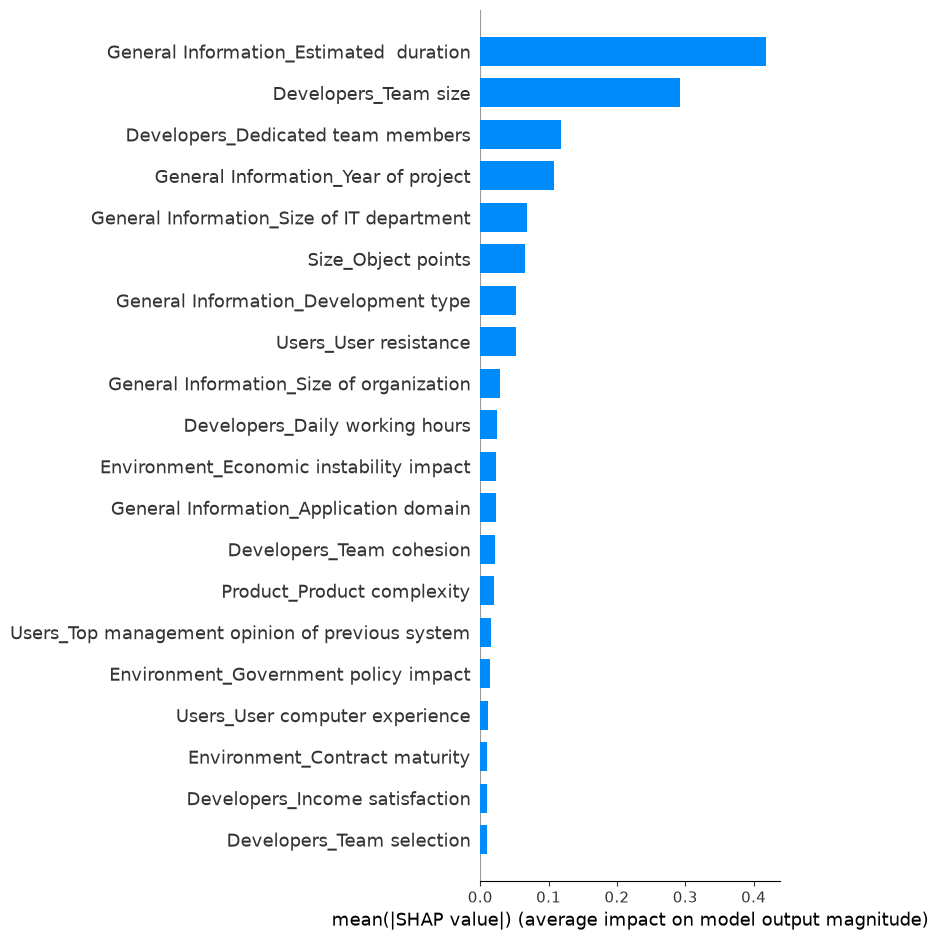

C:\Users\USER\AppData\Local\Temp\ipykernel_2076\670709888.py:351: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


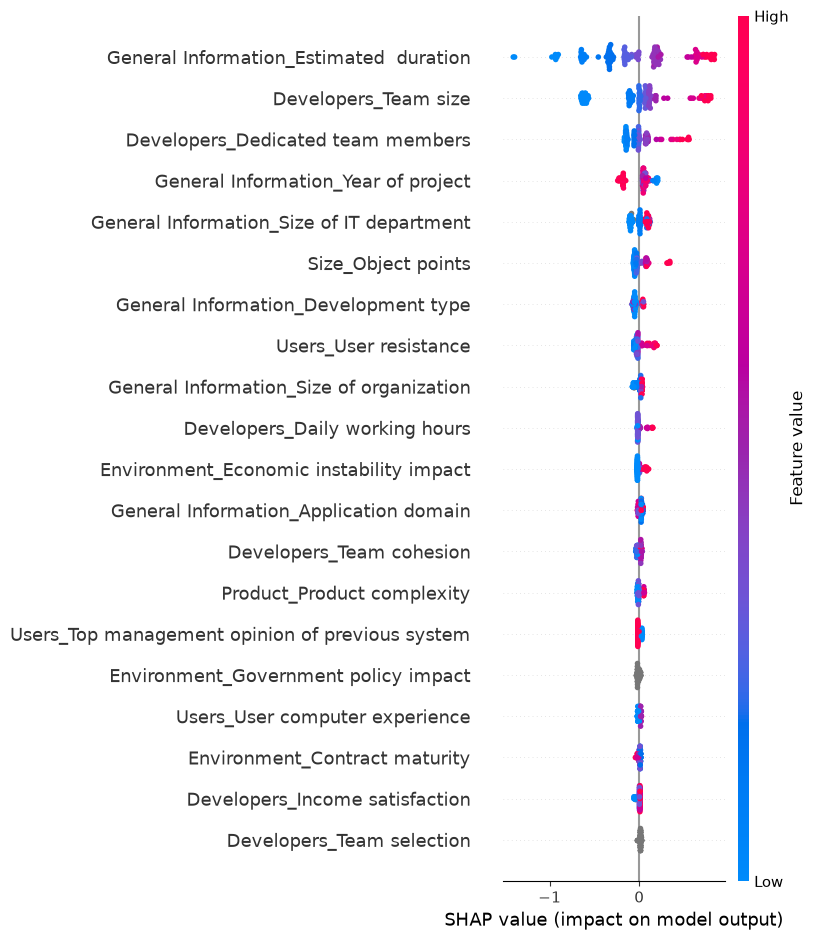


LOCAL SHAP EXPLANATION
Explaining project index: 0
Predicted effort: 2637.97 hours


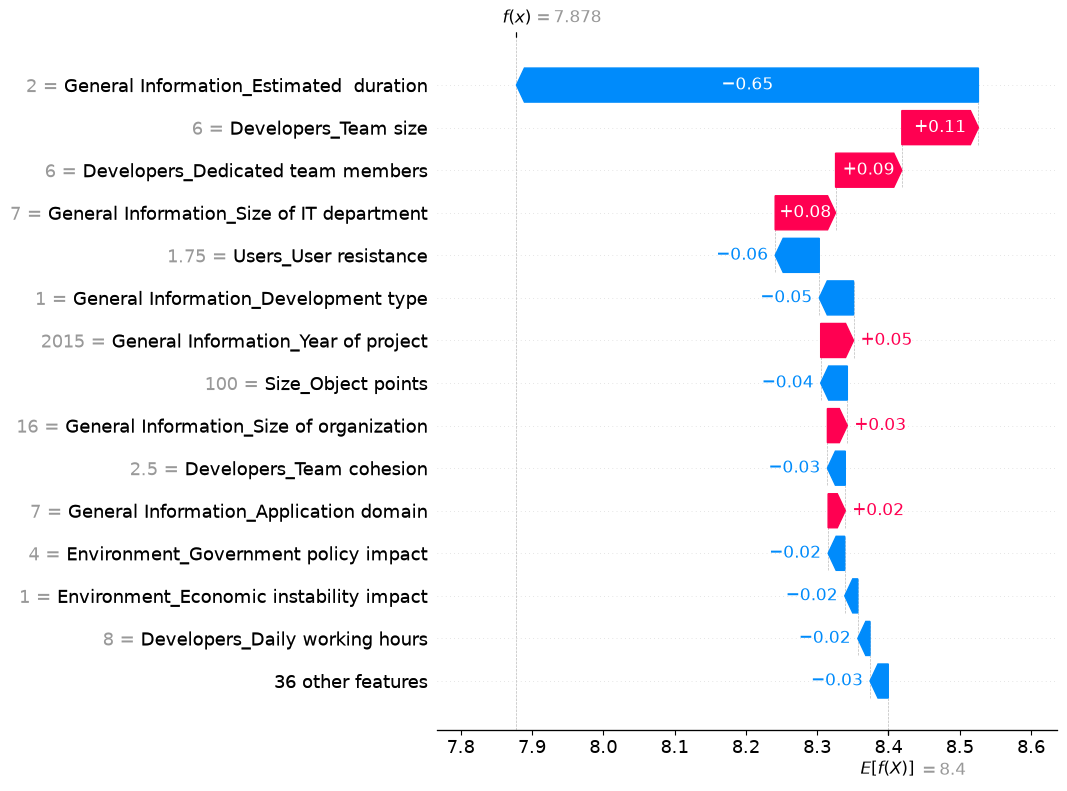


Top local feature contributions:
                                        Feature Feature_Value  SHAP_Value
        General Information_Estimated  duration           2.0   -0.647964
                           Developers_Team size             6    0.107448
              Developers_Dedicated team members             6    0.092883
      General Information_Size of IT department           7.0    0.084719
                          Users_User resistance          1.75   -0.061863
           General Information_Development type             1   -0.048096
            General Information_Year of project          2015    0.046140
                             Size_Object points         100.0   -0.037399
       General Information_Size of organization          16.0    0.027983
                       Developers_Team cohesion           2.5   -0.025141
         General Information_Application domain             7    0.024099
           Environment_Government policy impact             4   -0.023292
    

100%|██████████| 1/1 [00:01<00:00,  1.31s/it]

Query instance (original outcome : 2638.0)


,General Information_Year of project,General Information_Size of organization,General Information_Size of IT department,General Information_Estimated duration,General Information_Development type,General Information_Application domain,Size_Object points,Environment_Contract maturity,Environment_Government policy impact,Environment_Economic instability impact,...,Project_Use of standards,Project_Process reengineering,Product_Technical documentation,Product_Required reusability,Product_Performance requirements,Product_Product complexity,Product_Security requirements,Product_Reliability requirements,Product_Specified H/W,Effort_Actual_effort
0,2015,16.0,7.0,2.0,1,7,100.0,8,4,1,...,3.0,1.888889,1.0,2.0,1.0,2.0,2.0,3.0,1.0,2638.0



Diverse Counterfactual set (new outcome: [np.float64(1318.9859860982428), np.float64(2110.3775777571886)])


,General Information_Year of project,General Information_Size of organization,General Information_Size of IT department,General Information_Estimated duration,General Information_Development type,General Information_Application domain,Size_Object points,Environment_Contract maturity,Environment_Government policy impact,Environment_Economic instability impact,...,Project_Use of standards,Project_Process reengineering,Product_Technical documentation,Product_Required reusability,Product_Performance requirements,Product_Product complexity,Product_Security requirements,Product_Reliability requirements,Product_Specified H/W,Effort_Actual_effort
0,2015,16.0,7.0,0.7,1,7,100.0,8,4,1,...,3.0,1.888889,1.0,2.0,1.0,2.0,2.0,3.0,1.0,1961.744385
1,2017,16.0,7.0,2.0,1,7,100.0,8,4,1,...,1.9,1.888889,1.0,2.0,1.0,2.0,2.0,3.0,1.0,2106.080322



XAI ANALYSIS COMPLETE


In [58]:
# ============================================================
# FINAL WEIGHTED CATBOOST + XAI
#
# Frozen predictive model:
#   - 50 features
#   - log1p target
#   - Optuna-selected hyperparameters
#   - 3x weight for Actual Effort < 5,000 hours
#
# XAI model:
#   - Same frozen configuration
#   - Retrained on all 119 projects
#   - Used ONLY for explanation
#
# Explanation methods:
#   1. SHAP - global + local
#   2. DiCE - counterfactual explanations
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import dice_ml

from catboost import CatBoostRegressor


# ============================================================
# 2. FROZEN SETTINGS
# ============================================================

RANDOM_SEED = 42

WEIGHT_THRESHOLD = 5000
LOW_EFFORT_WEIGHT = 3.0

FINAL_PARAMS = {
    "depth": 3,
    "learning_rate": 0.04124173274946173,
    "iterations": 600,
    "l2_leaf_reg": 13.500717070418117,
    "random_strength": 0.41882193959396974,
    "bagging_temperature": 1.9187145799605694
}

target_col = "Effort_Actual effort"
group_col = "General Information_Organization id"
id_col = "General Information_ProjID"


# ============================================================
# 3. PREPARE DATA
# ============================================================

df_work = df_clean.copy()


# Flatten MultiIndex if necessary
if isinstance(df_work.columns, pd.MultiIndex):

    df_work.columns = [
        "_".join(
            str(level).strip()
            for level in col
            if str(level).strip() != ""
        )
        for col in df_work.columns
    ]


# Standardize column names
df_work.columns = (
    df_work.columns
    .astype(str)
    .str.replace("\xa0", " ", regex=False)
    .str.strip()
)


# Remove duplicate columns
df_work = df_work.loc[
    :,
    ~df_work.columns.duplicated()
].copy()


# ============================================================
# 4. TARGET
# ============================================================

y = pd.to_numeric(
    df_work[target_col],
    errors="coerce"
)

valid_rows = y.notna()

df = df_work.loc[
    valid_rows
].copy()

y = (
    y.loc[valid_rows]
    .reset_index(drop=True)
)


# ============================================================
# 5. FEATURES
# ============================================================

cols_to_drop = [
    target_col,
    group_col
]

if id_col in df.columns:
    cols_to_drop.append(id_col)

X = df.drop(
    columns=cols_to_drop
).copy()


# ============================================================
# 6. CATEGORICAL FEATURES
# ============================================================

nominal_cat_cols = [
    "Developers_Team selection",
    "Developers_DBMS expert availability",
    "General Information_Development type",
    "General Information_Application domain",
    "Environment_Government policy impact",
    "Environment_Developer hiring policy",
    "Environment_Developer training"
]

nominal_cat_cols = [
    col
    for col in nominal_cat_cols
    if col in X.columns
]


# CatBoost categorical variables
for col in nominal_cat_cols:

    X[col] = (
        X[col]
        .fillna("Missing")
        .astype(str)
        .str.replace(
            r"\.0$",
            "",
            regex=True
        )
    )


# ============================================================
# 7. NUMERIC FEATURES
# ============================================================

numeric_cols = [
    col
    for col in X.columns
    if col not in nominal_cat_cols
]

for col in numeric_cols:

    X[col] = pd.to_numeric(
        X[col],
        errors="coerce"
    )


# CatBoost categorical indices
cat_indices = [
    X.columns.get_loc(col)
    for col in nominal_cat_cols
]


# ============================================================
# 8. LOG TRANSFORM
# ============================================================

y_log = np.log1p(y)


# ============================================================
# 9. CREATE FINAL SAMPLE WEIGHTS
# ============================================================
#
# IMPORTANT:
# This is the same frozen rule selected during model
# development:
#
# Actual Effort < 5,000  -> 3x
# Actual Effort >= 5,000 -> 1x
#
# For the XAI model, all projects are available because
# this model is trained on the full dataset specifically
# for explanation.
# ============================================================

sample_weights = np.where(
    y.to_numpy() < WEIGHT_THRESHOLD,
    LOW_EFFORT_WEIGHT,
    1.0
)


print("=" * 75)
print("FINAL WEIGHTED CATBOOST MODEL FOR XAI")
print("=" * 75)

print(
    f"Observations:          {len(X)}"
)

print(
    f"Features:              {X.shape[1]}"
)

print(
    f"Categorical features:  {len(cat_indices)}"
)

print(
    f"Projects < 5,000h:    "
    f"{(y < WEIGHT_THRESHOLD).sum()}"
)

print(
    f"Projects >= 5,000h:   "
    f"{(y >= WEIGHT_THRESHOLD).sum()}"
)


# ============================================================
# 10. TRAIN FINAL MODEL ON ALL DATA
# ============================================================

final_model = CatBoostRegressor(

    depth=FINAL_PARAMS["depth"],

    learning_rate=FINAL_PARAMS[
        "learning_rate"
    ],

    iterations=FINAL_PARAMS[
        "iterations"
    ],

    l2_leaf_reg=FINAL_PARAMS[
        "l2_leaf_reg"
    ],

    random_strength=FINAL_PARAMS[
        "random_strength"
    ],

    bagging_temperature=FINAL_PARAMS[
        "bagging_temperature"
    ],

    cat_features=cat_indices,

    loss_function="RMSE",

    random_seed=RANDOM_SEED,

    thread_count=-1,

    verbose=False,

    allow_writing_files=False
)


final_model.fit(
    X,
    y_log,
    sample_weight=sample_weights
)


print("\nFinal XAI model trained successfully.")


# ============================================================
# 11. SHAP EXPLAINER
# ============================================================

print("\nCreating SHAP explanations...")

explainer = shap.TreeExplainer(
    final_model
)

shap_values = explainer(
    X
)


# ============================================================
# 12. GLOBAL SHAP — BAR PLOT
# ============================================================
#
# Shows the average magnitude of each feature's contribution.
# ============================================================

plt.figure(
    figsize=(10, 7)
)

shap.summary_plot(
    shap_values,
    X,
    plot_type="bar",
    show=True
)


# ============================================================
# 13. GLOBAL SHAP — BEESWARM
# ============================================================
#
# Shows both:
#   - feature importance
#   - direction of influence
#
# Positive SHAP → pushes predicted log-effort upward
# Negative SHAP → pushes predicted log-effort downward
# ============================================================

plt.figure(
    figsize=(10, 7)
)

shap.summary_plot(
    shap_values,
    X,
    show=True
)


# ============================================================
# 14. LOCAL SHAP — WATERFALL
# ============================================================
#
# Explain one project in detail.
#
# Change PROJECT_INDEX to explain another project.
# ============================================================

PROJECT_INDEX = 0

print("\n" + "=" * 75)
print("LOCAL SHAP EXPLANATION")
print("=" * 75)

print(
    f"Explaining project index: {PROJECT_INDEX}"
)


current_prediction_log = (
    final_model.predict(
        X.iloc[[PROJECT_INDEX]]
    )[0]
)

current_prediction = np.expm1(
    current_prediction_log
)

print(
    f"Predicted effort: "
    f"{current_prediction:.2f} hours"
)


shap.plots.waterfall(
    shap_values[PROJECT_INDEX],
    max_display=15,
    show=True
)


# ============================================================
# 15. OPTIONAL — DISPLAY TOP SHAP VALUES FOR THIS PROJECT
# ============================================================

local_shap = pd.DataFrame({

    "Feature":
        X.columns,

    "Feature_Value":
        X.iloc[PROJECT_INDEX].values,

    "SHAP_Value":
        shap_values[
            PROJECT_INDEX
        ].values
})

local_shap["Absolute_SHAP"] = (
    local_shap["SHAP_Value"]
    .abs()
)

local_shap = (
    local_shap
    .sort_values(
        "Absolute_SHAP",
        ascending=False
    )
)


print("\nTop local feature contributions:")

print(
    local_shap[
        [
            "Feature",
            "Feature_Value",
            "SHAP_Value"
        ]
    ]
    .head(15)
    .to_string(index=False)
)


# ============================================================
# 16. PREPARE DATA FOR DiCE
# ============================================================
#
# DiCE receives the ORIGINAL feature representation.
# We do NOT use the log-transformed target here.
# ============================================================

df_dice = X.copy()

df_dice["Effort_Actual_effort"] = (
    y.to_numpy()
)


continuous_features = [
    col
    for col in X.columns
    if col not in nominal_cat_cols
]

categorical_features = (
    nominal_cat_cols.copy()
)


# ============================================================
# 17. DiCE DATA OBJECT
# ============================================================

d = dice_ml.Data(

    dataframe=df_dice,

    continuous_features=
        continuous_features,

    categorical_features=
        categorical_features,

    outcome_name=
        "Effort_Actual_effort"
)


# ============================================================
# 18. DiCE MODEL WRAPPER
# ============================================================
#
# The CatBoost model predicts log1p(effort).
#
# DiCE needs predictions on the ORIGINAL effort scale.
#
# Therefore:
#
# CatBoost prediction
#       ↓
#     expm1()
#       ↓
# actual effort scale
# ============================================================

class CatBoostDiCEWrapper:

    def __init__(self, model):

        self.model = model


    def predict(self, df_input):

        pred_log = self.model.predict(
            df_input
        )

        return np.clip(
            np.expm1(pred_log),
            a_min=0,
            a_max=None
        )


dice_model = CatBoostDiCEWrapper(
    final_model
)


# ============================================================
# 19. CREATE DiCE EXPLAINER
# ============================================================

m = dice_ml.Model(
    model=dice_model,
    backend="sklearn",
    model_type="regressor"
)


exp = dice_ml.Dice(
    d,
    m,
    method="random"
)


# ============================================================
# 20. SELECT PROJECT FOR COUNTERFACTUAL EXPLANATION
# ============================================================

query_instance = X.iloc[
    [PROJECT_INDEX]
].copy()


current_pred = np.expm1(
    final_model.predict(
        query_instance
    )[0]
)


print("\n" + "=" * 75)
print("DiCE COUNTERFACTUAL EXPLANATION")
print("=" * 75)

print(
    f"Project index:       {PROJECT_INDEX}"
)

print(
    f"Current prediction:  "
    f"{current_pred:.2f} hours"
)


# ============================================================
# 21. DEFINE DESIRED EFFORT RANGE
# ============================================================
#
# Here we ask DiCE for alternative project configurations
# capable of reducing the predicted effort.
#
# Current prediction × 50%  to  × 80%
# ============================================================

target_range = [

    current_pred * 0.50,

    current_pred * 0.80
]


print(
    f"Desired range:       "
    f"{target_range[0]:.2f} - "
    f"{target_range[1]:.2f} hours"
)


# ============================================================
# 22. GENERATE COUNTERFACTUALS
# ============================================================

dice_exp = exp.generate_counterfactuals(

    query_instance,

    total_CFs=2,

    desired_range=target_range
)


# ============================================================
# 23. DISPLAY COUNTERFACTUALS
# ============================================================

dice_exp.visualize_as_dataframe()


print("\n" + "=" * 75)
print("XAI ANALYSIS COMPLETE")
print("=" * 75)